# Librerias

In [2]:
!pip install -r ../requirements.txt

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional
from pathlib import Path
import json

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

#from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

import shap

from lightgbm import LGBMClassifier

from bayes_opt import BayesianOptimization
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score, precision_recall_curve, roc_auc_score, roc_curve, auc, confusion_matrix

from catboost import CatBoostClassifier
from bayes_opt import BayesianOptimization
from sklearn.metrics import average_precision_score

C:\Users\Renzo\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Carga Data

In [4]:
ruta_data = Path(
    "../data/02_intermediate/Base_preselected.csv"
)

df_data = pd.read_csv(
    ruta_data,
    parse_dates=["period"]
)


print(f"Shape del dataset: " f"{df_data.shape}"
)

print(f"\nPeriodo mínimo: " f"{df_data['period'].min()}")

print(f"Periodo máximo: " f"{df_data['period'].max()}")

Shape del dataset: (1000000, 21)

Periodo mínimo: 2024-01-01 00:00:00
Periodo máximo: 2024-08-01 00:00:00


In [5]:
df_data.head()

,housing_status,device_os,current_address_months_count,address_total_history,address_stability_ratio,proposed_credit_limit,keep_alive_session,income,digital_identity_score,name_email_similarity,...,employment_status,contact_consistency,payment_type,has_other_cards,bank_branch_count_8w,intended_balcon_amount,credit_limit_income_ratio,customer_age,target,period
0,BC,linux,25.0,NaN,NaN,1500.0,1,0.3,1,0.986506,...,CB,0,AA,0,5,102.453711,5000.000000,40,0,2024-01-01
1,BC,other,89.0,NaN,NaN,1500.0,1,0.8,2,0.617426,...,CA,1,AD,0,3,-0.849551,1875.000000,20,0,2024-01-01
2,BC,windows,14.0,23.0,1.555556,200.0,0,0.8,1,0.996707,...,CA,0,AB,0,15,-1.490386,250.000000,40,0,2024-01-01
3,BC,linux,14.0,25.0,1.272727,200.0,1,0.6,1,0.475100,...,CA,0,AB,0,11,-1.863101,333.333333,30,0,2024-01-01
4,BC,other,29.0,NaN,NaN,200.0,0,0.9,3,0.842307,...,CA,1,AA,0,1,47.152498,222.222222,40,0,2024-01-01


In [6]:
df_data.dtypes

housing_status                          object
device_os                               object
current_address_months_count           float64
address_total_history                  float64
address_stability_ratio                float64
proposed_credit_limit                  float64
keep_alive_session                       int64
income                                 float64
digital_identity_score                   int64
name_email_similarity                  float64
bank_months_count                      float64
employment_status                       object
contact_consistency                      int64
payment_type                            object
has_other_cards                          int64
bank_branch_count_8w                     int64
intended_balcon_amount                 float64
credit_limit_income_ratio              float64
customer_age                             int64
target                                   int64
period                          datetime64[ns]
dtype: object

In [7]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [8]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

housing_status                       0
device_os                            0
current_address_months_count      4254
address_total_history           717088
address_stability_ratio         717088
proposed_credit_limit                0
keep_alive_session                   0
income                               0
digital_identity_score               0
name_email_similarity                0
bank_months_count               253635
employment_status                    0
contact_consistency                  0
payment_type                         0
has_other_cards                      0
bank_branch_count_8w                 0
intended_balcon_amount               0
credit_limit_income_ratio            0
customer_age                         0
target                               0
period                               0
dtype: int64

In [9]:
df_data.head()

,housing_status,device_os,current_address_months_count,address_total_history,address_stability_ratio,proposed_credit_limit,keep_alive_session,income,digital_identity_score,name_email_similarity,bank_months_count,employment_status,contact_consistency,payment_type,has_other_cards,bank_branch_count_8w,intended_balcon_amount,credit_limit_income_ratio,customer_age,target,period
0,BC,linux,25.0,NaN,NaN,1500.0,1,0.3,1,0.986506,9.0,CB,0,AA,0,5,102.453711,5000.000000,40,0,2024-01-01
1,BC,other,89.0,NaN,NaN,1500.0,1,0.8,2,0.617426,2.0,CA,1,AD,0,3,-0.849551,1875.000000,20,0,2024-01-01
2,BC,windows,14.0,23.0,1.555556,200.0,0,0.8,1,0.996707,30.0,CA,0,AB,0,15,-1.490386,250.000000,40,0,2024-01-01
3,BC,linux,14.0,25.0,1.272727,200.0,1,0.6,1,0.475100,1.0,CA,0,AB,0,11,-1.863101,333.333333,30,0,2024-01-01
4,BC,other,29.0,NaN,NaN,200.0,0,0.9,3,0.842307,26.0,CA,1,AA,0,1,47.152498,222.222222,40,0,2024-01-01


# Funcion IV WOE

In [10]:
from optbinning import OptimalBinning, BinningProcess

def plot_analisis(data, analysis_type, analysis_columns, target, umbral_iv):
    list1 = []
    list2 = []
    tabla_f = pd.DataFrame()
    data[target] = data[target].astype(int)

    # Función para formatear los bins
    def format_bin(bin_value):
        if isinstance(bin_value, tuple):  # Si es un intervalo (tupla)
            return f"[{round(bin_value[0], 4)}, {round(bin_value[1], 4)})"
        elif isinstance(bin_value, (int, float)):  # Si es un número
            return round(bin_value, 4)
        else:  # Si es una cadena (por ejemplo, 'Missing' o 'Special')
            return bin_value

    for columnName in analysis_columns:
        x = data[columnName].values
        y = data[target]
        optb = OptimalBinning(name=columnName, dtype=analysis_type, solver="cp")
        optb.fit(x, y)
        binning_table = optb.binning_table

        tabla = binning_table.build()

        # Formatear los bins a 4 decimales
        if analysis_type == 'numerical':
            tabla['Bin'] = tabla['Bin'].apply(format_bin)

        b = tabla[tabla.index == 'Totals']['IV'][0]
        list1.append(b)
        list2.append(columnName)
        tabla_ = tabla[['Bin', 'WoE']].iloc[:-3]
        tabla_['variable'] = columnName
        tabla_f = pd.concat([tabla_f, tabla_], axis=0)

        print('variable ' + columnName)
        print('---------------------------------------------------------')

        # Imprimir la tabla con 4 decimales
        with pd.option_context('display.float_format', '{:.4f}'.format):
            print(tabla)

        binning_table.plot('event_rate')

    df = pd.DataFrame(pd.Series(list1, index=list2))
    df = df.rename(columns={0: 'IV'})
    df = df[df['IV'] > umbral_iv].sort_values(by='IV', axis=0, ascending=False).reset_index()

    return df

# Cargar sets de vars

In [11]:
# ============================================================
# Cargar metadata de selección de variables
# ============================================================

ruta_metadata = Path("../data/06_models/feature_sets.json")

with open(ruta_metadata, "r", encoding="utf-8") as f:
    feature_sets = json.load(f)


# ============================================================
# Sets principales
# ============================================================

FEATURES_FINAL_IV = feature_sets["FEATURES_FINAL_IV"]
FEATURES_FINAL = feature_sets["FEATURES_FINAL"]

SENSITIVE_FEATURES = feature_sets["SENSITIVE_FEATURES"]
FAIRNESS_MONITOR_FEATURES = feature_sets["FAIRNESS_MONITOR_FEATURES"]
PROXY_CANDIDATES = feature_sets["PROXY_CANDIDATES"]

FAIRNESS_FEATURES = feature_sets["FAIRNESS_FEATURES"]
FEATURES_MODEL_FAIRNESS = feature_sets["FEATURES_MODEL_FAIRNESS"]


# ============================================================
# Metadata del preprocessing
# ============================================================

CAT_FEATURES = feature_sets["CAT_FEATURES"]
NUM_FEATURES = feature_sets["NUM_FEATURES"]

COLS_NUMERICAS_CONSTANTE = feature_sets["COLS_NUMERICAS_CONSTANTE"]
COLS_NUMERICAS_MEDIANA = feature_sets["COLS_NUMERICAS_MEDIANA"]

CAT_FEATURES_CATBOOST = feature_sets["CAT_FEATURES_CATBOOST"]


# ============================================================
# Resumen
# ============================================================

print(f"Features post-IV: {len(FEATURES_FINAL_IV)}")
print(f"FEATURES_FINAL: {len(FEATURES_FINAL)}")

print(f"SENSITIVE_FEATURES: {len(SENSITIVE_FEATURES)}")
print(f"FAIRNESS_MONITOR_FEATURES: {len(FAIRNESS_MONITOR_FEATURES)}")
print(f"PROXY_CANDIDATES: {len(PROXY_CANDIDATES)}")

print(f"Variables numéricas: {len(NUM_FEATURES)}")
print(f"Variables categóricas: {len(CAT_FEATURES)}")
print(f"Variables Fairness: {len(FAIRNESS_FEATURES)}")

Features post-IV: 19
FEATURES_FINAL: 18
SENSITIVE_FEATURES: 1
FAIRNESS_MONITOR_FEATURES: 2
PROXY_CANDIDATES: 3
Variables numéricas: 14
Variables categóricas: 4
Variables Fairness: 3


# Split Data

In [12]:
# ============================================================
# Split temporal
# ============================================================

# Train:
# 2024-01-01 a 2024-05-31

train_data = df_data[
    (df_data["period"] >= "2024-01-01")
    & (df_data["period"] <= "2024-05-31")
].copy()


# Validation:
# 2024-06-01 a 2024-06-30

val_data = df_data[
    (df_data["period"] >= "2024-06-01")
    & (df_data["period"] <= "2024-06-30")
].copy()


# Test:
# 2024-07-01 a 2024-07-31

test_data = df_data[
    (df_data["period"] >= "2024-07-01")
    & (df_data["period"] <= "2024-07-31")
].copy()


# OOT:
# 2024-08-01 a 2024-08-31

oot_data = df_data[
    (df_data["period"] >= "2024-08-01")
    & (df_data["period"] <= "2024-08-31")
].copy()


# ============================================================
# Resultados
# ============================================================

print(f"Train: {len(train_data):,}")

print(f"Validation: {len(val_data):,}")

print(f"Test: {len(test_data):,}")

print(f"OOT: {len(oot_data):,}")

print(f"\nTotal: "
    f"{len(train_data) + len(val_data) + len(test_data) + len(oot_data):,}"
)

Train: 675,666
Validation: 119,323
Test: 108,168
OOT: 96,843

Total: 1,000,000


In [13]:
print(train_data["target"].mean())
print(val_data["target"].mean())
print(test_data["target"].mean())
print(oot_data["target"].mean())

0.009975342846909568
0.01182504630289215
0.013405073589231566
0.014745515938167962


In [14]:
# ============================================================
# Validación temporal
# ============================================================

resumen_split = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test",
        "OOT"
    ],
    "N": [
        len(train_data),
        len(val_data),
        len(test_data),
        len(oot_data)
    ],
    "Periodo_min": [
        train_data["period"].min(),
        val_data["period"].min(),
        test_data["period"].min(),
        oot_data["period"].min()
    ],
    "Periodo_max": [
        train_data["period"].max(),
        val_data["period"].max(),
        test_data["period"].max(),
        oot_data["period"].max()
    ],
    "Fraud_rate": [
        train_data["target"].mean(),
        val_data["target"].mean(),
        test_data["target"].mean(),
        oot_data["target"].mean()
    ]
})

display(resumen_split)

,Dataset,N,Periodo_min,Periodo_max,Fraud_rate
0,Train,675666,2024-01-01,2024-05-01,0.009975
1,Validation,119323,2024-06-01,2024-06-01,0.011825
2,Test,108168,2024-07-01,2024-07-01,0.013405
3,OOT,96843,2024-08-01,2024-08-01,0.014746


In [15]:
# ============================================================
# Variables predictoras y target
# ============================================================

FEATURES = FEATURES_FINAL.copy()


# ============================================================
# Train
# ============================================================

X_train = train_data[
    FEATURES
].copy()

y_train = train_data[
    "target"
].copy()


# ============================================================
# Validation
# ============================================================

X_val = val_data[
    FEATURES
].copy()

y_val = val_data[
    "target"
].copy()


# ============================================================
# Test
# ============================================================

X_test = test_data[
    FEATURES
].copy()

y_test = test_data[
    "target"
].copy()


# ============================================================
# OOT
# ============================================================

X_oot = oot_data[
    FEATURES
].copy()

y_oot = oot_data[
    "target"
].copy()


print(
    "X_train:",
    X_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "X_oot:",
    X_oot.shape
)

X_train: (675666, 18)
X_val: (119323, 18)
X_test: (108168, 18)
X_oot: (96843, 18)


In [16]:
# ============================================================
# Información para análisis posterior de Fairness
# ============================================================

fairness_train = train_data[
    FAIRNESS_FEATURES
].copy()

fairness_val = val_data[
    FAIRNESS_FEATURES
].copy()

fairness_test = test_data[
    FAIRNESS_FEATURES
].copy()

fairness_oot = oot_data[
    FAIRNESS_FEATURES
].copy()


print(
    "Fairness Test:",
    fairness_test.shape
)

print(
    "Fairness OOT:",
    fairness_oot.shape
)

Fairness Test: (108168, 3)
Fairness OOT: (96843, 3)


# Preprocessing

In [17]:
# ============================================================
# Cargar preprocessors ajustados en Feature Engineering
# ============================================================

ruta_modelos = Path(
    "../data/06_models"
)


# ------------------------------------------------------------
# OHE
# ------------------------------------------------------------

with open(
    ruta_modelos / "prep_tree_ohe.pkl",
    "rb"
) as f:

    prep_tree_ohe = pickle.load(f)


# ------------------------------------------------------------
# WOE
# ------------------------------------------------------------

with open(
    ruta_modelos / "prep_tree_woe.pkl",
    "rb"
) as f:

    prep_tree_woe = pickle.load(f)


# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

with open(
    ruta_modelos / "prep_catboost.pkl",
    "rb"
) as f:

    prep_catboost = pickle.load(f)


print(
    "Preprocessors cargados correctamente."
)

Preprocessors cargados correctamente.


In [18]:
# ============================================================
# Preprocessing OHE
# ============================================================

FEATURES_OHE = (
    prep_tree_ohe
    .get_feature_names_out()
)


X_train_ohe = pd.DataFrame(
    prep_tree_ohe.transform(
        X_train
    ),
    columns=FEATURES_OHE,
    index=X_train.index
)


X_val_ohe = pd.DataFrame(
    prep_tree_ohe.transform(
        X_val
    ),
    columns=FEATURES_OHE,
    index=X_val.index
)


X_test_ohe = pd.DataFrame(
    prep_tree_ohe.transform(
        X_test
    ),
    columns=FEATURES_OHE,
    index=X_test.index
)


X_oot_ohe = pd.DataFrame(
    prep_tree_ohe.transform(
        X_oot
    ),
    columns=FEATURES_OHE,
    index=X_oot.index
)


print(
    "Train OHE:",
    X_train_ohe.shape
)

print(
    "Val OHE:",
    X_val_ohe.shape
)

print(
    "Test OHE:",
    X_test_ohe.shape
)

print(
    "OOT OHE:",
    X_oot_ohe.shape
)

Train OHE: (675666, 38)
Val OHE: (119323, 38)
Test OHE: (108168, 38)
OOT OHE: (96843, 38)


In [19]:
# ============================================================
# Preprocessing WOE
# ============================================================

FEATURES_WOE = (
    COLS_NUMERICAS_CONSTANTE
    + COLS_NUMERICAS_MEDIANA
    + CAT_FEATURES
)


X_train_woe = pd.DataFrame(
    prep_tree_woe.transform(
        X_train
    ),
    columns=FEATURES_WOE,
    index=X_train.index
)


X_val_woe = pd.DataFrame(
    prep_tree_woe.transform(
        X_val
    ),
    columns=FEATURES_WOE,
    index=X_val.index
)


X_test_woe = pd.DataFrame(
    prep_tree_woe.transform(
        X_test
    ),
    columns=FEATURES_WOE,
    index=X_test.index
)


X_oot_woe = pd.DataFrame(
    prep_tree_woe.transform(
        X_oot
    ),
    columns=FEATURES_WOE,
    index=X_oot.index
)


print(
    "Train WOE:",
    X_train_woe.shape
)

print(
    "Val WOE:",
    X_val_woe.shape
)

print(
    "Test WOE:",
    X_test_woe.shape
)

print(
    "OOT WOE:",
    X_oot_woe.shape
)

Train WOE: (675666, 18)
Val WOE: (119323, 18)
Test WOE: (108168, 18)
OOT WOE: (96843, 18)


In [20]:
# ============================================================
# Preprocessing CatBoost
# ============================================================

X_train_cat = prep_catboost.transform(
    X_train
)

X_val_cat = prep_catboost.transform(
    X_val
)

X_test_cat = prep_catboost.transform(
    X_test
)

X_oot_cat = prep_catboost.transform(
    X_oot
)


# ============================================================
# Garantizar que categóricas permanezcan como strings
# ============================================================

for col in CAT_FEATURES_CATBOOST:

    X_train_cat[col] = (
        X_train_cat[col]
        .astype(str)
    )

    X_val_cat[col] = (
        X_val_cat[col]
        .astype(str)
    )

    X_test_cat[col] = (
        X_test_cat[col]
        .astype(str)
    )

    X_oot_cat[col] = (
        X_oot_cat[col]
        .astype(str)
    )


print(
    "Train CatBoost:",
    X_train_cat.shape
)

print(
    "Val CatBoost:",
    X_val_cat.shape
)

print(
    "Test CatBoost:",
    X_test_cat.shape
)

print(
    "OOT CatBoost:",
    X_oot_cat.shape
)

Train CatBoost: (675666, 18)
Val CatBoost: (119323, 18)
Test CatBoost: (108168, 18)
OOT CatBoost: (96843, 18)


In [21]:
# ============================================================
# Validaciones de preprocessing
# ============================================================

# ------------------------------------------------------------
# OHE
# ------------------------------------------------------------

assert not X_train_ohe.isna().any().any()
assert np.isfinite(
    X_train_ohe.to_numpy()
).all()


# ------------------------------------------------------------
# WOE
# ------------------------------------------------------------

assert not X_train_woe.isna().any().any()
assert np.isfinite(
    X_train_woe.to_numpy()
).all()


# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

assert not X_train_cat.isna().any().any()


print(
    "Preprocessing validado correctamente."
)

print(
    f"\nOHE:      "
    f"{X_train_ohe.shape[1]} features"
)

print(
    f"WOE:      "
    f"{X_train_woe.shape[1]} features"
)

print(
    f"CatBoost: "
    f"{X_train_cat.shape[1]} features"
)

Preprocessing validado correctamente.

OHE:      38 features
WOE:      18 features
CatBoost: 18 features


# Balanceo de clases

## Undersampling

In [22]:
train_data.columns

Index(['housing_status', 'device_os', 'current_address_months_count',
       'address_total_history', 'address_stability_ratio',
       'proposed_credit_limit', 'keep_alive_session', 'income',
       'digital_identity_score', 'name_email_similarity', 'bank_months_count',
       'employment_status', 'contact_consistency', 'payment_type',
       'has_other_cards', 'bank_branch_count_8w', 'intended_balcon_amount',
       'credit_limit_income_ratio', 'customer_age', 'target', 'period'],
      dtype='object')

In [23]:
# ============================================================
# Balanceo de clases
# Random Undersampling por periodo
# ============================================================

RANDOM_STATE = 42

indices_resampled = []


for periodo, group in train_data.groupby(
    "period",
    sort=True
):

    y_group = group[
        "target"
    ].copy()

    # --------------------------------------------------------
    # X auxiliar:
    # solo necesitamos que RandomUnderSampler seleccione filas.
    # No estamos haciendo preprocessing aquí.
    # --------------------------------------------------------

    X_aux = pd.DataFrame(
        {
            "row_id": group.index
        },
        index=group.index
    )


    rus = RandomUnderSampler(
        random_state=RANDOM_STATE
    )


    rus.fit_resample(
        X_aux,
        y_group
    )


    # sample_indices_ contiene posiciones dentro del grupo
    indices_periodo = (
        group
        .iloc[rus.sample_indices_]
        .index
        .tolist()
    )


    indices_resampled.extend(
        indices_periodo
    )

In [24]:
# ============================================================
# Target balanceado
# ============================================================

y_train_resampled = (
    y_train
    .loc[indices_resampled]
    .copy()
)


period_train_resampled = (
    train_data
    .loc[
        indices_resampled,
        "period"
    ]
    .copy()
)

In [25]:
# ============================================================
# Mismas observaciones para los tres preprocessings
# ============================================================

X_train_ohe_resampled = (
    X_train_ohe
    .loc[indices_resampled]
    .copy()
)


X_train_woe_resampled = (
    X_train_woe
    .loc[indices_resampled]
    .copy()
)


X_train_cat_resampled = (
    X_train_cat
    .loc[indices_resampled]
    .copy()
)

In [26]:
# ============================================================
# Reset de índices
# ============================================================

X_train_ohe_resampled = (
    X_train_ohe_resampled
    .reset_index(drop=True)
)

X_train_woe_resampled = (
    X_train_woe_resampled
    .reset_index(drop=True)
)

X_train_cat_resampled = (
    X_train_cat_resampled
    .reset_index(drop=True)
)

y_train_resampled = (
    y_train_resampled
    .reset_index(drop=True)
)

period_train_resampled = (
    period_train_resampled
    .reset_index(drop=True)
)

In [27]:
# ============================================================
# Validación del undersampling
# ============================================================

print(
    "Distribución ANTES del undersampling:"
)

print(
    y_train.value_counts()
)


print(
    "\nProporción ANTES:"
)

print(
    y_train.value_counts(
        normalize=True
    )
)


print(
    "\nDistribución DESPUÉS del undersampling:"
)

print(
    y_train_resampled.value_counts()
)


print(
    "\nProporción DESPUÉS:"
)

print(
    y_train_resampled.value_counts(
        normalize=True
    )
)

Distribución ANTES del undersampling:
target
0    668926
1      6740
Name: count, dtype: int64

Proporción ANTES:
target
0    0.990025
1    0.009975
Name: proportion, dtype: float64

Distribución DESPUÉS del undersampling:
target
0    6740
1    6740
Name: count, dtype: int64

Proporción DESPUÉS:
target
0    0.5
1    0.5
Name: proportion, dtype: float64


In [28]:
# ============================================================
# Distribución por periodo después del undersampling
# ============================================================

df_balance_periodo = pd.DataFrame({
    "period": period_train_resampled,
    "target": y_train_resampled
})


tabla_balance_periodo = (
    df_balance_periodo
    .groupby(
        ["period", "target"]
    )
    .size()
    .unstack(
        fill_value=0
    )
)


display(
    tabla_balance_periodo
)

target,0,1
period,,
2024-01-01,1500,1500
2024-02-01,1198,1198
2024-03-01,1198,1198
2024-04-01,1392,1392
2024-05-01,1452,1452


In [29]:
# ============================================================
# Validar que los cinco modelos recibirán
# exactamente el mismo número de observaciones
# ============================================================

n_resampled = len(
    y_train_resampled
)


assert len(
    X_train_ohe_resampled
) == n_resampled

assert len(
    X_train_woe_resampled
) == n_resampled

assert len(
    X_train_cat_resampled
) == n_resampled


print(
    f"Observaciones Train balanceadas: "
    f"{n_resampled:,}"
)

print(
    f"OHE:      "
    f"{X_train_ohe_resampled.shape}"
)

print(
    f"WOE:      "
    f"{X_train_woe_resampled.shape}"
)

print(
    f"CatBoost: "
    f"{X_train_cat_resampled.shape}"
)

print(
    "\nLas tres representaciones utilizan "
    "exactamente la misma muestra de Train."
)

Observaciones Train balanceadas: 13,480
OHE:      (13480, 38)
WOE:      (13480, 18)
CatBoost: (13480, 18)

Las tres representaciones utilizan exactamente la misma muestra de Train.


In [30]:
# ============================================================
# Distribuciones naturales de evaluación
# ============================================================

distribuciones_evaluacion = pd.DataFrame({
    "Dataset": [
        "Validation",
        "Test",
        "OOT"
    ],
    "N": [
        len(y_val),
        len(y_test),
        len(y_oot)
    ],
    "Fraudes": [
        y_val.sum(),
        y_test.sum(),
        y_oot.sum()
    ],
    "Fraud_rate": [
        y_val.mean(),
        y_test.mean(),
        y_oot.mean()
    ]
})


display(
    distribuciones_evaluacion
)

,Dataset,N,Fraudes,Fraud_rate
0,Validation,119323,1411,0.011825
1,Test,108168,1450,0.013405
2,OOT,96843,1428,0.014746


# Modelos

In [31]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def plot_confusion_matrix_heatmap(
    y_true,
    y_pred_proba,
    model_name="Modelo",
    threshold=0.5
):
    """
    Visualiza la matriz de confusión y calcula métricas
    de clasificación.
    """

    if not 0 <= threshold <= 1:
        raise ValueError("El threshold debe estar entre 0 y 1.")

    # Predicciones binarias
    y_pred = (np.asarray(y_pred_proba) >= threshold).astype(int)

    # Matriz de confusión
    conf_matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

    tn, fp, fn, tp = conf_matrix.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    # Métricas independientes del threshold
    pr_auc = average_precision_score(y_true, y_pred_proba)
    auc_roc = roc_auc_score(y_true, y_pred_proba)

    # Métricas dependientes del threshold
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Matriz de confusión
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        square=True,
        cbar=True
    )

    plt.title(
        f"Matriz de Confusión - {model_name}\n"
        f"Threshold: {threshold:.2f} | "
        f"PR-AUC: {pr_auc:.3f} | "
        f"ROC-AUC: {auc_roc:.3f} | "
        f"F1: {f1:.3f}"
    )

    plt.xlabel("Predicción")
    plt.ylabel("Actual")
    plt.xticks([0.5, 1.5], ["Clase 0", "Clase 1"])
    plt.yticks([0.5, 1.5], ["Clase 0", "Clase 1"], rotation=0)

    plt.tight_layout()
    plt.show()

    # Reporte de clasificación
    print(f"\nReporte de Clasificación - {model_name}")
    print(f"Threshold utilizado: {threshold:.2f}\n")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Clase 0", "Clase 1"],
            digits=4,
            zero_division=0
        )
    )

    print(f"PR-AUC:    {pr_auc:.4f}")
    print(f"ROC-AUC:   {auc_roc:.4f}")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"FPR:       {fpr:.4f}")

    # Guardar todas las métricas
    return {
        "model_name": model_name,
        "threshold": threshold,
        "pr_auc": pr_auc,
        "auc_roc": auc_roc,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": conf_matrix,
        "y_pred": y_pred,
        "fpr": fpr,
    }

In [32]:
# ============================================================
# Selección de threshold usando exclusivamente Validation
# ============================================================

def encontrar_mejor_threshold(
    y_true,
    y_pred_proba,
    thresholds=None
):
    """
    Busca el threshold que maximiza F1-Score
    sobre el conjunto de Validation.
    """

    if thresholds is None:
        thresholds = np.arange(
            0.01,
            1.00,
            0.01
        )

    resultados = []

    for threshold in thresholds:

        y_pred = (
            np.asarray(y_pred_proba)
            >= threshold
        ).astype(int)

        resultados.append({
            "threshold": threshold,

            "precision": precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

            "recall": recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

            "f1": f1_score(
                y_true,
                y_pred,
                zero_division=0
            )
        })


    df_thresholds = pd.DataFrame(
        resultados
    )


    mejor_fila = (
        df_thresholds
        .sort_values(
            "f1",
            ascending=False
        )
        .iloc[0]
    )


    mejor_threshold = float(
        mejor_fila["threshold"]
    )


    print(
        f"Mejor threshold según Validation: "
        f"{mejor_threshold:.2f}"
    )

    print(
        f"Precision: "
        f"{mejor_fila['precision']:.4f}"
    )

    print(
        f"Recall: "
        f"{mejor_fila['recall']:.4f}"
    )

    print(
        f"F1: "
        f"{mejor_fila['f1']:.4f}"
    )


    return mejor_threshold, df_thresholds

## XGBoost

### Funcion Objetivo

In [33]:
# ============================================================
# Factory de función objetivo XGBoost
# ============================================================

def crear_xgb_objective(
    X_train_model,
    y_train_model,
    X_val_model,
    y_val_model
):
    """
    Crea una función objetivo de Bayesian Optimization
    para una representación específica de los datos.

    La optimización se realiza maximizando PR-AUC
    sobre Validation.
    """

    def xgb_evaluate(
        max_depth,
        gamma,
        colsample_bytree,
        learning_rate,
        n_estimators,
        subsample,
        min_child_weight,
        reg_alpha,
        reg_lambda
    ):

        params = {

            # -----------------------------------------------
            # Objetivo
            # -----------------------------------------------

            "objective": "binary:logistic",

            "eval_metric": "aucpr",


            # -----------------------------------------------
            # Hyperparameters
            # -----------------------------------------------

            "max_depth": int(
                round(max_depth)
            ),

            "gamma": gamma,

            "colsample_bytree":
                colsample_bytree,

            "learning_rate":
                learning_rate,

            "n_estimators": int(
                round(n_estimators)
            ),

            "subsample":
                subsample,

            "min_child_weight":
                min_child_weight,

            "reg_alpha":
                reg_alpha,

            "reg_lambda":
                reg_lambda,


            # -----------------------------------------------
            # Configuración
            # -----------------------------------------------

            # Train ya fue balanceado mediante RUS.
            # Por eso NO utilizamos scale_pos_weight.

            "random_state": 150718,

            "n_jobs": -1,

            "tree_method": "hist"
        }


        model = XGBClassifier(
            **params
        )


        # -----------------------------------------------
        # Entrenar sobre Train balanceado
        # -----------------------------------------------

        model.fit(
            X_train_model,
            y_train_model
        )


        # -----------------------------------------------
        # Evaluar sobre Validation natural
        # -----------------------------------------------

        y_val_pred_proba = (
            model
            .predict_proba(
                X_val_model
            )[:, 1]
        )


        # -----------------------------------------------
        # Métrica objetivo
        # -----------------------------------------------

        pr_auc = (
            average_precision_score(
                y_val_model,
                y_val_pred_proba
            )
        )


        return pr_auc


    return xgb_evaluate

### Espacio de busqueda

In [34]:
# ============================================================
# Espacio de búsqueda XGBoost
# ============================================================

params_pbounds_xgb = {
    "max_depth": (3, 7),

    "gamma": (0,10),

    "colsample_bytree": (0.5, 1.0),

    "learning_rate": (0.01, 0.15),

    "n_estimators": (100,500),

    "subsample": (0.6,1.0),

    "min_child_weight": (1,40),

    "reg_alpha": (0,20),

    "reg_lambda": (1,20)
}

### XGBoost + OHE

#### Funcion Objetivo

In [35]:
# ============================================================
# XGBoost + OHE
# Función objetivo
# ============================================================

xgb_evaluate_ohe = crear_xgb_objective(
    X_train_model= X_train_ohe_resampled,
    y_train_model= y_train_resampled,
    X_val_model=X_val_ohe,
    y_val_model=y_val
)

#### Optimizacion Bayesiana

In [36]:
# ============================================================
# Bayesian Optimization
# XGBoost + OHE
# ============================================================

xgb_bo_ohe = BayesianOptimization(
    f=xgb_evaluate_ohe,
    pbounds=params_pbounds_xgb,
    random_state=42,
    verbose=2
)


xgb_bo_ohe.maximize(
    init_points=5,
    n_iter=15
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1503    | 0.6873    | 9.507     | 0.1125    | 5.395     | 7.085     | 162.4     | 1.162     | 17.46     | 0.8404    |
| 2         | 0.1455    | 0.854     | 0.2058    | 0.1458    | 6.33      | 9.281     | 172.7     | 3.668     | 6.781     | 0.8099    |
| 3         | 0.1517    | 0.716     | 2.912     | 0.09566   | 3.558     | 12.39     | 246.5     | 9.121     | 15.92     | 0.6799    |
| 4         | 0.1129    | 0.7571    | 5.924     | 0.0165    | 5.43      | 7.65      | 126.0     | 18.98     | 19.35     | 0.9234    |
| 5         | 0.1529    | 0.6523    | 0.9767    | 0.1058    | 4.761     | 5.759     | 298.1     | 0.6878    | 18.28     | 0.7035    |
| 6         | 0.1515    | 0.5684    | 1.154     | 0.1394    | 

#### Mejores hiperparametros

In [37]:
# ============================================================
# Mejores parámetros XGBoost + OHE
# ============================================================

best_params_xgb_ohe = (
    xgb_bo_ohe
    .max["params"]
    .copy()
)


# Parámetros enteros
best_params_xgb_ohe[
    "max_depth"
] = int(
    round(
        best_params_xgb_ohe[
            "max_depth"
        ]
    )
)


best_params_xgb_ohe[
    "n_estimators"
] = int(
    round(
        best_params_xgb_ohe[
            "n_estimators"
        ]
    )
)


print(
    "\nMejores parámetros "
    "XGBoost + OHE:"
)

for parametro, valor in (
    best_params_xgb_ohe.items()
):

    print(f"{parametro}: {valor}")


print(
    "\nMejor PR-AUC Validation:",
    xgb_bo_ohe.max["target"]
)


Mejores parámetros XGBoost + OHE:
colsample_bytree: 0.6777347366051072
gamma: 2.435124693066324
learning_rate: 0.14436261421513047
max_depth: 4
min_child_weight: 3.124363235702523
n_estimators: 249
reg_alpha: 3.1655417162802157
reg_lambda: 8.47436017691087
subsample: 0.7370795295620072

Mejor PR-AUC Validation: 0.1588981228455864


#### Training

In [38]:
# ============================================================
# Modelo final XGBoost + OHE
# ============================================================

xgb_ohe = XGBClassifier(
    **best_params_xgb_ohe,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=150718,
    n_jobs=-1,
    tree_method="hist"
)


xgb_ohe.fit(
    X_train_ohe_resampled,
    y_train_resampled
)


print("XGBoost + OHE entrenado correctamente.")

XGBoost + OHE entrenado correctamente.


#### Probabilidades Train y Val

In [39]:
# ============================================================
# Predicciones XGBoost + OHE
# Train y Validation
# ============================================================

y_train_pred_proba_xgb_ohe = (
    xgb_ohe
    .predict_proba(
        X_train_ohe_resampled
    )[:, 1]
)


y_val_pred_proba_xgb_ohe = (
    xgb_ohe
    .predict_proba(
        X_val_ohe
    )[:, 1]
)

#### Threshold

In [40]:
# ============================================================
# Threshold XGBoost + OHE
# Seleccionado SOLO con Validation
# ============================================================

threshold_xgb_ohe, df_threshold_xgb_ohe = (
    encontrar_mejor_threshold(

        y_true=y_val,

        y_pred_proba=
            y_val_pred_proba_xgb_ohe
    )
)

Mejor threshold según Validation: 0.92
Precision: 0.2161
Recall: 0.2764
F1: 0.2425


#### Evaluation

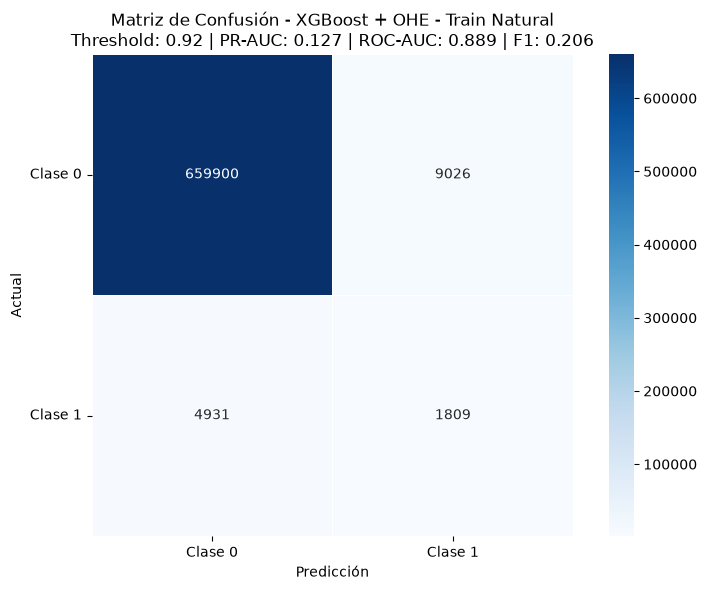


Reporte de Clasificación - XGBoost + OHE - Train Natural
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9926    0.9865    0.9895    668926
     Clase 1     0.1670    0.2684    0.2059      6740

    accuracy                         0.9793    675666
   macro avg     0.5798    0.6275    0.5977    675666
weighted avg     0.9843    0.9793    0.9817    675666

PR-AUC:    0.1268
ROC-AUC:   0.8885
Accuracy:  0.9793
Precision: 0.1670
Recall:    0.2684
F1-Score:  0.2059
FPR:       0.0135


In [41]:
# ============================================================
# XGBoost + OHE
# Train Natural Evaluation
# ============================================================

y_train_pred_proba_xgb_ohe = (
    xgb_ohe
    .predict_proba(
        X_train_ohe
    )[:, 1]
)


result_train_xgb_ohe = (
    plot_confusion_matrix_heatmap(
        y_true=y_train,
        y_pred_proba=y_train_pred_proba_xgb_ohe,
        model_name="XGBoost + OHE - Train Natural",
        threshold=threshold_xgb_ohe
    )
)

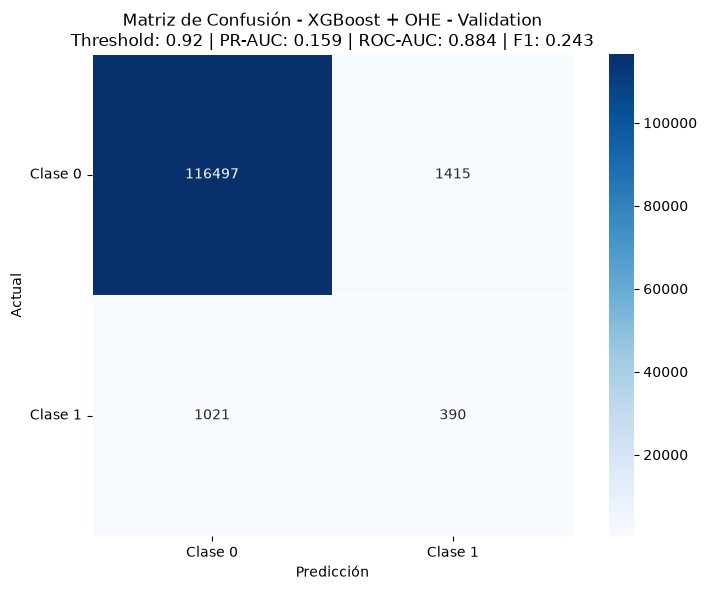


Reporte de Clasificación - XGBoost + OHE - Validation
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9913    0.9880    0.9897    117912
     Clase 1     0.2161    0.2764    0.2425      1411

    accuracy                         0.9796    119323
   macro avg     0.6037    0.6322    0.6161    119323
weighted avg     0.9821    0.9796    0.9808    119323

PR-AUC:    0.1589
ROC-AUC:   0.8840
Accuracy:  0.9796
Precision: 0.2161
Recall:    0.2764
F1-Score:  0.2425
FPR:       0.0120


In [42]:
# ============================================================
# XGBoost + OHE
# Validation Evaluation
# ============================================================

result_val_xgb_ohe = (
    plot_confusion_matrix_heatmap(

        y_true=
            y_val,

        y_pred_proba=
            y_val_pred_proba_xgb_ohe,

        model_name=
            "XGBoost + OHE - Validation",

        threshold=
            threshold_xgb_ohe
    )
)

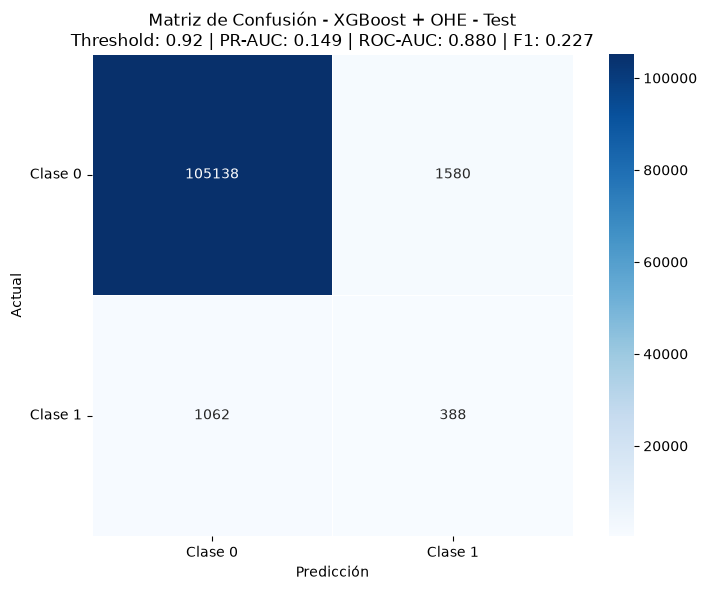


Reporte de Clasificación - XGBoost + OHE - Test
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9900    0.9852    0.9876    106718
     Clase 1     0.1972    0.2676    0.2270      1450

    accuracy                         0.9756    108168
   macro avg     0.5936    0.6264    0.6073    108168
weighted avg     0.9794    0.9756    0.9774    108168

PR-AUC:    0.1488
ROC-AUC:   0.8803
Accuracy:  0.9756
Precision: 0.1972
Recall:    0.2676
F1-Score:  0.2270
FPR:       0.0148


In [43]:
# ============================================================
# XGBoost + OHE
# Test Evaluation
# ============================================================

y_test_pred_proba_xgb_ohe = (

    xgb_ohe
    .predict_proba(
        X_test_ohe
    )[:, 1]
)


result_test_xgb_ohe = (
    plot_confusion_matrix_heatmap(

        y_true=
            y_test,

        y_pred_proba=
            y_test_pred_proba_xgb_ohe,

        model_name=
            "XGBoost + OHE - Test",

        threshold=
            threshold_xgb_ohe
    )
)

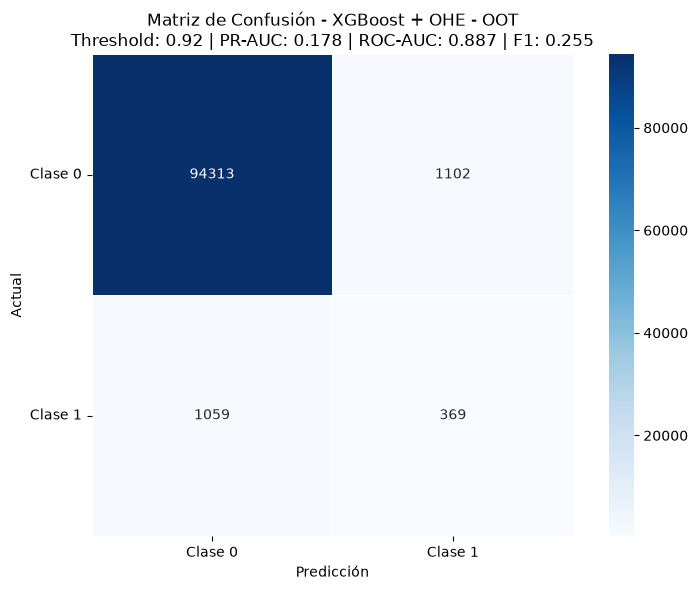


Reporte de Clasificación - XGBoost + OHE - OOT
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9889    0.9885    0.9887     95415
     Clase 1     0.2508    0.2584    0.2546      1428

    accuracy                         0.9777     96843
   macro avg     0.6199    0.6234    0.6216     96843
weighted avg     0.9780    0.9777    0.9778     96843

PR-AUC:    0.1778
ROC-AUC:   0.8874
Accuracy:  0.9777
Precision: 0.2508
Recall:    0.2584
F1-Score:  0.2546
FPR:       0.0115


In [44]:
# ============================================================
# XGBoost + OHE
# OOT Evaluation
# ============================================================

y_oot_pred_proba_xgb_ohe = (

    xgb_ohe
    .predict_proba(
        X_oot_ohe
    )[:, 1]
)


result_oot_xgb_ohe = (
    plot_confusion_matrix_heatmap(

        y_true=
            y_oot,

        y_pred_proba=
            y_oot_pred_proba_xgb_ohe,

        model_name=
            "XGBoost + OHE - OOT",

        threshold=
            threshold_xgb_ohe
    )
)

#### Feature Importance

In [45]:
# ============================================================
# Feature Importance
# XGBoost + OHE
# ============================================================

feature_importance_xgb_ohe = pd.DataFrame({

    "Feature":
        X_train_ohe_resampled.columns,

    "Importance":
        xgb_ohe.feature_importances_
})


feature_importance_xgb_ohe = (

    feature_importance_xgb_ohe

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    feature_importance_xgb_ohe
)

,Feature,Importance
0,categoricas_ohe__housing_status_BA,0.287221
1,categoricas_ohe__device_os_windows,0.151663
2,numericas_mediana__keep_alive_session,0.051178
3,categoricas_ohe__housing_status_BE,0.048310
4,categoricas_ohe__housing_status_BB,0.043195
5,numericas_mediana__has_other_cards,0.036276
6,numericas_mediana__digital_identity_score,0.032674
7,categoricas_ohe__payment_type_AA,0.030375
8,numericas_mediana__current_address_months_count,0.028453
9,numericas_mediana__contact_consistency,0.026384


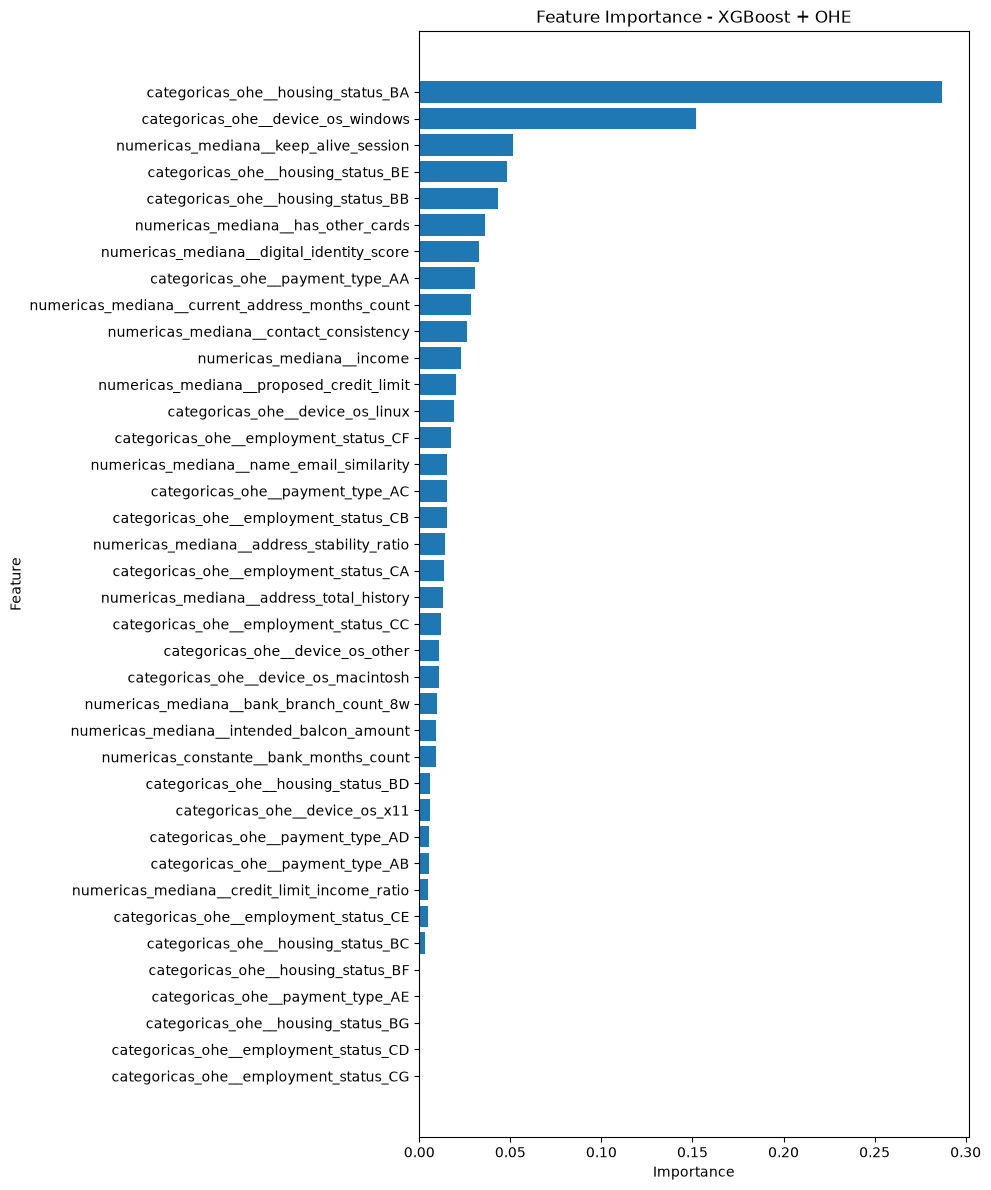

In [46]:
df_plot = feature_importance_xgb_ohe.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 12))

plt.barh(
    df_plot["Feature"],
    df_plot["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - XGBoost + OHE")

plt.tight_layout()
plt.show()

### XGBoost + WoE

#### Funcion Objetivo

In [47]:
# ============================================================
# XGBoost + WOE
# Función objetivo
# ============================================================

xgb_evaluate_woe = crear_xgb_objective(

    X_train_model=
        X_train_woe_resampled,

    y_train_model=
        y_train_resampled,

    X_val_model=
        X_val_woe,

    y_val_model=
        y_val
)

#### Optimizacion Bayesiana

In [48]:
# ============================================================
# Bayesian Optimization
# XGBoost + WOE
# ============================================================

xgb_bo_woe = BayesianOptimization(

    f=xgb_evaluate_woe,

    pbounds=params_pbounds_xgb,

    random_state=42,

    verbose=2
)


xgb_bo_woe.maximize(

    init_points=5,

    n_iter=15
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1497    | 0.6873    | 9.507     | 0.1125    | 5.395     | 7.085     | 162.4     | 1.162     | 17.46     | 0.8404    |
| 2         | 0.1458    | 0.854     | 0.2058    | 0.1458    | 6.33      | 9.281     | 172.7     | 3.668     | 6.781     | 0.8099    |
| 3         | 0.1509    | 0.716     | 2.912     | 0.09566   | 3.558     | 12.39     | 246.5     | 9.121     | 15.92     | 0.6799    |
| 4         | 0.1156    | 0.7571    | 5.924     | 0.0165    | 5.43      | 7.65      | 126.0     | 18.98     | 19.35     | 0.9234    |
| 5         | 0.1517    | 0.6523    | 0.9767    | 0.1058    | 4.761     | 5.759     | 298.1     | 0.6878    | 18.28     | 0.7035    |
| 6         | 0.1528    | 0.8225    | 6.464     | 0.145     | 

#### Mejores parametros

In [49]:
# ============================================================
# Mejores parámetros
# XGBoost + WOE
# ============================================================

best_params_xgb_woe = (
    xgb_bo_woe
    .max["params"]
    .copy()
)


best_params_xgb_woe[
    "max_depth"
] = int(
    round(
        best_params_xgb_woe[
            "max_depth"
        ]
    )
)


best_params_xgb_woe[
    "n_estimators"
] = int(
    round(
        best_params_xgb_woe[
            "n_estimators"
        ]
    )
)


print(
    "\nMejores parámetros "
    "XGBoost + WOE:"
)

for parametro, valor in (
    best_params_xgb_woe.items()
):

    print(
        f"{parametro}: {valor}"
    )


print(
    "\nMejor PR-AUC Validation:",
    xgb_bo_woe.max["target"]
)


Mejores parámetros XGBoost + WOE:
colsample_bytree: 0.7777963610084128
gamma: 4.426562927870512
learning_rate: 0.1273329002616689
max_depth: 7
min_child_weight: 17.914486964005672
n_estimators: 264
reg_alpha: 0.867323014250958
reg_lambda: 5.585320729199451
subsample: 0.6513644151205605

Mejor PR-AUC Validation: 0.1578874252331075


#### Training

In [50]:
# ============================================================
# Modelo final XGBoost + WOE
# ============================================================

xgb_woe = XGBClassifier(
    **best_params_xgb_woe,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=150718,
    n_jobs=-1,
    tree_method="hist"
)


xgb_woe.fit(
    X_train_woe_resampled,
    y_train_resampled
)


print("XGBoost + WOE entrenado correctamente.")

XGBoost + WOE entrenado correctamente.


#### Probabilidades Train y Val

In [51]:
# ============================================================
# Predicciones Train / Validation
# ============================================================

y_train_pred_proba_xgb_woe = (

    xgb_woe
    .predict_proba(
        X_train_woe_resampled
    )[:, 1]
)


y_val_pred_proba_xgb_woe = (

    xgb_woe
    .predict_proba(
        X_val_woe
    )[:, 1]
)

#### Threshold

In [52]:
# ============================================================
# Threshold XGBoost + WOE
# ============================================================

threshold_xgb_woe, df_threshold_xgb_woe = (
    encontrar_mejor_threshold(
        y_true=y_val,
        y_pred_proba= y_val_pred_proba_xgb_woe
    )
)

Mejor threshold según Validation: 0.93
Precision: 0.2303
Recall: 0.2346
F1: 0.2324


#### Evaluation

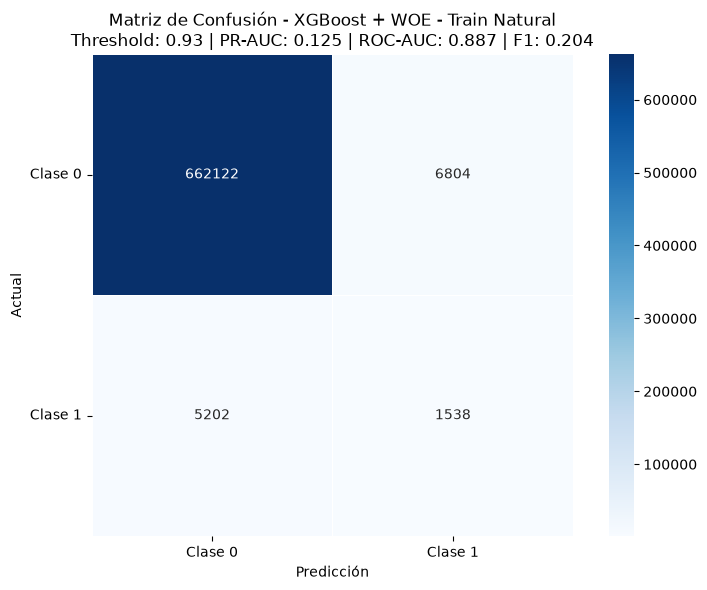


Reporte de Clasificación - XGBoost + WOE - Train Natural
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9922    0.9898    0.9910    668926
     Clase 1     0.1844    0.2282    0.2040      6740

    accuracy                         0.9822    675666
   macro avg     0.5883    0.6090    0.5975    675666
weighted avg     0.9841    0.9822    0.9832    675666

PR-AUC:    0.1251
ROC-AUC:   0.8867
Accuracy:  0.9822
Precision: 0.1844
Recall:    0.2282
F1-Score:  0.2040
FPR:       0.0102


In [53]:
# ============================================================
# XGBoost + WOE
# Train Natural Evaluation
# ============================================================

y_train_pred_proba_xgb_woe = (
    xgb_woe
    .predict_proba(
        X_train_woe
    )[:, 1]
)


result_train_xgb_woe = (
    plot_confusion_matrix_heatmap(
        y_true= y_train,
        y_pred_proba= y_train_pred_proba_xgb_woe,
        model_name= "XGBoost + WOE - Train Natural",
        threshold= threshold_xgb_woe
    )
)

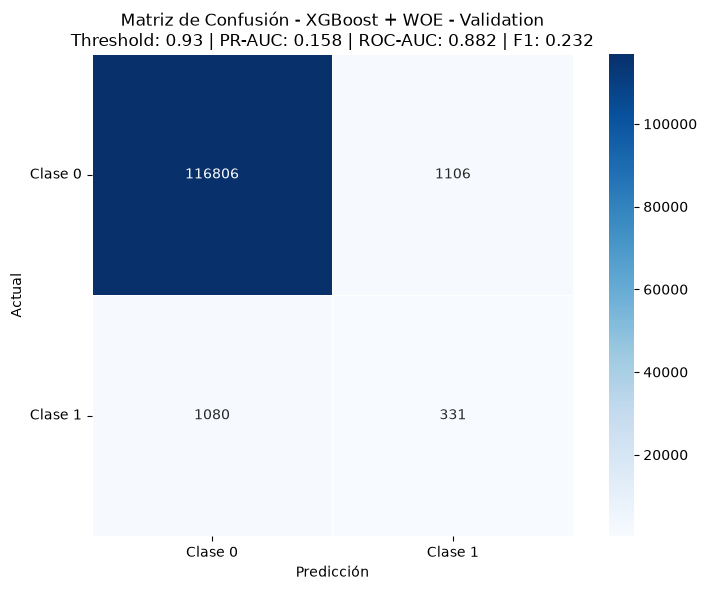


Reporte de Clasificación - XGBoost + WOE - Validation
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9908    0.9906    0.9907    117912
     Clase 1     0.2303    0.2346    0.2324      1411

    accuracy                         0.9817    119323
   macro avg     0.6106    0.6126    0.6116    119323
weighted avg     0.9818    0.9817    0.9818    119323

PR-AUC:    0.1579
ROC-AUC:   0.8824
Accuracy:  0.9817
Precision: 0.2303
Recall:    0.2346
F1-Score:  0.2324
FPR:       0.0094


In [54]:
result_val_xgb_woe = (
    plot_confusion_matrix_heatmap(
        y_true= y_val,
        y_pred_proba= y_val_pred_proba_xgb_woe,
        model_name= "XGBoost + WOE - Validation",
        threshold= threshold_xgb_woe
    )
)

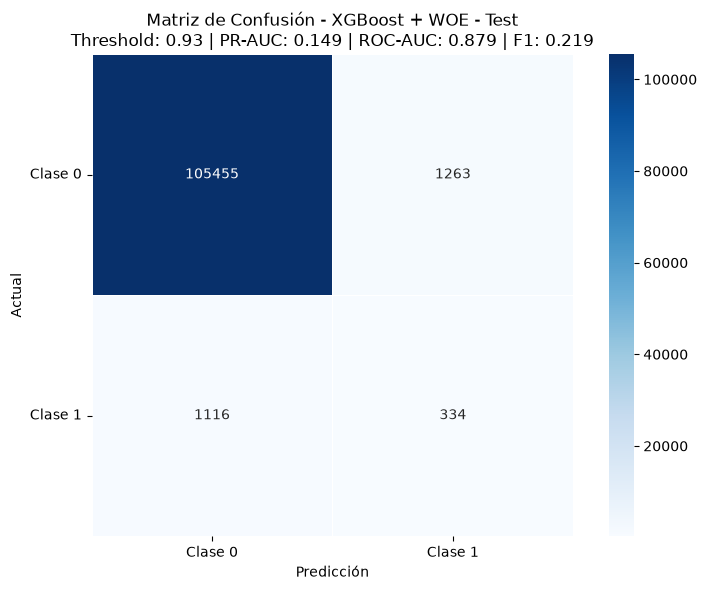


Reporte de Clasificación - XGBoost + WOE - Test
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9895    0.9882    0.9888    106718
     Clase 1     0.2091    0.2303    0.2192      1450

    accuracy                         0.9780    108168
   macro avg     0.5993    0.6093    0.6040    108168
weighted avg     0.9791    0.9780    0.9785    108168

PR-AUC:    0.1486
ROC-AUC:   0.8791
Accuracy:  0.9780
Precision: 0.2091
Recall:    0.2303
F1-Score:  0.2192
FPR:       0.0118


In [55]:
y_test_pred_proba_xgb_woe = (

    xgb_woe
    .predict_proba(
        X_test_woe
    )[:, 1]
)


result_test_xgb_woe = (
    plot_confusion_matrix_heatmap(

        y_true=y_test,

        y_pred_proba=
            y_test_pred_proba_xgb_woe,

        model_name=
            "XGBoost + WOE - Test",

        threshold=
            threshold_xgb_woe
    )
)

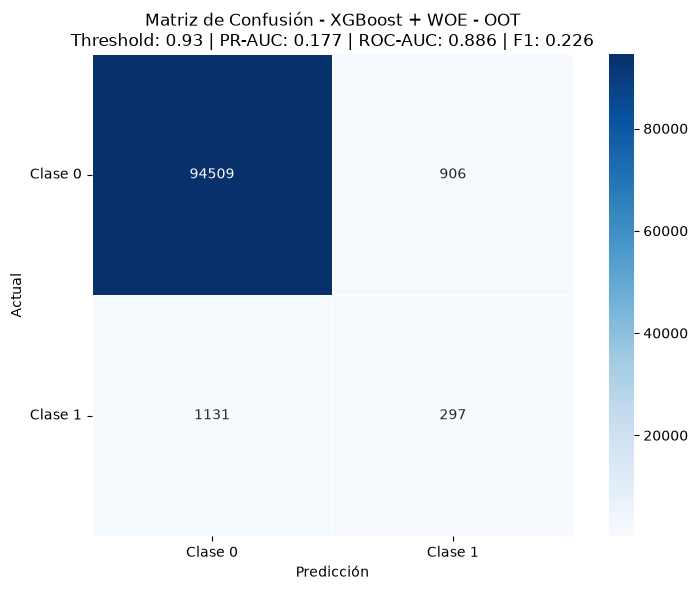


Reporte de Clasificación - XGBoost + WOE - OOT
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9882    0.9905    0.9893     95415
     Clase 1     0.2469    0.2080    0.2258      1428

    accuracy                         0.9790     96843
   macro avg     0.6175    0.5992    0.6076     96843
weighted avg     0.9772    0.9790    0.9781     96843

PR-AUC:    0.1768
ROC-AUC:   0.8855
Accuracy:  0.9790
Precision: 0.2469
Recall:    0.2080
F1-Score:  0.2258
FPR:       0.0095


In [56]:
y_oot_pred_proba_xgb_woe = (
    xgb_woe
    .predict_proba(
        X_oot_woe
    )[:, 1]
)


result_oot_xgb_woe = (
    plot_confusion_matrix_heatmap(
        y_true= y_oot,
        y_pred_proba= y_oot_pred_proba_xgb_woe,
        model_name= "XGBoost + WOE - OOT",
        threshold= threshold_xgb_woe
    )
)

#### Feature Importance

In [57]:
# ============================================================
# Feature Importance
# XGBoost + WOE
# ============================================================

feature_importance_xgb_woe = pd.DataFrame({
    "Feature": X_train_woe_resampled.columns,
    "Importance": xgb_woe.feature_importances_
})


feature_importance_xgb_woe = (
    feature_importance_xgb_woe
    .sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)
)


display(feature_importance_xgb_woe)

,Feature,Importance
0,housing_status,0.300225
1,device_os,0.192193
2,keep_alive_session,0.057742
3,has_other_cards,0.047534
4,digital_identity_score,0.046209
5,contact_consistency,0.043932
6,proposed_credit_limit,0.040459
7,address_total_history,0.036090
8,current_address_months_count,0.033196
9,income,0.028311


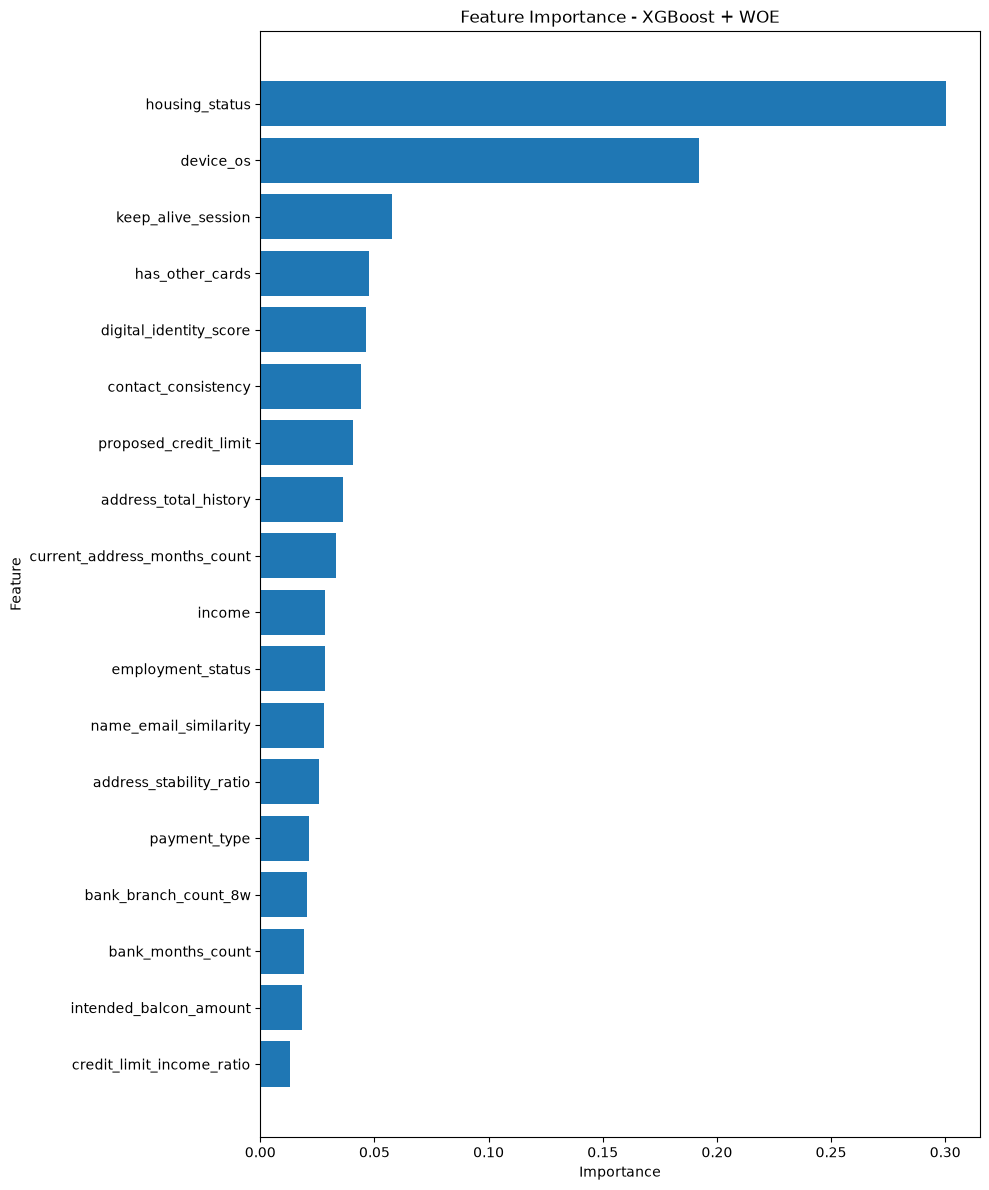

In [58]:
df_plot = feature_importance_xgb_woe.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 12))

plt.barh(
    df_plot["Feature"],
    df_plot["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - XGBoost + WOE")

plt.tight_layout()
plt.show()

### Comparativo

In [59]:
# ============================================================
# Tabla comparativa de métricas
# XGBoost + OHE vs XGBoost + WOE
# ============================================================

resultados_modelos = [
    {
        "Modelo": "XGBoost + OHE",
        "Dataset": "Train Natural",
        **result_train_xgb_ohe
    },
    {
        "Modelo": "XGBoost + OHE",
        "Dataset": "Validation",
        **result_val_xgb_ohe
    },
    {
        "Modelo": "XGBoost + OHE",
        "Dataset": "Test",
        **result_test_xgb_ohe
    },
    {
        "Modelo": "XGBoost + OHE",
        "Dataset": "OOT",
        **result_oot_xgb_ohe
    },

    {
        "Modelo": "XGBoost + WOE",
        "Dataset": "Train Natural",
        **result_train_xgb_woe
    },
    {
        "Modelo": "XGBoost + WOE",
        "Dataset": "Validation",
        **result_val_xgb_woe
    },
    {
        "Modelo": "XGBoost + WOE",
        "Dataset": "Test",
        **result_test_xgb_woe
    },
    {
        "Modelo": "XGBoost + WOE",
        "Dataset": "OOT",
        **result_oot_xgb_woe
    }
]


df_comparacion_modelos = pd.DataFrame(
    resultados_modelos
)

In [60]:
columnas_metricas = [
    "Modelo",
    "Dataset",
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]


df_comparacion_modelos = (
    df_comparacion_modelos[
        columnas_metricas
    ]
    .copy()
)


columnas_numericas_metricas = [
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]


df_comparacion_modelos[columnas_numericas_metricas] = (
    df_comparacion_modelos[columnas_numericas_metricas].round(4)
)


display(df_comparacion_modelos)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr
0,XGBoost + OHE,Train Natural,0.92,0.1268,0.8885,0.9793,0.1670,0.2684,0.2059,0.0135
1,XGBoost + OHE,Validation,0.92,0.1589,0.8840,0.9796,0.2161,0.2764,0.2425,0.0120
2,XGBoost + OHE,Test,0.92,0.1488,0.8803,0.9756,0.1972,0.2676,0.2270,0.0148
3,XGBoost + OHE,OOT,0.92,0.1778,0.8874,0.9777,0.2508,0.2584,0.2546,0.0115
4,XGBoost + WOE,Train Natural,0.93,0.1251,0.8867,0.9822,0.1844,0.2282,0.2040,0.0102
5,XGBoost + WOE,Validation,0.93,0.1579,0.8824,0.9817,0.2303,0.2346,0.2324,0.0094
6,XGBoost + WOE,Test,0.93,0.1486,0.8791,0.9780,0.2091,0.2303,0.2192,0.0118
7,XGBoost + WOE,OOT,0.93,0.1768,0.8855,0.9790,0.2469,0.2080,0.2258,0.0095


## LGBM

### Funcion Objetivo

In [61]:
# ============================================================
# LightGBM
# ============================================================

from lightgbm import LGBMClassifier
from bayes_opt import BayesianOptimization
from sklearn.metrics import average_precision_score


# ============================================================
# Factory de función objetivo LightGBM
# ============================================================

def crear_lgbm_objective(
    X_train_model,
    y_train_model,
    X_val_model,
    y_val_model
):
    """
    Crea una función objetivo para Bayesian Optimization.
    La métrica a maximizar es PR-AUC sobre Validation.
    """

    def lgbm_evaluate(
        num_leaves,
        max_depth,
        learning_rate,
        n_estimators,
        subsample,
        colsample_bytree,
        min_child_samples,
        reg_alpha,
        reg_lambda
    ):

        params = {
            "objective": "binary",
            "num_leaves": int(round(num_leaves)),
            "max_depth": int(round(max_depth)),
            "learning_rate": learning_rate,
            "n_estimators": int(round(n_estimators)),
            "subsample": subsample,
            "subsample_freq": 1,
            "colsample_bytree": colsample_bytree,
            "min_child_samples": int(round(min_child_samples)),
            "reg_alpha": reg_alpha,
            "reg_lambda": reg_lambda,
            "random_state": 150718,
            "n_jobs": -1,
            "verbosity": -1
        }

        model = LGBMClassifier(**params)

        model.fit(
            X_train_model,
            y_train_model
        )

        y_val_pred_proba = model.predict_proba(X_val_model)[:, 1]

        return average_precision_score(
            y_val_model,
            y_val_pred_proba
        )

    return lgbm_evaluate

### Espacio de Busqueda

In [62]:
# ============================================================
# Espacio de búsqueda LightGBM
# ============================================================

params_pbounds_lgbm = {
    "num_leaves": (15, 63),
    "max_depth": (3, 8),
    "learning_rate": (0.01, 0.15),
    "n_estimators": (100, 500),
    "subsample": (0.6, 1.0),
    "colsample_bytree": (0.5, 1.0),
    "min_child_samples": (10, 100),
    "reg_alpha": (0, 20),
    "reg_lambda": (0, 20)
}

### LGBM + OHE

#### Funcion Objetivo

In [63]:
# ============================================================
# LightGBM + OHE
# Función objetivo
# ============================================================

lgbm_evaluate_ohe = crear_lgbm_objective(
    X_train_model=X_train_ohe_resampled,
    y_train_model=y_train_resampled,
    X_val_model=X_val_ohe,
    y_val_model=y_val
)

#### Optimizacion Bayesiana

In [64]:
# ============================================================
# Bayesian Optimization
# LightGBM + OHE
# ============================================================

lgbm_bo_ohe = BayesianOptimization(
    f=lgbm_evaluate_ohe,
    pbounds=params_pbounds_lgbm,
    random_state=42,
    verbose=2
)

lgbm_bo_ohe.maximize(
    init_points=5,
    n_iter=15
)

|   iter    |  target   | colsam... | learni... | max_depth | min_ch... | n_esti... | num_le... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.152     | 0.6873    | 0.1431    | 6.66      | 63.88     | 162.4     | 22.49     | 1.162     | 17.32     | 0.8404    |
| 2         | 0.126     | 0.854     | 0.01288   | 7.85      | 84.92     | 184.9     | 23.73     | 3.668     | 6.085     | 0.8099    |
| 3         | 0.1495    | 0.716     | 0.05077   | 6.059     | 22.55     | 216.9     | 32.59     | 9.121     | 15.7      | 0.6799    |
| 4         | 0.1485    | 0.7571    | 0.09294   | 3.232     | 64.68     | 168.2     | 18.12     | 18.98     | 19.31     | 0.9234    |
| 5         | 0.1341    | 0.6523    | 0.02367   | 6.421     | 49.61     | 148.8     | 38.77     | 0.6878    | 18.19     | 0.7035    |
| 6         | 0.1518    | 0.9818    | 0.08954   | 6.504     | 

#### Mejores parametros

In [65]:
# ============================================================
# Mejores parámetros LightGBM + OHE
# ============================================================

best_params_lgbm_ohe = lgbm_bo_ohe.max["params"].copy()

best_params_lgbm_ohe["num_leaves"] = int(round(best_params_lgbm_ohe["num_leaves"]))
best_params_lgbm_ohe["max_depth"] = int(round(best_params_lgbm_ohe["max_depth"]))
best_params_lgbm_ohe["n_estimators"] = int(round(best_params_lgbm_ohe["n_estimators"]))
best_params_lgbm_ohe["min_child_samples"] = int(
    round(best_params_lgbm_ohe["min_child_samples"])
)

print("\nMejores parámetros LightGBM + OHE:")
for parametro, valor in best_params_lgbm_ohe.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor PR-AUC Validation: "
    f"{lgbm_bo_ohe.max['target']:.6f}"
)


Mejores parámetros LightGBM + OHE:
colsample_bytree: 0.6671287894576701
learning_rate: 0.08367351442059355
max_depth: 7
min_child_samples: 43
n_estimators: 178
num_leaves: 17
reg_alpha: 0.12687889305631472
reg_lambda: 16.39768340318155
subsample: 0.7940599294401349

Mejor PR-AUC Validation: 0.156920


#### Training

In [66]:
# ============================================================
# Modelo final LightGBM + OHE
# ============================================================

lgbm_ohe = LGBMClassifier(
    **best_params_lgbm_ohe,
    objective="binary",
    subsample_freq=1,
    random_state=150718,
    n_jobs=-1,
    verbosity=-1
)

lgbm_ohe.fit(
    X_train_ohe_resampled,
    y_train_resampled
)

print("LightGBM + OHE entrenado correctamente.")

LightGBM + OHE entrenado correctamente.


#### Probabilidades Train y Val

In [67]:
# ============================================================
# Probabilidades Train Natural y Validation
# ============================================================

y_train_pred_proba_lgbm_ohe = (
    lgbm_ohe.predict_proba(X_train_ohe)[:, 1]
)

y_val_pred_proba_lgbm_ohe = (
    lgbm_ohe.predict_proba(X_val_ohe)[:, 1]
)

#### Threshold

In [68]:
# ============================================================
# Threshold LightGBM + OHE
# Seleccionado exclusivamente con Validation
# ============================================================

threshold_lgbm_ohe, df_threshold_lgbm_ohe = encontrar_mejor_threshold(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_lgbm_ohe
)

Mejor threshold según Validation: 0.93
Precision: 0.2239
Recall: 0.2488
F1: 0.2356


#### Evaluation

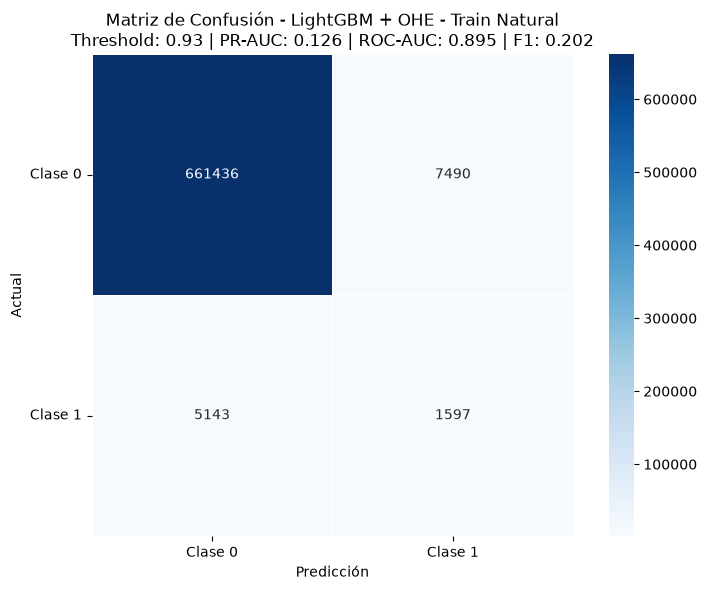


Reporte de Clasificación - LightGBM + OHE - Train Natural
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9923    0.9888    0.9905    668926
     Clase 1     0.1757    0.2369    0.2018      6740

    accuracy                         0.9813    675666
   macro avg     0.5840    0.6129    0.5962    675666
weighted avg     0.9841    0.9813    0.9827    675666

PR-AUC:    0.1264
ROC-AUC:   0.8947
Accuracy:  0.9813
Precision: 0.1757
Recall:    0.2369
F1-Score:  0.2018
FPR:       0.0112


In [69]:
result_train_lgbm_ohe = plot_confusion_matrix_heatmap(
    y_true=y_train,
    y_pred_proba=y_train_pred_proba_lgbm_ohe,
    model_name="LightGBM + OHE - Train Natural",
    threshold=threshold_lgbm_ohe
)

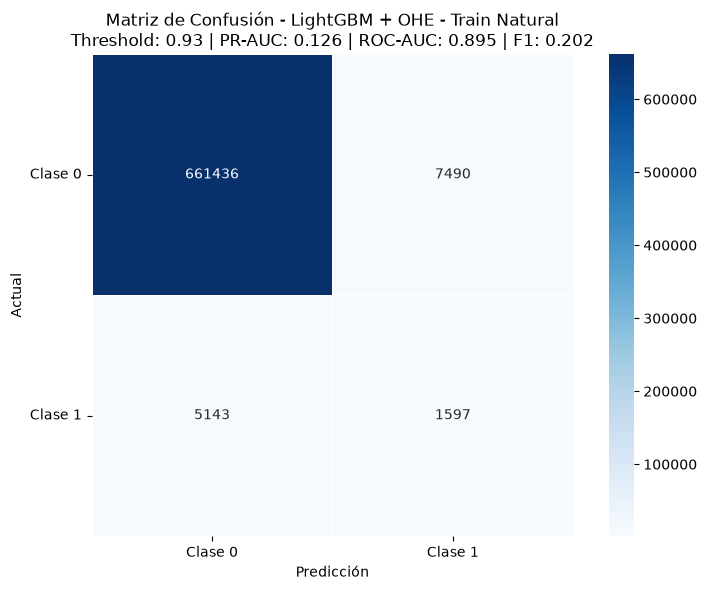


Reporte de Clasificación - LightGBM + OHE - Train Natural
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9923    0.9888    0.9905    668926
     Clase 1     0.1757    0.2369    0.2018      6740

    accuracy                         0.9813    675666
   macro avg     0.5840    0.6129    0.5962    675666
weighted avg     0.9841    0.9813    0.9827    675666

PR-AUC:    0.1264
ROC-AUC:   0.8947
Accuracy:  0.9813
Precision: 0.1757
Recall:    0.2369
F1-Score:  0.2018
FPR:       0.0112


In [70]:
result_train_lgbm_ohe = plot_confusion_matrix_heatmap(
    y_true=y_train,
    y_pred_proba=y_train_pred_proba_lgbm_ohe,
    model_name="LightGBM + OHE - Train Natural",
    threshold=threshold_lgbm_ohe
)

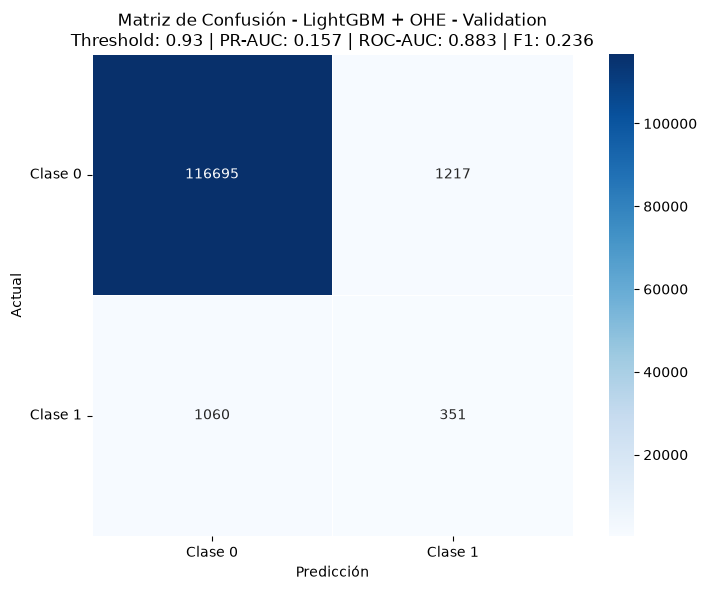


Reporte de Clasificación - LightGBM + OHE - Validation
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9910    0.9897    0.9903    117912
     Clase 1     0.2239    0.2488    0.2356      1411

    accuracy                         0.9809    119323
   macro avg     0.6074    0.6192    0.6130    119323
weighted avg     0.9819    0.9809    0.9814    119323

PR-AUC:    0.1569
ROC-AUC:   0.8832
Accuracy:  0.9809
Precision: 0.2239
Recall:    0.2488
F1-Score:  0.2356
FPR:       0.0103


In [71]:
result_val_lgbm_ohe = plot_confusion_matrix_heatmap(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_lgbm_ohe,
    model_name="LightGBM + OHE - Validation",
    threshold=threshold_lgbm_ohe
)

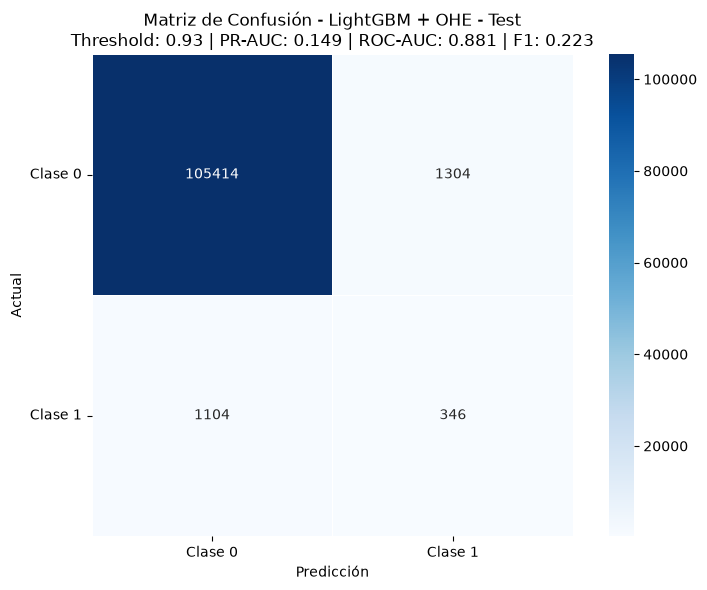


Reporte de Clasificación - LightGBM + OHE - Test
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9896    0.9878    0.9887    106718
     Clase 1     0.2097    0.2386    0.2232      1450

    accuracy                         0.9777    108168
   macro avg     0.5997    0.6132    0.6060    108168
weighted avg     0.9792    0.9777    0.9784    108168

PR-AUC:    0.1486
ROC-AUC:   0.8812
Accuracy:  0.9777
Precision: 0.2097
Recall:    0.2386
F1-Score:  0.2232
FPR:       0.0122


In [72]:
y_test_pred_proba_lgbm_ohe = (
    lgbm_ohe.predict_proba(X_test_ohe)[:, 1]
)

result_test_lgbm_ohe = plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba_lgbm_ohe,
    model_name="LightGBM + OHE - Test",
    threshold=threshold_lgbm_ohe
)

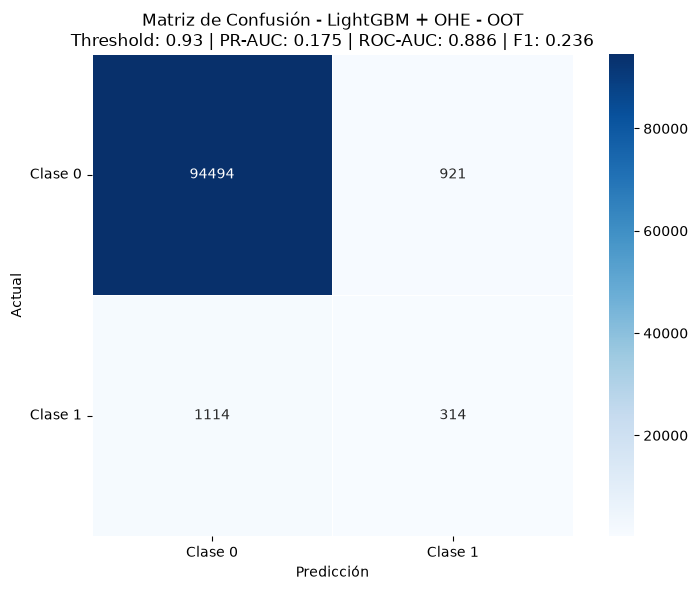


Reporte de Clasificación - LightGBM + OHE - OOT
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9883    0.9903    0.9893     95415
     Clase 1     0.2543    0.2199    0.2358      1428

    accuracy                         0.9790     96843
   macro avg     0.6213    0.6051    0.6126     96843
weighted avg     0.9775    0.9790    0.9782     96843

PR-AUC:    0.1754
ROC-AUC:   0.8864
Accuracy:  0.9790
Precision: 0.2543
Recall:    0.2199
F1-Score:  0.2358
FPR:       0.0097


In [73]:
y_oot_pred_proba_lgbm_ohe = (
    lgbm_ohe.predict_proba(X_oot_ohe)[:, 1]
)

result_oot_lgbm_ohe = plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba_lgbm_ohe,
    model_name="LightGBM + OHE - OOT",
    threshold=threshold_lgbm_ohe
)

#### Feature Importance

In [74]:
# ============================================================
# Feature Importance
# LightGBM + OHE
# ============================================================

feature_importance_lgbm_ohe = pd.DataFrame({
    "Feature": X_train_ohe_resampled.columns,
    "Importance": lgbm_ohe.feature_importances_
})

feature_importance_lgbm_ohe = (
    feature_importance_lgbm_ohe
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_lgbm_ohe)

,Feature,Importance
0,numericas_mediana__name_email_similarity,357
1,numericas_mediana__current_address_months_count,310
2,numericas_mediana__bank_branch_count_8w,282
3,numericas_mediana__intended_balcon_amount,276
4,numericas_constante__bank_months_count,213
5,numericas_mediana__digital_identity_score,130
6,numericas_mediana__income,128
7,numericas_mediana__address_stability_ratio,113
8,numericas_mediana__credit_limit_income_ratio,110
9,numericas_mediana__proposed_credit_limit,97


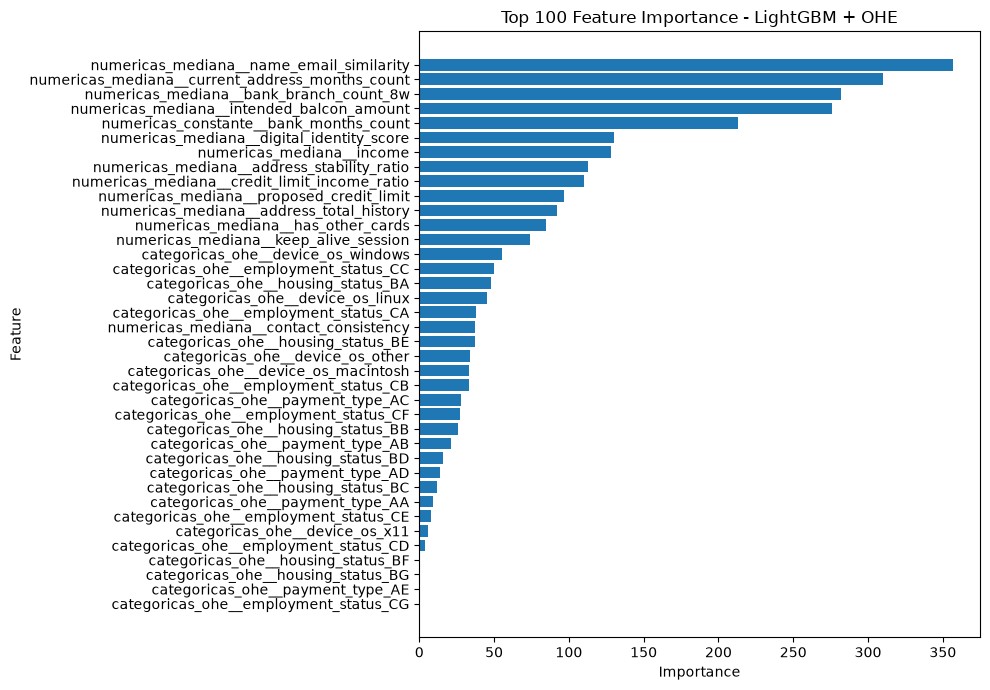

In [75]:
top_n = 100

df_plot = (
    feature_importance_lgbm_ohe
    .head(top_n)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(df_plot["Feature"], df_plot["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Feature Importance - LightGBM + OHE")

plt.tight_layout()
plt.show()

### LGBM + WOE

#### Funcion Objetivo

In [76]:
# ============================================================
# LightGBM + WOE
# Función objetivo
# ============================================================

lgbm_evaluate_woe = crear_lgbm_objective(
    X_train_model=X_train_woe_resampled,
    y_train_model=y_train_resampled,
    X_val_model=X_val_woe,
    y_val_model=y_val
)

#### Optimizacion Bayesiana

In [77]:
# ============================================================
# Bayesian Optimization
# LightGBM + WOE
# ============================================================

lgbm_bo_woe = BayesianOptimization(
    f=lgbm_evaluate_woe,
    pbounds=params_pbounds_lgbm,
    random_state=42,
    verbose=2
)

lgbm_bo_woe.maximize(
    init_points=5,
    n_iter=15
)

|   iter    |  target   | colsam... | learni... | max_depth | min_ch... | n_esti... | num_le... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1488    | 0.6873    | 0.1431    | 6.66      | 63.88     | 162.4     | 22.49     | 1.162     | 17.32     | 0.8404    |
| 2         | 0.1268    | 0.854     | 0.01288   | 7.85      | 84.92     | 184.9     | 23.73     | 3.668     | 6.085     | 0.8099    |
| 3         | 0.1518    | 0.716     | 0.05077   | 6.059     | 22.55     | 216.9     | 32.59     | 9.121     | 15.7      | 0.6799    |
| 4         | 0.1505    | 0.7571    | 0.09294   | 3.232     | 64.68     | 168.2     | 18.12     | 18.98     | 19.31     | 0.9234    |
| 5         | 0.1361    | 0.6523    | 0.02367   | 6.421     | 49.61     | 148.8     | 38.77     | 0.6878    | 18.19     | 0.7035    |
| 6         | 0.1575    | 0.5643    | 0.1464    | 3.121     | 

#### Mejores parametros

In [78]:
# ============================================================
# Mejores parámetros LightGBM + WOE
# ============================================================

best_params_lgbm_woe = lgbm_bo_woe.max["params"].copy()

best_params_lgbm_woe["num_leaves"] = int(round(best_params_lgbm_woe["num_leaves"]))
best_params_lgbm_woe["max_depth"] = int(round(best_params_lgbm_woe["max_depth"]))
best_params_lgbm_woe["n_estimators"] = int(round(best_params_lgbm_woe["n_estimators"]))
best_params_lgbm_woe["min_child_samples"] = int(
    round(best_params_lgbm_woe["min_child_samples"])
)

print("\nMejores parámetros LightGBM + WOE:")
for parametro, valor in best_params_lgbm_woe.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor PR-AUC Validation: "
    f"{lgbm_bo_woe.max['target']:.6f}"
)


Mejores parámetros LightGBM + WOE:
colsample_bytree: 0.5643175859494998
learning_rate: 0.14636796780182126
max_depth: 3
min_child_samples: 21
n_estimators: 225
num_leaves: 39
reg_alpha: 4.322723169586478
reg_lambda: 14.724302977080528
subsample: 0.743016761370396

Mejor PR-AUC Validation: 0.157518


#### Training

In [79]:
# ============================================================
# Modelo final LightGBM + WOE
# ============================================================

lgbm_woe = LGBMClassifier(
    **best_params_lgbm_woe,
    objective="binary",
    subsample_freq=1,
    random_state=150718,
    n_jobs=-1,
    verbosity=-1
)

lgbm_woe.fit(
    X_train_woe_resampled,
    y_train_resampled
)

print("LightGBM + WOE entrenado correctamente.")

LightGBM + WOE entrenado correctamente.


#### Probabilidades Train y Val

In [80]:
# ============================================================
# Probabilidades Train Natural y Validation
# ============================================================

y_train_pred_proba_lgbm_woe = (
    lgbm_woe.predict_proba(X_train_woe)[:, 1]
)

y_val_pred_proba_lgbm_woe = (
    lgbm_woe.predict_proba(X_val_woe)[:, 1]
)

#### Threshold

In [81]:
# ============================================================
# Threshold LightGBM + WOE
# ============================================================

threshold_lgbm_woe, df_threshold_lgbm_woe = encontrar_mejor_threshold(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_lgbm_woe
)

Mejor threshold según Validation: 0.93
Precision: 0.2292
Recall: 0.2339
F1: 0.2315


#### Evaluation

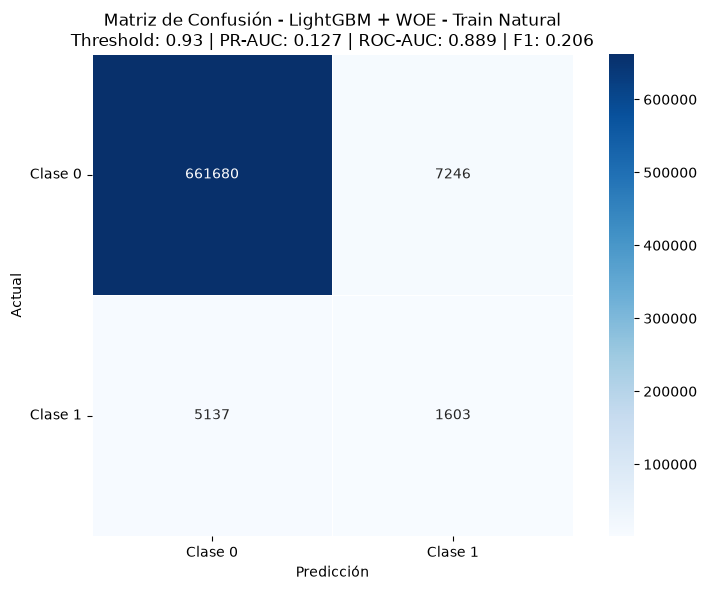


Reporte de Clasificación - LightGBM + WOE - Train Natural
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9923    0.9892    0.9907    668926
     Clase 1     0.1812    0.2378    0.2057      6740

    accuracy                         0.9817    675666
   macro avg     0.5867    0.6135    0.5982    675666
weighted avg     0.9842    0.9817    0.9829    675666

PR-AUC:    0.1268
ROC-AUC:   0.8890
Accuracy:  0.9817
Precision: 0.1812
Recall:    0.2378
F1-Score:  0.2057
FPR:       0.0108


In [82]:
result_train_lgbm_woe = plot_confusion_matrix_heatmap(
    y_true=y_train,
    y_pred_proba=y_train_pred_proba_lgbm_woe,
    model_name="LightGBM + WOE - Train Natural",
    threshold=threshold_lgbm_woe
)

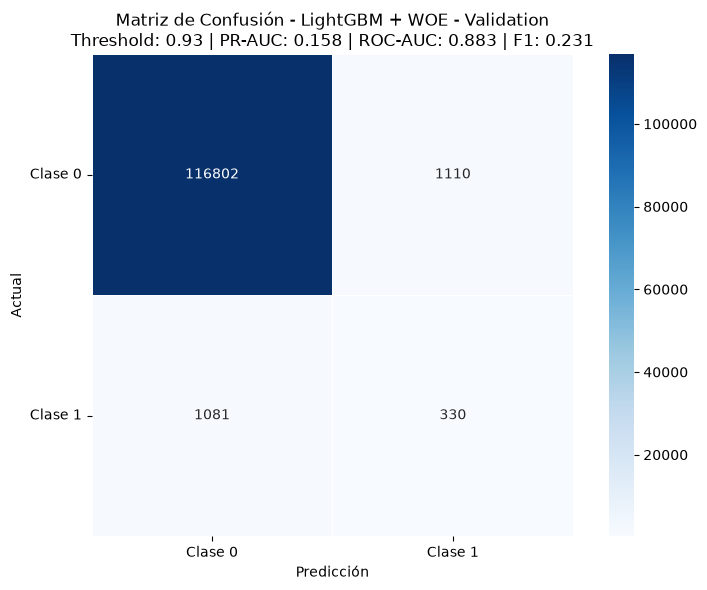


Reporte de Clasificación - LightGBM + WOE - Validation
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9908    0.9906    0.9907    117912
     Clase 1     0.2292    0.2339    0.2315      1411

    accuracy                         0.9816    119323
   macro avg     0.6100    0.6122    0.6111    119323
weighted avg     0.9818    0.9816    0.9817    119323

PR-AUC:    0.1575
ROC-AUC:   0.8829
Accuracy:  0.9816
Precision: 0.2292
Recall:    0.2339
F1-Score:  0.2315
FPR:       0.0094


In [83]:
result_val_lgbm_woe = plot_confusion_matrix_heatmap(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_lgbm_woe,
    model_name="LightGBM + WOE - Validation",
    threshold=threshold_lgbm_woe
)

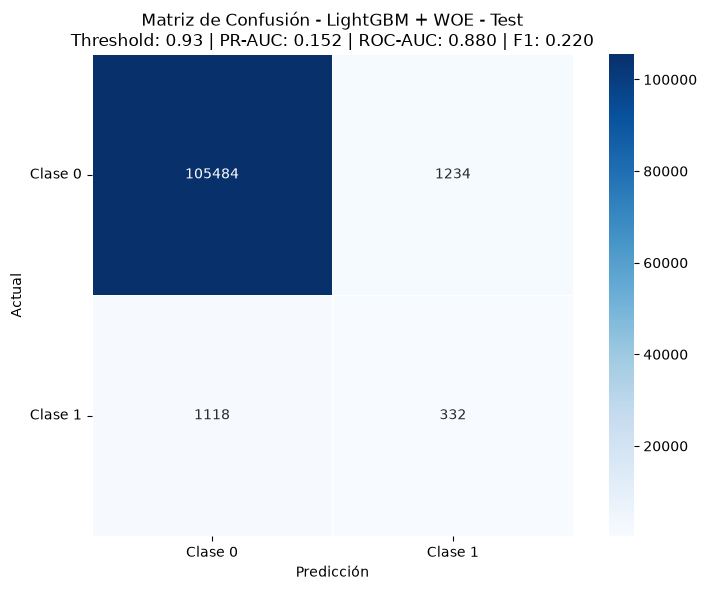


Reporte de Clasificación - LightGBM + WOE - Test
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9895    0.9884    0.9890    106718
     Clase 1     0.2120    0.2290    0.2202      1450

    accuracy                         0.9783    108168
   macro avg     0.6008    0.6087    0.6046    108168
weighted avg     0.9791    0.9783    0.9787    108168

PR-AUC:    0.1523
ROC-AUC:   0.8801
Accuracy:  0.9783
Precision: 0.2120
Recall:    0.2290
F1-Score:  0.2202
FPR:       0.0116


In [84]:
y_test_pred_proba_lgbm_woe = (
    lgbm_woe.predict_proba(X_test_woe)[:, 1]
)

result_test_lgbm_woe = plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba_lgbm_woe,
    model_name="LightGBM + WOE - Test",
    threshold=threshold_lgbm_woe
)

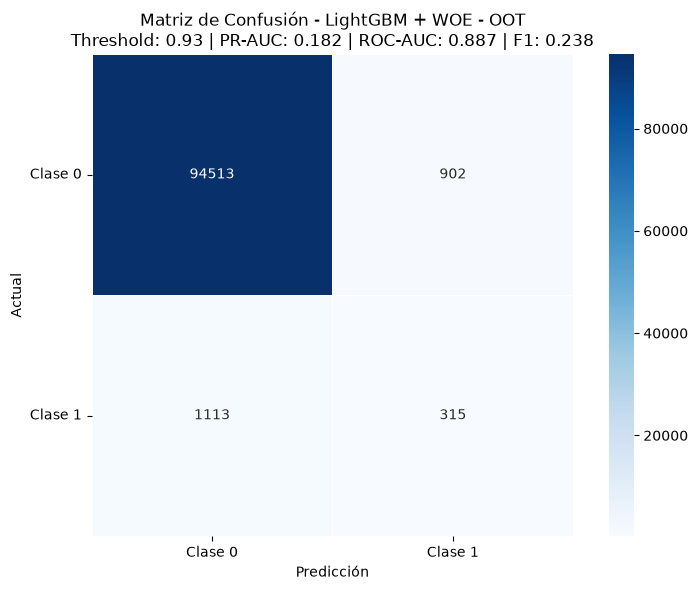


Reporte de Clasificación - LightGBM + WOE - OOT
Threshold utilizado: 0.93

              precision    recall  f1-score   support

     Clase 0     0.9884    0.9905    0.9895     95415
     Clase 1     0.2588    0.2206    0.2382      1428

    accuracy                         0.9792     96843
   macro avg     0.6236    0.6056    0.6138     96843
weighted avg     0.9776    0.9792    0.9784     96843

PR-AUC:    0.1816
ROC-AUC:   0.8867
Accuracy:  0.9792
Precision: 0.2588
Recall:    0.2206
F1-Score:  0.2382
FPR:       0.0095


In [85]:
y_oot_pred_proba_lgbm_woe = (
    lgbm_woe.predict_proba(X_oot_woe)[:, 1]
)

result_oot_lgbm_woe = plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba_lgbm_woe,
    model_name="LightGBM + WOE - OOT",
    threshold=threshold_lgbm_woe
)

#### Feature importance

In [86]:
# ============================================================
# Feature Importance
# LightGBM + WOE
# ============================================================

feature_importance_lgbm_woe = pd.DataFrame({
    "Feature": X_train_woe_resampled.columns,
    "Importance": lgbm_woe.feature_importances_
})

feature_importance_lgbm_woe = (
    feature_importance_lgbm_woe
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_lgbm_woe)

,Feature,Importance
0,current_address_months_count,208
1,name_email_similarity,186
2,intended_balcon_amount,181
3,bank_months_count,137
4,bank_branch_count_8w,134
5,credit_limit_income_ratio,73
6,income,70
7,digital_identity_score,69
8,housing_status,66
9,address_stability_ratio,61


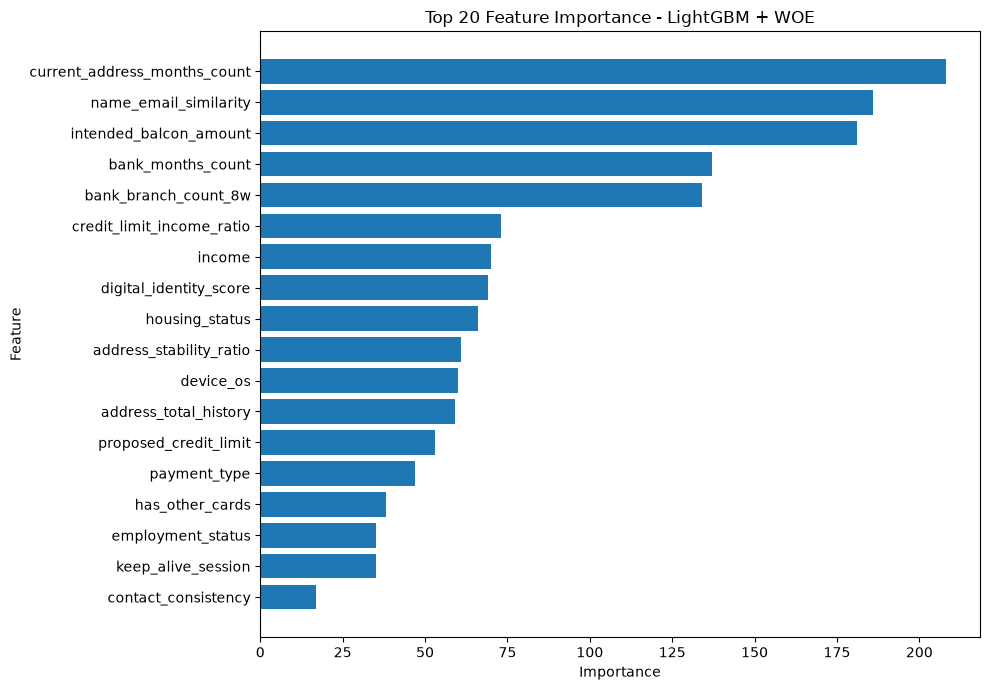

In [87]:
df_plot = (
    feature_importance_lgbm_woe
    .head(20)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(df_plot["Feature"], df_plot["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importance - LightGBM + WOE")

plt.tight_layout()
plt.show()

### Comparativo

In [88]:
# ============================================================
# Comparativo LightGBM
# OHE vs WOE
# ============================================================

resultados_lgbm = [
    {"Modelo": "LightGBM + OHE", "Dataset": "Train Natural", **result_train_lgbm_ohe},
    {"Modelo": "LightGBM + OHE", "Dataset": "Validation", **result_val_lgbm_ohe},
    {"Modelo": "LightGBM + OHE", "Dataset": "Test", **result_test_lgbm_ohe},
    {"Modelo": "LightGBM + OHE", "Dataset": "OOT", **result_oot_lgbm_ohe},

    {"Modelo": "LightGBM + WOE", "Dataset": "Train Natural", **result_train_lgbm_woe},
    {"Modelo": "LightGBM + WOE", "Dataset": "Validation", **result_val_lgbm_woe},
    {"Modelo": "LightGBM + WOE", "Dataset": "Test", **result_test_lgbm_woe},
    {"Modelo": "LightGBM + WOE", "Dataset": "OOT", **result_oot_lgbm_woe},
]

df_comparacion_lgbm = pd.DataFrame(resultados_lgbm)

columnas_metricas = [
    "Modelo",
    "Dataset",
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]

df_comparacion_lgbm = df_comparacion_lgbm[columnas_metricas].copy()

columnas_numericas_metricas = [
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]

df_comparacion_lgbm[columnas_numericas_metricas] = (
    df_comparacion_lgbm[columnas_numericas_metricas].round(4)
)

display(df_comparacion_lgbm)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr
0,LightGBM + OHE,Train Natural,0.93,0.1264,0.8947,0.9813,0.1757,0.2369,0.2018,0.0112
1,LightGBM + OHE,Validation,0.93,0.1569,0.8832,0.9809,0.2239,0.2488,0.2356,0.0103
2,LightGBM + OHE,Test,0.93,0.1486,0.8812,0.9777,0.2097,0.2386,0.2232,0.0122
3,LightGBM + OHE,OOT,0.93,0.1754,0.8864,0.9790,0.2543,0.2199,0.2358,0.0097
4,LightGBM + WOE,Train Natural,0.93,0.1268,0.8890,0.9817,0.1812,0.2378,0.2057,0.0108
5,LightGBM + WOE,Validation,0.93,0.1575,0.8829,0.9816,0.2292,0.2339,0.2315,0.0094
6,LightGBM + WOE,Test,0.93,0.1523,0.8801,0.9783,0.2120,0.2290,0.2202,0.0116
7,LightGBM + WOE,OOT,0.93,0.1816,0.8867,0.9792,0.2588,0.2206,0.2382,0.0095


## Catboost

### Funcion Objetivo

In [89]:
# ============================================================
# Función objetivo CatBoost
# ============================================================

def catboost_evaluate(
    depth,
    learning_rate,
    iterations,
    l2_leaf_reg,
    random_strength,
    bagging_temperature
):
    """
    Entrena CatBoost sobre Train balanceado y maximiza
    PR-AUC sobre Validation natural.
    """

    params = {
        "loss_function": "Logloss",
        "depth": int(round(depth)),
        "learning_rate": learning_rate,
        "iterations": int(round(iterations)),
        "l2_leaf_reg": l2_leaf_reg,
        "random_strength": random_strength,
        "bagging_temperature": bagging_temperature,
        "random_seed": 150718,
        "verbose": 0,
        "allow_writing_files": False
    }

    model = CatBoostClassifier(**params)

    model.fit(
        X_train_cat_resampled,
        y_train_resampled,
        cat_features=CAT_FEATURES_CATBOOST
    )

    y_val_pred_proba = model.predict_proba(X_val_cat)[:, 1]

    return average_precision_score(
        y_val,
        y_val_pred_proba
    )

### Espacio de Busqueda

In [90]:
# ============================================================
# Espacio de búsqueda CatBoost
# ============================================================

params_pbounds_catboost = {
    "depth": (4, 8),
    "learning_rate": (0.01, 0.15),
    "iterations": (100, 500),
    "l2_leaf_reg": (1, 20),
    "random_strength": (0, 10),
    "bagging_temperature": (0, 10)
}

### Optimizacion Bayesiana

In [91]:
# ============================================================
# Bayesian Optimization
# CatBoost
# ============================================================

catboost_bo = BayesianOptimization(
    f=catboost_evaluate,
    pbounds=params_pbounds_catboost,
    random_state=42,
    verbose=2
)

catboost_bo.maximize(
    init_points=5,
    n_iter=15
)

|   iter    |  target   | baggin... |   depth   | iterat... | l2_lea... | learni... | random... |
-------------------------------------------------------------------------------------------------
| 1         | 0.1474    | 3.745     | 7.803     | 392.8     | 12.37     | 0.03184   | 1.56      |
| 2         | 0.1236    | 0.5808    | 7.465     | 340.4     | 14.45     | 0.01288   | 9.699     |
| 3         | 0.1425    | 8.324     | 4.849     | 172.7     | 4.485     | 0.05259   | 5.248     |
| 4         | 0.1531    | 4.319     | 5.165     | 344.7     | 3.65      | 0.0509    | 3.664     |
| 5         | 0.1552    | 4.561     | 7.141     | 179.9     | 10.77     | 0.09294   | 0.4645    |
| 6         | 0.1522    | 7.535     | 7.43      | 336.1     | 7.96      | 0.07174   | 7.862     |
| 7         | 0.1488    | 1.242     | 6.851     | 396.3     | 3.972     | 0.09873   | 8.849     |
| 8         | 0.1458    | 2.104     | 7.97      | 185.6     | 14.32     | 0.07939   | 2.877     |
| 9         | 0.1568

### Mejores parametros

In [92]:
# ============================================================
# Mejores parámetros CatBoost
# ============================================================

best_params_catboost = catboost_bo.max["params"].copy()

best_params_catboost["depth"] = int(round(best_params_catboost["depth"]))
best_params_catboost["iterations"] = int(round(best_params_catboost["iterations"]))

print("\nMejores parámetros CatBoost:")
for parametro, valor in best_params_catboost.items():
    print(f"{parametro}: {valor}")

print(
    f"\nMejor PR-AUC Validation: "
    f"{catboost_bo.max['target']:.6f}"
)


Mejores parámetros CatBoost:
bagging_temperature: 4.378305409413836
depth: 5
iterations: 156
l2_leaf_reg: 1.0288066969210625
learning_rate: 0.14971873661620339
random_strength: 5.328185896838999

Mejor PR-AUC Validation: 0.157759


### Training

In [93]:
# ============================================================
# Modelo final CatBoost
# ============================================================

catboost_best = CatBoostClassifier(
    **best_params_catboost,
    loss_function="Logloss",
    random_seed=150718,
    verbose=0,
    allow_writing_files=False
)

catboost_best.fit(
    X_train_cat_resampled,
    y_train_resampled,
    cat_features=CAT_FEATURES_CATBOOST
)

print("CatBoost entrenado correctamente.")

CatBoost entrenado correctamente.


### Probabilidades en Train y Val

In [94]:
# ============================================================
# Probabilidades Train Natural y Validation
# ============================================================

y_train_pred_proba_catboost = (
    catboost_best.predict_proba(X_train_cat)[:, 1]
)

y_val_pred_proba_catboost = (
    catboost_best.predict_proba(X_val_cat)[:, 1]
)

### Threshold

In [95]:
# ============================================================
# Threshold CatBoost
# ============================================================

threshold_catboost, df_threshold_catboost = encontrar_mejor_threshold(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_catboost
)

Mejor threshold según Validation: 0.92
Precision: 0.2216
Recall: 0.2651
F1: 0.2414


### Evaluation

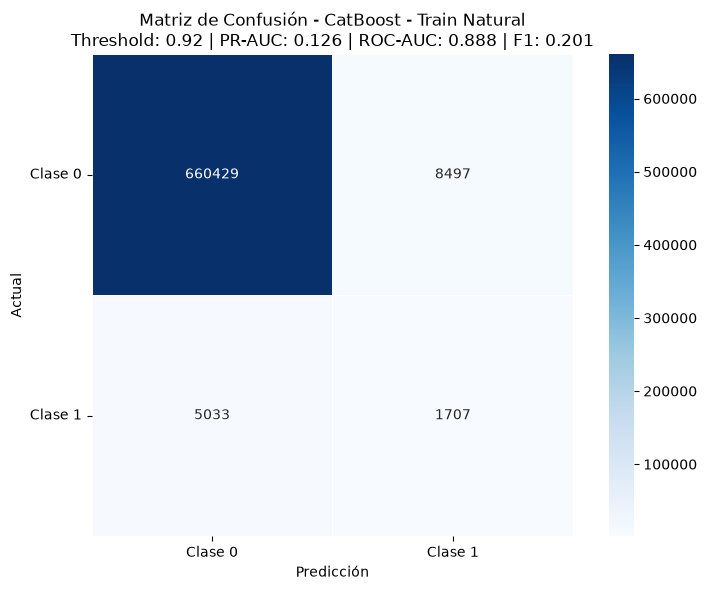


Reporte de Clasificación - CatBoost - Train Natural
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9924    0.9873    0.9899    668926
     Clase 1     0.1673    0.2533    0.2015      6740

    accuracy                         0.9800    675666
   macro avg     0.5799    0.6203    0.5957    675666
weighted avg     0.9842    0.9800    0.9820    675666

PR-AUC:    0.1257
ROC-AUC:   0.8876
Accuracy:  0.9800
Precision: 0.1673
Recall:    0.2533
F1-Score:  0.2015
FPR:       0.0127


In [96]:
# ============================================================
# CatBoost - Train Natural
# ============================================================

result_train_catboost = plot_confusion_matrix_heatmap(
    y_true=y_train,
    y_pred_proba=y_train_pred_proba_catboost,
    model_name="CatBoost - Train Natural",
    threshold=threshold_catboost
)

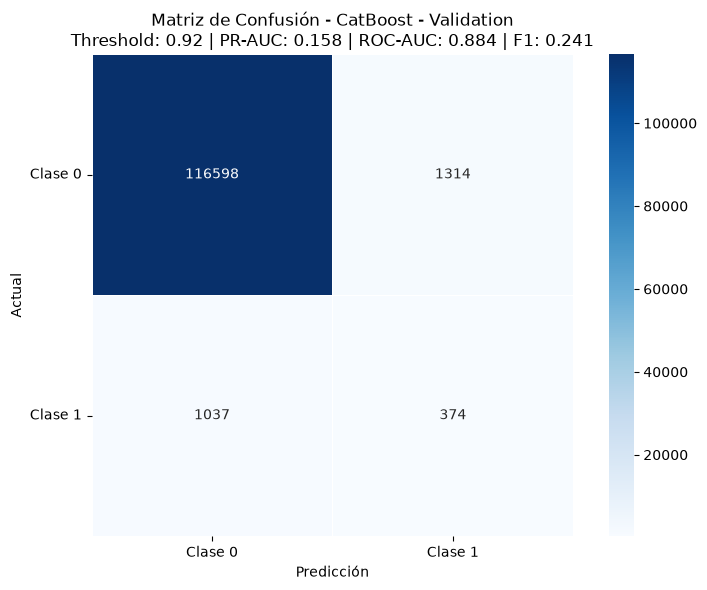


Reporte de Clasificación - CatBoost - Validation
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9912    0.9889    0.9900    117912
     Clase 1     0.2216    0.2651    0.2414      1411

    accuracy                         0.9803    119323
   macro avg     0.6064    0.6270    0.6157    119323
weighted avg     0.9821    0.9803    0.9812    119323

PR-AUC:    0.1578
ROC-AUC:   0.8835
Accuracy:  0.9803
Precision: 0.2216
Recall:    0.2651
F1-Score:  0.2414
FPR:       0.0111


In [97]:
# ============================================================
# CatBoost - Validation
# ============================================================

result_val_catboost = plot_confusion_matrix_heatmap(
    y_true=y_val,
    y_pred_proba=y_val_pred_proba_catboost,
    model_name="CatBoost - Validation",
    threshold=threshold_catboost
)

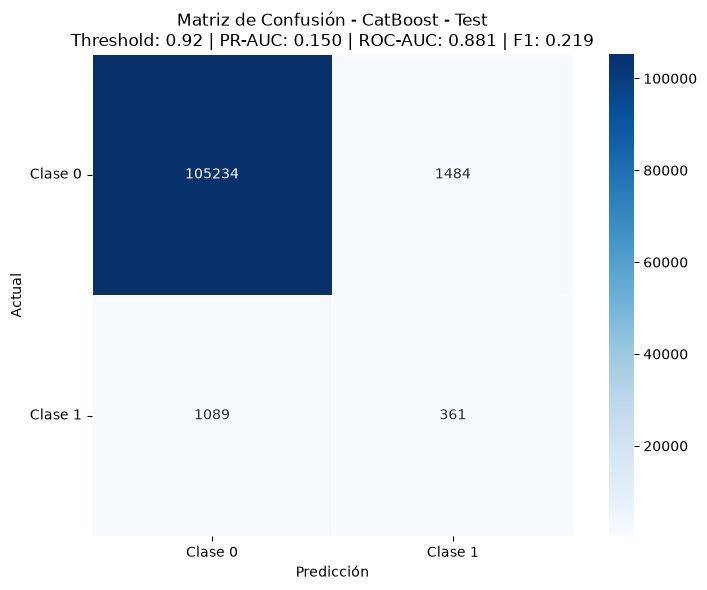


Reporte de Clasificación - CatBoost - Test
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9898    0.9861    0.9879    106718
     Clase 1     0.1957    0.2490    0.2191      1450

    accuracy                         0.9762    108168
   macro avg     0.5927    0.6175    0.6035    108168
weighted avg     0.9791    0.9762    0.9776    108168

PR-AUC:    0.1497
ROC-AUC:   0.8809
Accuracy:  0.9762
Precision: 0.1957
Recall:    0.2490
F1-Score:  0.2191
FPR:       0.0139


In [98]:
# ============================================================
# CatBoost - Test
# ============================================================

y_test_pred_proba_catboost = (
    catboost_best.predict_proba(X_test_cat)[:, 1]
)

result_test_catboost = plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba_catboost,
    model_name="CatBoost - Test",
    threshold=threshold_catboost
)

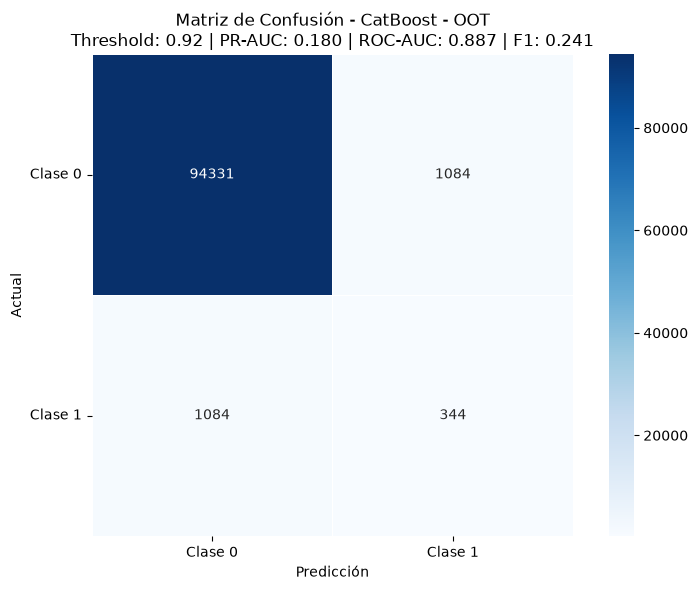


Reporte de Clasificación - CatBoost - OOT
Threshold utilizado: 0.92

              precision    recall  f1-score   support

     Clase 0     0.9886    0.9886    0.9886     95415
     Clase 1     0.2409    0.2409    0.2409      1428

    accuracy                         0.9776     96843
   macro avg     0.6148    0.6148    0.6148     96843
weighted avg     0.9776    0.9776    0.9776     96843

PR-AUC:    0.1799
ROC-AUC:   0.8871
Accuracy:  0.9776
Precision: 0.2409
Recall:    0.2409
F1-Score:  0.2409
FPR:       0.0114


In [99]:
# ============================================================
# CatBoost - OOT
# ============================================================

y_oot_pred_proba_catboost = (
    catboost_best.predict_proba(X_oot_cat)[:, 1]
)

result_oot_catboost = plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba_catboost,
    model_name="CatBoost - OOT",
    threshold=threshold_catboost
)

### Feature Importance

In [100]:
# ============================================================
# Feature Importance
# CatBoost
# ============================================================

feature_importance_catboost = pd.DataFrame({
    "Feature": X_train_cat_resampled.columns,
    "Importance": catboost_best.get_feature_importance()
})

feature_importance_catboost = (
    feature_importance_catboost
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance_catboost)

,Feature,Importance
0,housing_status,18.960118
1,device_os,12.234458
2,current_address_months_count,9.175271
3,name_email_similarity,7.575287
4,digital_identity_score,7.101592
5,has_other_cards,5.457299
6,keep_alive_session,5.456207
7,employment_status,4.850634
8,bank_branch_count_8w,4.377043
9,income,4.313514


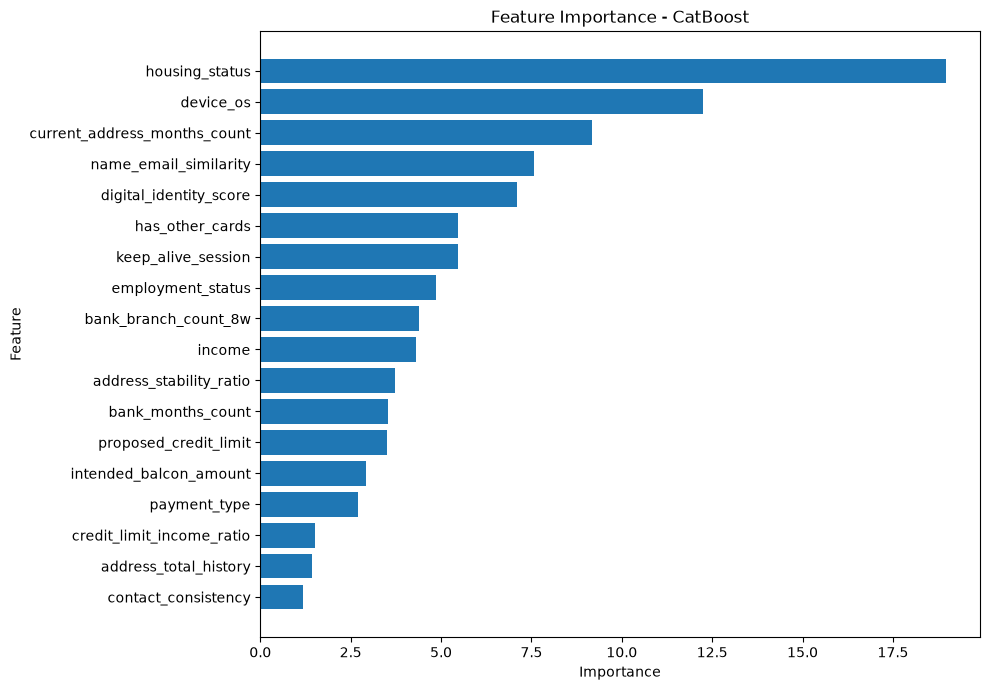

In [101]:
# ============================================================
# Feature Importance - Gráfico
# ============================================================

df_plot = (
    feature_importance_catboost
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(df_plot["Feature"], df_plot["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - CatBoost")

plt.tight_layout()
plt.show()

In [102]:
# ============================================================
# Tabla de métricas CatBoost
# ============================================================

resultados_catboost = [
    {"Modelo": "CatBoost", "Dataset": "Train Natural", **result_train_catboost},
    {"Modelo": "CatBoost", "Dataset": "Validation", **result_val_catboost},
    {"Modelo": "CatBoost", "Dataset": "Test", **result_test_catboost},
    {"Modelo": "CatBoost", "Dataset": "OOT", **result_oot_catboost},
]

df_comparacion_catboost = pd.DataFrame(resultados_catboost)

columnas_metricas = [
    "Modelo",
    "Dataset",
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]

df_comparacion_catboost = df_comparacion_catboost[columnas_metricas].copy()

columnas_numericas_metricas = [
    "threshold",
    "pr_auc",
    "auc_roc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "fpr"
]

df_comparacion_catboost[columnas_numericas_metricas] = (
    df_comparacion_catboost[columnas_numericas_metricas].round(4)
)

display(df_comparacion_catboost)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr
0,CatBoost,Train Natural,0.92,0.1257,0.8876,0.9800,0.1673,0.2533,0.2015,0.0127
1,CatBoost,Validation,0.92,0.1578,0.8835,0.9803,0.2216,0.2651,0.2414,0.0111
2,CatBoost,Test,0.92,0.1497,0.8809,0.9762,0.1957,0.2490,0.2191,0.0139
3,CatBoost,OOT,0.92,0.1799,0.8871,0.9776,0.2409,0.2409,0.2409,0.0114


# Comparativo Resultados

In [103]:
# ============================================================
# Comparativo general - 5 modelos
# ============================================================

df_comparacion_general = pd.concat(
    [
        df_comparacion_modelos,
        df_comparacion_lgbm,
        df_comparacion_catboost
    ],
    ignore_index=True
)

display(df_comparacion_general)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr
0,XGBoost + OHE,Train Natural,0.92,0.1268,0.8885,0.9793,0.1670,0.2684,0.2059,0.0135
1,XGBoost + OHE,Validation,0.92,0.1589,0.8840,0.9796,0.2161,0.2764,0.2425,0.0120
2,XGBoost + OHE,Test,0.92,0.1488,0.8803,0.9756,0.1972,0.2676,0.2270,0.0148
3,XGBoost + OHE,OOT,0.92,0.1778,0.8874,0.9777,0.2508,0.2584,0.2546,0.0115
4,XGBoost + WOE,Train Natural,0.93,0.1251,0.8867,0.9822,0.1844,0.2282,0.2040,0.0102
5,XGBoost + WOE,Validation,0.93,0.1579,0.8824,0.9817,0.2303,0.2346,0.2324,0.0094
6,XGBoost + WOE,Test,0.93,0.1486,0.8791,0.9780,0.2091,0.2303,0.2192,0.0118
7,XGBoost + WOE,OOT,0.93,0.1768,0.8855,0.9790,0.2469,0.2080,0.2258,0.0095
8,LightGBM + OHE,Train Natural,0.93,0.1264,0.8947,0.9813,0.1757,0.2369,0.2018,0.0112
9,LightGBM + OHE,Validation,0.93,0.1569,0.8832,0.9809,0.2239,0.2488,0.2356,0.0103


## Comparativo Test y OOT

In [104]:
# ============================================================
# Comparativo final - Test y OOT
# ============================================================

df_comparacion_final = (
    df_comparacion_general[
        df_comparacion_general["Dataset"].isin(["Test", "OOT"])
    ]
    .sort_values(
        ["Dataset", "pr_auc"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(df_comparacion_final)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr
0,LightGBM + WOE,OOT,0.93,0.1816,0.8867,0.9792,0.2588,0.2206,0.2382,0.0095
1,CatBoost,OOT,0.92,0.1799,0.8871,0.9776,0.2409,0.2409,0.2409,0.0114
2,XGBoost + OHE,OOT,0.92,0.1778,0.8874,0.9777,0.2508,0.2584,0.2546,0.0115
3,XGBoost + WOE,OOT,0.93,0.1768,0.8855,0.9790,0.2469,0.2080,0.2258,0.0095
4,LightGBM + OHE,OOT,0.93,0.1754,0.8864,0.9790,0.2543,0.2199,0.2358,0.0097
5,LightGBM + WOE,Test,0.93,0.1523,0.8801,0.9783,0.2120,0.2290,0.2202,0.0116
6,CatBoost,Test,0.92,0.1497,0.8809,0.9762,0.1957,0.2490,0.2191,0.0139
7,XGBoost + OHE,Test,0.92,0.1488,0.8803,0.9756,0.1972,0.2676,0.2270,0.0148
8,XGBoost + WOE,Test,0.93,0.1486,0.8791,0.9780,0.2091,0.2303,0.2192,0.0118
9,LightGBM + OHE,Test,0.93,0.1486,0.8812,0.9777,0.2097,0.2386,0.2232,0.0122


In [105]:
# ============================================================
# Ranking por PR-AUC
# ============================================================

df_comparacion_final["ranking_pr_auc"] = (
    df_comparacion_final
    .groupby("Dataset")["pr_auc"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(df_comparacion_final)

,Modelo,Dataset,threshold,pr_auc,auc_roc,accuracy,precision,recall,f1,fpr,ranking_pr_auc
0,LightGBM + WOE,OOT,0.93,0.1816,0.8867,0.9792,0.2588,0.2206,0.2382,0.0095,1
1,CatBoost,OOT,0.92,0.1799,0.8871,0.9776,0.2409,0.2409,0.2409,0.0114,2
2,XGBoost + OHE,OOT,0.92,0.1778,0.8874,0.9777,0.2508,0.2584,0.2546,0.0115,3
3,XGBoost + WOE,OOT,0.93,0.1768,0.8855,0.9790,0.2469,0.2080,0.2258,0.0095,4
4,LightGBM + OHE,OOT,0.93,0.1754,0.8864,0.9790,0.2543,0.2199,0.2358,0.0097,5
5,LightGBM + WOE,Test,0.93,0.1523,0.8801,0.9783,0.2120,0.2290,0.2202,0.0116,1
6,CatBoost,Test,0.92,0.1497,0.8809,0.9762,0.1957,0.2490,0.2191,0.0139,2
7,XGBoost + OHE,Test,0.92,0.1488,0.8803,0.9756,0.1972,0.2676,0.2270,0.0148,3
8,XGBoost + WOE,Test,0.93,0.1486,0.8791,0.9780,0.2091,0.2303,0.2192,0.0118,4
9,LightGBM + OHE,Test,0.93,0.1486,0.8812,0.9777,0.2097,0.2386,0.2232,0.0122,4


In [106]:
threshold_lgbm_woe_final = 0.82

# Modelo Ganador Scores

In [107]:
# ============================================================
# SCORE ANALYSIS - LightGBM + WOE
# Dataset principal: OOT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Score de probabilidad de fraude
y_oot_score_lgbm_woe = lgbm_woe.predict_proba(X_oot_woe)[:, 1]

df_score_oot = pd.DataFrame({
    "score": y_oot_score_lgbm_woe,
    "target": y_oot.to_numpy()
})

print("Observaciones:", len(df_score_oot))
print("Fraudes:", df_score_oot["target"].sum())
print("Fraud rate global:", df_score_oot["target"].mean())
print("\nDistribución del score:")
display(df_score_oot["score"].describe())

Observaciones: 96843
Fraudes: 1428
Fraud rate global: 0.014745515938167962

Distribución del score:


count    96843.000000
mean         0.269347
std          0.252278
min          0.001846
25%          0.068384
50%          0.173839
75%          0.410816
max          0.994170
Name: score, dtype: float64

In [108]:
# ============================================================
# CREACIÓN DE DECILES
# D1 = menor riesgo
# D10 = mayor riesgo
# ============================================================

df_score_oot["decil"] = (
    pd.qcut(
        df_score_oot["score"],
        q=10,
        labels=False,
        duplicates="drop"
    ) + 1
)

df_score_oot.head()

,score,target,decil
0,0.171454,0,5
1,0.363644,0,8
2,0.052101,0,2
3,0.171462,0,5
4,0.018322,0,1


In [109]:
# ============================================================
# TABLA DE PERFORMANCE POR DECIL
# ============================================================

fraud_rate_global = df_score_oot["target"].mean()
total_fraudes = df_score_oot["target"].sum()

df_deciles = (
    df_score_oot
    .groupby("decil", observed=False)
    .agg(
        n=("target", "size"),
        fraud_count=("target", "sum"),
        event_rate=("target", "mean"),
        score_min=("score", "min"),
        score_mean=("score", "mean"),
        score_max=("score", "max")
    )
    .reset_index()
)

# Lift del decil respecto a la tasa global de fraude
df_deciles["lift"] = (
    df_deciles["event_rate"]
    / fraud_rate_global
)

# Porcentaje de todos los fraudes contenidos en cada decil
df_deciles["fraud_capture"] = (
    df_deciles["fraud_count"]
    / total_fraudes
)

display(df_deciles.round(4))

,decil,n,fraud_count,event_rate,score_min,score_mean,score_max,lift,fraud_capture
0,1,9685,3,0.0003,0.0018,0.0200,0.0314,0.0210,0.0021
1,2,9684,7,0.0007,0.0314,0.0428,0.0549,0.0490,0.0049
2,3,9684,14,0.0014,0.0549,0.0688,0.0840,0.0980,0.0098
3,4,9684,16,0.0017,0.0840,0.1023,0.1221,0.1120,0.0112
4,5,9685,25,0.0026,0.1221,0.1465,0.1738,0.1751,0.0175
5,6,9684,38,0.0039,0.1739,0.2074,0.2445,0.2661,0.0266
6,7,9684,66,0.0068,0.2445,0.2915,0.3448,0.4622,0.0462
7,8,9684,100,0.0103,0.3448,0.4119,0.4881,0.7003,0.0700
8,9,9684,211,0.0218,0.4881,0.5817,0.6872,1.4776,0.1478
9,10,9685,948,0.0979,0.6872,0.8206,0.9942,6.6382,0.6639


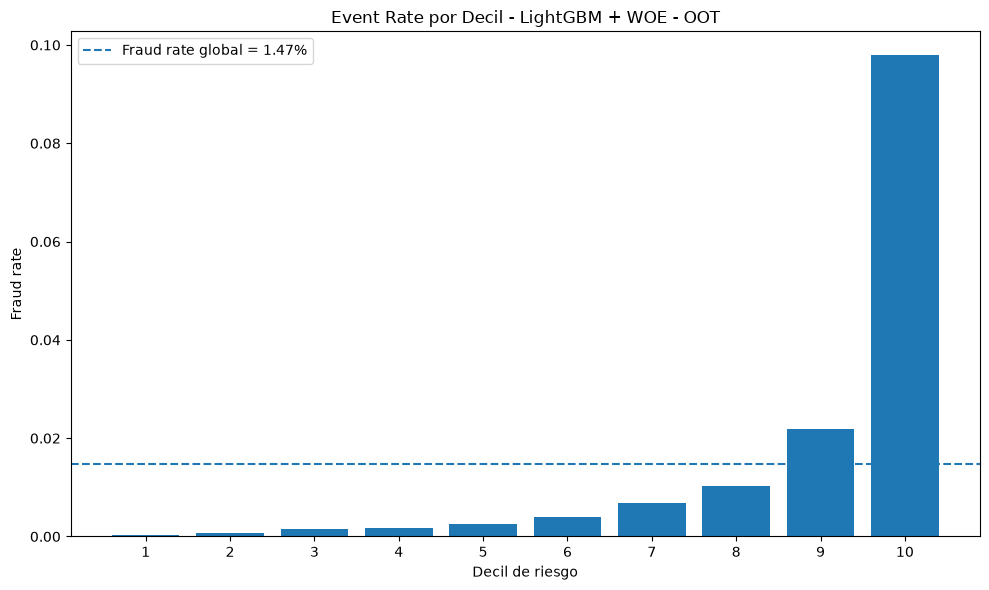

In [110]:
# ============================================================
# EVENT RATE POR DECIL
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    df_deciles["decil"].astype(str),
    df_deciles["event_rate"]
)

plt.axhline(
    fraud_rate_global,
    linestyle="--",
    label=f"Fraud rate global = {fraud_rate_global:.2%}"
)

plt.xlabel("Decil de riesgo")
plt.ylabel("Fraud rate")
plt.title("Event Rate por Decil - LightGBM + WOE - OOT")

plt.legend()
plt.tight_layout()
plt.show()

variable score_lgbm_woe
---------------------------------------------------------
                 Bin   Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.06)   21072     0.1766      21068      4      0.0002  4.1436   
1       [0.06, 0.11)   16135     0.1352      16126      9      0.0006  3.0653   
2       [0.11, 0.15)   11459     0.0960      11442     17      0.0015  2.0862   
3       [0.15, 0.22)   14682     0.1230      14636     46      0.0031  1.3370   
4       [0.22, 0.30)   11693     0.0980      11644     49      0.0042  1.0451   
5       [0.30, 0.35)    6368     0.0534       6330     38      0.0060  0.6898   
6       [0.35, 0.43)    7030     0.0589       6983     47      0.0067  0.5754   
7       [0.43, 0.56)   10368     0.0869      10255    113      0.0109  0.0825   
8       [0.56, 0.66)    6269     0.0525       6134    135      0.0215 -0.6093   
9       [0.66, 0.82)    8147     0.0683       7880    267      0.0328 -1.0408   
10       [0.82, inf)    610

C:\Users\Renzo\AppData\Local\Temp\ipykernel_27140\1750549943.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b = tabla[tabla.index == 'Totals']['IV'][0]


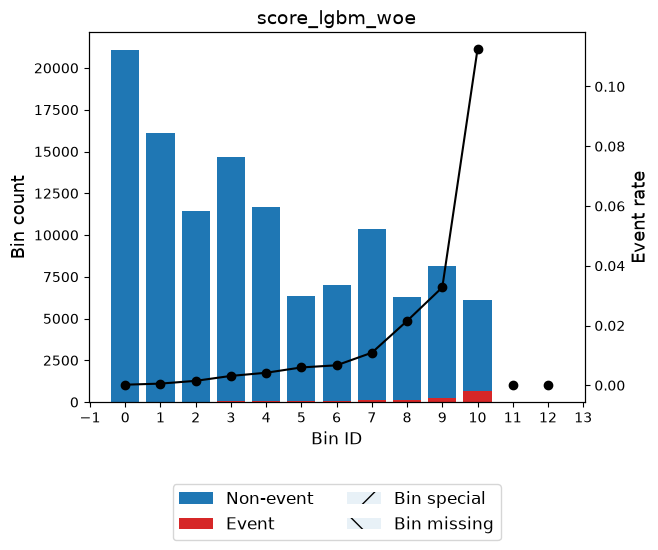

In [111]:
# ============================================================
# ANÁLISIS DEL SCORE - VALIDATION
# ============================================================

df_score_val = val_data.copy()

df_score_val["score_lgbm_woe"] = (
    lgbm_woe.predict_proba(X_val_woe)[:, 1]
)

df_result_num_score = plot_analisis(
    data=df_score_val.copy(),
    analysis_type="numerical",
    analysis_columns=["score_lgbm_woe"],
    target="target",
    umbral_iv=0.00
)

variable score_lgbm_woe
---------------------------------------------------------
                 Bin  Count  Count (%)  Non-event  Event  Event rate     WoE  \
0       (-inf, 0.03)   8202     0.0847       8201      1      0.0001  4.8101   
1       [0.03, 0.06)  12397     0.1280      12388      9      0.0007  3.0253   
2       [0.06, 0.11)  14964     0.1545      14939     25      0.0017  2.1909   
3       [0.11, 0.16)  10942     0.1130      10921     21      0.0019  2.0520   
4       [0.16, 0.24)  11245     0.1161      11203     42      0.0037  1.3843   
5       [0.24, 0.30)   6020     0.0622       5990     30      0.0050  1.0947   
6       [0.30, 0.36)   4918     0.0508       4874     44      0.0089  0.5055   
7       [0.36, 0.49)   8813     0.0910       8716     97      0.0110  0.2962   
8       [0.49, 0.68)   9312     0.0962       9110    202      0.0217 -0.3931   
9       [0.68, 0.81)   4943     0.0510       4721    222      0.0449 -1.1449   
10       [0.81, inf)   5087     0.0525

C:\Users\Renzo\AppData\Local\Temp\ipykernel_27140\1750549943.py:31: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b = tabla[tabla.index == 'Totals']['IV'][0]


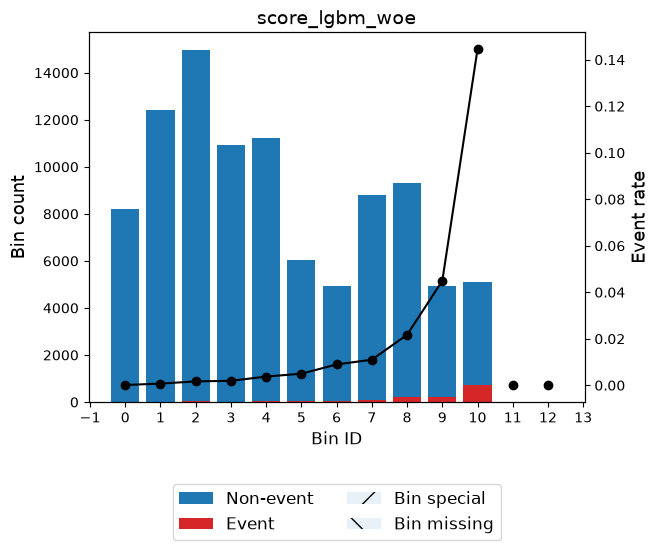

In [112]:
# ============================================================
# ANÁLISIS DEL SCORE - OOT
# ============================================================

df_score_oot = oot_data.copy()

df_score_oot["score_lgbm_woe"] = (
    lgbm_woe.predict_proba(X_oot_woe)[:, 1]
)

df_result_num_score_oot = plot_analisis(
    data=df_score_oot.copy(),
    analysis_type="numerical",
    analysis_columns=["score_lgbm_woe"],
    target="target",
    umbral_iv=0.00
)

## Scores

In [113]:
# ============================================================
# BANDAS DE RIESGO - LightGBM + WOE
# Cortes definidos sobre Validation
# ============================================================

CUT_APROBAR = 0.43
CUT_AUTH = 0.56
CUT_MANUAL = 0.82

def crear_bandas_score(df, score_col="score_lgbm_woe"):
    df = df.copy()

    df["banda_riesgo"] = np.select(
        [
            df[score_col] < CUT_APROBAR,
            df[score_col] < CUT_AUTH,
            df[score_col] < CUT_MANUAL,
            df[score_col] >= CUT_MANUAL
        ],
        [
            "4. Aprobar",
            "3. Autenticación adicional",
            "2. Revisión manual",
            "1. Bloqueo automático"
        ],
        default="5. NA"
    )

    return df

In [114]:
# ============================================================
# BANDAS DE RIESGO - LightGBM + WOE
# Cortes definidos sobre Validation
# ============================================================

CUT_APROBAR = 0.43
CUT_AUTH = 0.56
CUT_MANUAL = 0.82

def crear_bandas_score(df, score_col="score_lgbm_woe"):
    df = df.copy()

    df["banda_riesgo"] = np.select(
        [
            df[score_col] < CUT_APROBAR,
            df[score_col] < CUT_AUTH,
            df[score_col] < CUT_MANUAL,
            df[score_col] >= CUT_MANUAL
        ],
        [
            "4. Aprobar",
            "3. Autenticación adicional",
            "2. Revisión manual",
            "1. Bloqueo automático"
        ],
        default="5. NA"
    )

    return df

In [115]:
# ============================================================
# SCORES POR DATASET
# ============================================================

df_score_val = val_data.copy()
df_score_val["score_lgbm_woe"] = lgbm_woe.predict_proba(X_val_woe)[:, 1]
df_score_val["dataset"] = "Validation"

df_score_test = test_data.copy()
df_score_test["score_lgbm_woe"] = lgbm_woe.predict_proba(X_test_woe)[:, 1]
df_score_test["dataset"] = "Test"

df_score_oot = oot_data.copy()
df_score_oot["score_lgbm_woe"] = lgbm_woe.predict_proba(X_oot_woe)[:, 1]
df_score_oot["dataset"] = "OOT"

df_score_val = crear_bandas_score(df_score_val)
df_score_test = crear_bandas_score(df_score_test)
df_score_oot = crear_bandas_score(df_score_oot)

In [116]:
# ============================================================
# MÉTRICAS POR BANDA
# ============================================================

def resumen_bandas_score(df):
    total_registros = len(df)
    total_fraudes = df["target"].sum()
    total_no_fraudes = (df["target"] == 0).sum()
    fraud_rate_global = df["target"].mean()

    resumen = (
        df
        .groupby("banda_riesgo", observed=False)
        .agg(
            n=("target", "size"),
            fraud_count=("target", "sum"),
            score_min=("score_lgbm_woe", "min"),
            score_mean=("score_lgbm_woe", "mean"),
            score_max=("score_lgbm_woe", "max")
        )
        .reset_index()
    )

    resumen["non_fraud_count"] = resumen["n"] - resumen["fraud_count"]

    # % de la población total que cae en cada banda
    resumen["population_pct"] = resumen["n"] / total_registros

    # Event rate / Precision de la banda
    resumen["event_rate"] = resumen["fraud_count"] / resumen["n"]

    # % de todos los fraudes capturados por la banda
    resumen["fraud_capture"] = resumen["fraud_count"] / total_fraudes

    # Lift respecto al fraud rate global
    resumen["lift"] = resumen["event_rate"] / fraud_rate_global

    # De todos los clientes legítimos, qué proporción cae en esta banda
    resumen["FPR_band"] = resumen["non_fraud_count"] / total_no_fraudes

    # Proporción de clientes legítimos dentro de la propia banda
    resumen["false_alert_share"] = resumen["non_fraud_count"] / resumen["n"]

    # Orden de mayor a menor riesgo
    resumen["orden"] = resumen["banda_riesgo"].str[0].astype(int)

    resumen = (
        resumen
        .sort_values("orden")
        .reset_index(drop=True)
    )

    # Acumulados desde la banda más riesgosa
    resumen["population_cum"] = resumen["population_pct"].cumsum()
    resumen["fraud_capture_cum"] = resumen["fraud_capture"].cumsum()

    resumen = resumen.drop(columns="orden")

    return resumen

In [117]:
df_bandas_val = resumen_bandas_score(df_score_val)
df_bandas_test = resumen_bandas_score(df_score_test)
df_bandas_oot = resumen_bandas_score(df_score_oot)

In [118]:
display(df_bandas_oot.round(4))

,banda_riesgo,n,fraud_count,score_min,score_mean,score_max,non_fraud_count,population_pct,event_rate,fraud_capture,lift,FPR_band,false_alert_share,population_cum,fraud_capture_cum
0,1. Bloqueo automático,4715,701,0.8200,0.8937,0.9942,4014,0.0487,0.1487,0.4909,10.0827,0.0421,0.8513,0.0487,0.4909
1,2. Revisión manual,10734,377,0.5600,0.6817,0.8200,10357,0.1108,0.0351,0.2640,2.3819,0.1085,0.9649,0.1595,0.7549
2,3. Autenticación adicional,7408,122,0.4300,0.4924,0.5600,7286,0.0765,0.0165,0.0854,1.1169,0.0764,0.9835,0.2360,0.8403
3,4. Aprobar,73986,228,0.0018,0.1474,0.4300,73758,0.7640,0.0031,0.1597,0.2090,0.7730,0.9969,1.0000,1.0000


In [119]:
columnas_bandas = [
    "banda_riesgo",
    "n",
    "population_pct",
    "fraud_count",
    "event_rate",
    "lift",
    "fraud_capture",
    "fraud_capture_cum",
    "FPR_band",
    "false_alert_share",
    "score_min",
    "score_mean",
    "score_max"
]

display(
    df_bandas_oot[columnas_bandas].round(4)
)

,banda_riesgo,n,population_pct,fraud_count,event_rate,lift,fraud_capture,fraud_capture_cum,FPR_band,false_alert_share,score_min,score_mean,score_max
0,1. Bloqueo automático,4715,0.0487,701,0.1487,10.0827,0.4909,0.4909,0.0421,0.8513,0.8200,0.8937,0.9942
1,2. Revisión manual,10734,0.1108,377,0.0351,2.3819,0.2640,0.7549,0.1085,0.9649,0.5600,0.6817,0.8200
2,3. Autenticación adicional,7408,0.0765,122,0.0165,1.1169,0.0854,0.8403,0.0764,0.9835,0.4300,0.4924,0.5600
3,4. Aprobar,73986,0.7640,228,0.0031,0.2090,0.1597,1.0000,0.7730,0.9969,0.0018,0.1474,0.4300


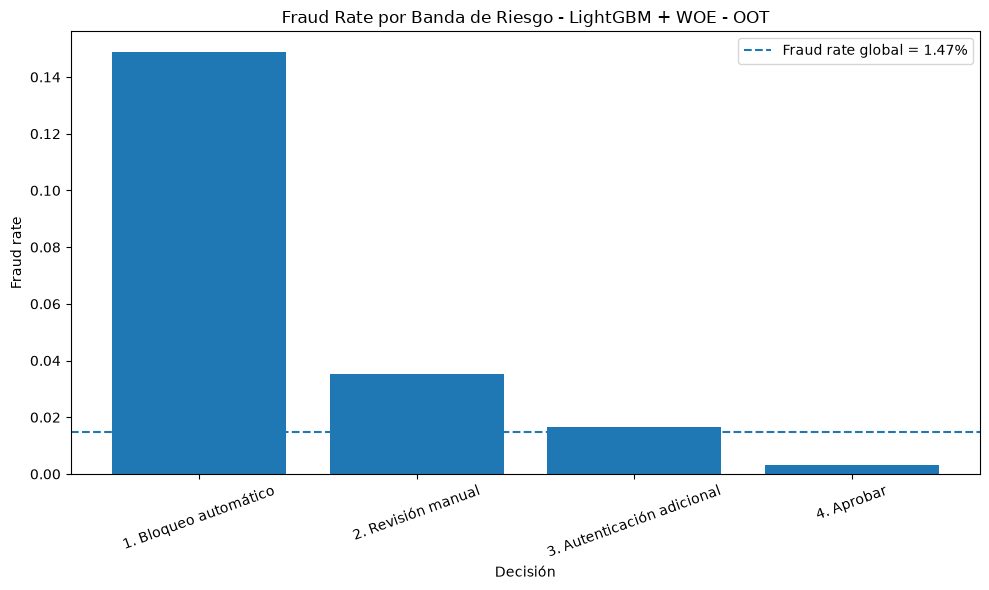

In [120]:
# ============================================================
# EVENT RATE POR BANDA - OOT
# ============================================================

df_plot = df_bandas_oot.copy()

plt.figure(figsize=(10, 6))

plt.bar(
    df_plot["banda_riesgo"],
    df_plot["event_rate"]
)

plt.axhline(
    df_score_oot["target"].mean(),
    linestyle="--",
    label=f"Fraud rate global = {df_score_oot['target'].mean():.2%}"
)

plt.ylabel("Fraud rate")
plt.xlabel("Decisión")
plt.title("Fraud Rate por Banda de Riesgo - LightGBM + WOE - OOT")

plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

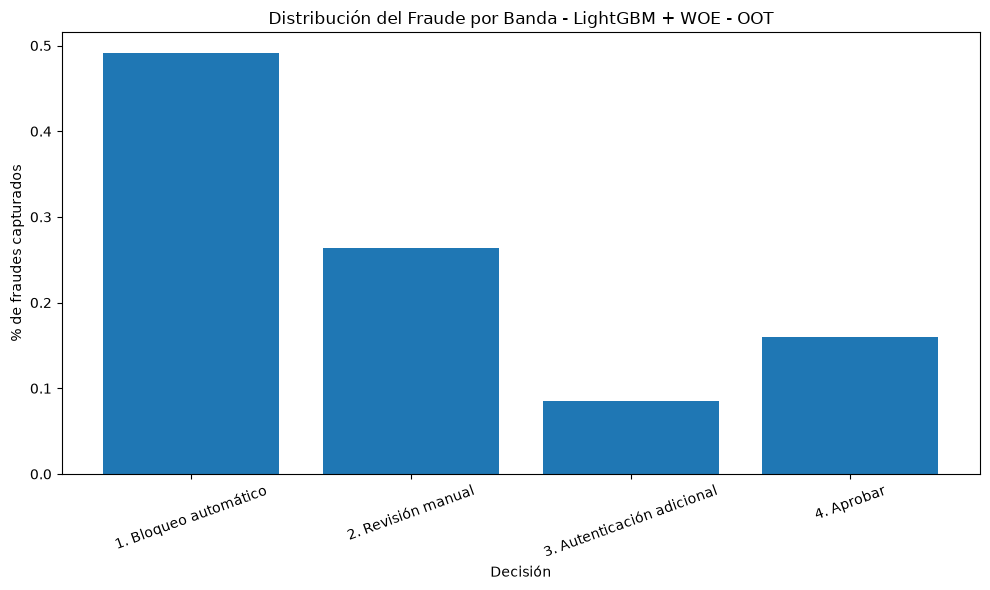

In [121]:
# ============================================================
# FRAUD CAPTURE POR BANDA - OOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    df_bandas_oot["banda_riesgo"],
    df_bandas_oot["fraud_capture"]
)

plt.ylabel("% de fraudes capturados")
plt.xlabel("Decisión")
plt.title("Distribución del Fraude por Banda - LightGBM + WOE - OOT")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Capacidad Operativa

In [122]:
# ============================================================
# CAPACIDAD OPERATIVA - REVISIÓN MANUAL
# ============================================================

import math

# Supuestos operativos
DIAS_LABORALES_MES = 22

# AS-IS del caso: cada analista maneja 138 casos diarios,
# situación asociada a sobrecarga operativa.
CASOS_ANALISTA_DIA_ASIS = 138

# Propuesta: reducir en 50% la carga diaria por analista.
REDUCCION_CARGA = 0.50
CASOS_ANALISTA_DIA_OBJETIVO = CASOS_ANALISTA_DIA_ASIS * (1 - REDUCCION_CARGA)

# Casos enviados a revisión manual según la banda de riesgo en OOT
casos_revision_manual = df_bandas_oot.loc[
    df_bandas_oot["banda_riesgo"] == "2. Revisión manual",
    "n"
].iloc[0]

# Carga operativa diaria
casos_manual_dia = casos_revision_manual / DIAS_LABORALES_MES

# Capacidad mensual objetivo de un analista
capacidad_analista_mes = CASOS_ANALISTA_DIA_OBJETIVO * DIAS_LABORALES_MES

# Analistas necesarios
analistas_equivalentes = casos_revision_manual / capacidad_analista_mes
analistas_requeridos = math.ceil(analistas_equivalentes)

print("====================================================")
print("CAPACIDAD OPERATIVA - REVISIÓN MANUAL")
print("====================================================")

print(f"Casos enviados a revisión manual al mes: {casos_revision_manual:,.0f}")
print(f"Días laborales asumidos: {DIAS_LABORALES_MES}")
print(f"Casos de revisión manual por día: {casos_manual_dia:,.1f}")

print("\n--- Capacidad por analista ---")
print(f"Carga AS-IS reportada: {CASOS_ANALISTA_DIA_ASIS} casos/día")
print(f"Reducción de carga propuesta: {REDUCCION_CARGA:.0%}")
print(f"Carga objetivo propuesta: {CASOS_ANALISTA_DIA_OBJETIVO:.0f} casos/día")
print(f"Capacidad mensual objetivo: {capacidad_analista_mes:,.0f} casos/analista")

print("\n--- Dimensionamiento ---")
print(f"Analistas equivalentes requeridos: {analistas_equivalentes:.2f}")
print(f"Analistas requeridos: {analistas_requeridos}")

print("\nCONCLUSIÓN")
print(
    f"Para atender {casos_revision_manual:,.0f} casos mensuales de revisión manual, "
    f"considerando 22 días laborales y una carga objetivo de "
    f"{CASOS_ANALISTA_DIA_OBJETIVO:.0f} casos diarios por analista "
    f"(50% menor a la carga AS-IS de {CASOS_ANALISTA_DIA_ASIS}), "
    f"se requieren {analistas_equivalentes:.2f} analistas equivalentes. "
    f"Por capacidad operativa, se propone asignar {analistas_requeridos} analistas."
)

CAPACIDAD OPERATIVA - REVISIÓN MANUAL
Casos enviados a revisión manual al mes: 10,734
Días laborales asumidos: 22
Casos de revisión manual por día: 487.9

--- Capacidad por analista ---
Carga AS-IS reportada: 138 casos/día
Reducción de carga propuesta: 50%
Carga objetivo propuesta: 69 casos/día
Capacidad mensual objetivo: 1,518 casos/analista

--- Dimensionamiento ---
Analistas equivalentes requeridos: 7.07
Analistas requeridos: 8

CONCLUSIÓN
Para atender 10,734 casos mensuales de revisión manual, considerando 22 días laborales y una carga objetivo de 69 casos diarios por analista (50% menor a la carga AS-IS de 138), se requieren 7.07 analistas equivalentes. Por capacidad operativa, se propone asignar 8 analistas.


# Fairness

In [123]:
# ============================================================
# FAIRNESS: auditoría de paridad + proxy analysis
# Modelo final candidato: LightGBM + WOE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Configuración
# ============================================================

# El threshold debe haber sido seleccionado previamente
# utilizando exclusivamente Validation.
THRESHOLD_FINAL = threshold_lgbm_woe_final

# Variables consideradas para fairness.
# customer_age fue excluida del modelo por ser sensible.
# income y employment_status permanecen en el modelo,
# pero serán monitoreadas explícitamente.
FAIRNESS_FEATURES = [
    "customer_age",
    "income",
    "employment_status"
]

# Variables que podrían actuar como proxies de características
# socioeconómicas o sensibles.
PROXY_CANDIDATES = [
    "credit_limit_income_ratio",
    "housing_status",
    "proposed_credit_limit"
]

print(f"Threshold final utilizado: {THRESHOLD_FINAL:.4f}")
print("Fairness features:", FAIRNESS_FEATURES)
print("Proxy candidates:", PROXY_CANDIDATES)



# ============================================================
# 2. Scores del modelo final
# ============================================================

y_test_pred_proba_fairness = lgbm_woe.predict_proba(X_test_woe)[:, 1]
y_oot_pred_proba_fairness = lgbm_woe.predict_proba(X_oot_woe)[:, 1]



# ============================================================
# 3. Construcción de bases de fairness
# ============================================================

fairness_test = test_data[FAIRNESS_FEATURES + PROXY_CANDIDATES].copy()
fairness_test["score"] = y_test_pred_proba_fairness
fairness_test["target"] = y_test.values
fairness_test["pred"] = (
    fairness_test["score"] >= THRESHOLD_FINAL
).astype(int)
fairness_test["dataset"] = "Test"

fairness_oot = oot_data[FAIRNESS_FEATURES + PROXY_CANDIDATES].copy()
fairness_oot["score"] = y_oot_pred_proba_fairness
fairness_oot["target"] = y_oot.values
fairness_oot["pred"] = (
    fairness_oot["score"] >= THRESHOLD_FINAL
).astype(int)
fairness_oot["dataset"] = "OOT"

print("Test:")
display(fairness_test.head())

print("\nOOT:")
display(fairness_oot.head())


# ============================================================
# 4. Funciones auxiliares
# ============================================================

def make_group_column(s, col_name):
    """
    Construye grupos interpretables para las variables utilizadas
    en la auditoría de fairness.
    """

    s = s.copy()

    # --------------------------------------------------------
    # Edad
    # --------------------------------------------------------
    if col_name == "customer_age":
        bins = [0, 25, 35, 45, 55, 65, np.inf]
        labels = [
            "<25",
            "25-34",
            "35-44",
            "45-54",
            "55-64",
            "65+"
        ]

        return pd.cut(
            pd.to_numeric(s, errors="coerce"),
            bins=bins,
            labels=labels,
            right=False
        ).astype(object).fillna("Missing")

    # --------------------------------------------------------
    # Income
    # Se usan cuantiles para evitar imponer cortes monetarios
    # que no corresponden necesariamente a la escala del dataset.
    # --------------------------------------------------------
    if col_name == "income":
        s_numeric = pd.to_numeric(s, errors="coerce")

        try:
            grouped = pd.qcut(
                s_numeric,
                q=4,
                duplicates="drop"
            )

            return grouped.astype(str).replace(
                "nan",
                "Missing"
            )

        except ValueError:
            return s_numeric.astype(str).replace(
                "nan",
                "Missing"
            )

    # --------------------------------------------------------
    # Variables numéricas proxy
    # --------------------------------------------------------
    if pd.api.types.is_numeric_dtype(s):
        s_numeric = pd.to_numeric(s, errors="coerce")

        try:
            grouped = pd.qcut(
                s_numeric,
                q=4,
                duplicates="drop"
            )

            return grouped.astype(str).replace(
                "nan",
                "Missing"
            )

        except ValueError:
            return s_numeric.astype(str).replace(
                "nan",
                "Missing"
            )

    # --------------------------------------------------------
    # Categóricas
    # --------------------------------------------------------
    return s.fillna("Missing").astype(str)


def group_summary(df, group_col="group"):
    """
    Métricas de fairness por grupo:

    - n: número de observaciones
    - fraud_count: número de fraudes reales
    - base_rate: tasa real de fraude
    - selection_rate: proporción clasificada como fraude
    - precision: precisión de las alertas
    - TPR / Recall: tasa de detección de fraude
    - FPR: tasa de falsos positivos
    """

    rows = []

    for group_value, group_df in df.groupby(
        group_col,
        dropna=False
    ):
        y_true = group_df["target"].values
        y_pred = group_df["pred"].values

        tp = ((y_true == 1) & (y_pred == 1)).sum()
        tn = ((y_true == 0) & (y_pred == 0)).sum()
        fp = ((y_true == 0) & (y_pred == 1)).sum()
        fn = ((y_true == 1) & (y_pred == 0)).sum()

        n = len(group_df)
        fraud_count = (y_true == 1).sum()

        selection_rate = y_pred.mean()
        base_rate = y_true.mean()

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )

        tpr = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )

        rows.append({
            "group": group_value,
            "n": n,
            "fraud_count": fraud_count,
            "base_rate": base_rate,
            "selection_rate": selection_rate,
            "precision": precision,
            "TPR": tpr,
            "FPR": fpr
        })

    return pd.DataFrame(rows)



def fairness_metrics(summary):
    """
    Resume las principales métricas de disparidad entre grupos.

    Demographic Parity Difference:
        max(selection_rate) - min(selection_rate)

    Disparate Impact Ratio:
        min(selection_rate) / max(selection_rate)

    Equal Opportunity Difference:
        max(TPR) - min(TPR)

    FPR Gap:
        max(FPR) - min(FPR)

    Equalized Odds Gap:
        máximo entre TPR gap y FPR gap
    """

    valid_sr = summary["selection_rate"].dropna()
    valid_tpr = summary["TPR"].dropna()
    valid_fpr = summary["FPR"].dropna()

    demographic_parity_diff = (
        valid_sr.max() - valid_sr.min()
        if len(valid_sr) > 0
        else np.nan
    )

    disparate_impact_ratio = (
        valid_sr.min() / valid_sr.max()
        if len(valid_sr) > 0 and valid_sr.max() > 0
        else np.nan
    )

    equal_opportunity_diff = (
        valid_tpr.max() - valid_tpr.min()
        if len(valid_tpr) > 0
        else np.nan
    )

    fpr_gap = (
        valid_fpr.max() - valid_fpr.min()
        if len(valid_fpr) > 0
        else np.nan
    )

    equalized_odds_gap = (
        max(equal_opportunity_diff, fpr_gap)
        if not np.isnan(equal_opportunity_diff)
        and not np.isnan(fpr_gap)
        else np.nan
    )

    return {
        "demographic_parity_diff": demographic_parity_diff,
        "disparate_impact_ratio": disparate_impact_ratio,
        "equal_opportunity_diff": equal_opportunity_diff,
        "fpr_gap": fpr_gap,
        "equalized_odds_gap": equalized_odds_gap
    }


Threshold final utilizado: 0.8200
Fairness features: ['customer_age', 'income', 'employment_status']
Proxy candidates: ['credit_limit_income_ratio', 'housing_status', 'proposed_credit_limit']
Test:


,customer_age,income,employment_status,credit_limit_income_ratio,housing_status,proposed_credit_limit,score,target,pred,dataset
794989,50,0.9,CA,555.555556,BC,500.0,0.114212,0,0,Test
794990,20,0.2,CF,1000.000000,BB,200.0,0.044500,0,0,Test
794991,30,0.6,CA,333.333333,BB,200.0,0.110861,0,0,Test
794992,40,0.3,CA,666.666667,BA,200.0,0.596626,0,0,Test
794993,20,0.1,CD,2000.000000,BB,200.0,0.045831,0,0,Test



OOT:


,customer_age,income,employment_status,credit_limit_income_ratio,housing_status,proposed_credit_limit,score,target,pred,dataset
903157,40,0.9,CA,1111.111111,BA,1000.0,0.171454,0,0,OOT
903158,30,0.9,CB,555.555556,BA,500.0,0.363644,0,0,OOT
903159,40,0.3,CF,666.666667,BB,200.0,0.052101,0,0,OOT
903160,30,0.3,CA,3333.333333,BB,1000.0,0.171462,0,0,OOT
903161,20,0.5,CA,1000.000000,BE,500.0,0.018322,0,0,OOT


In [124]:
# ============================================================
# 5. Auditoría de fairness
# ============================================================

def evaluar_fairness(df, variable, dataset_name):
    grouped = df.copy()

    grouped["group"] = make_group_column(
        grouped[variable],
        variable
    )

    summary = group_summary(grouped)
    metrics = fairness_metrics(summary)

    summary.insert(0, "dataset", dataset_name)
    summary.insert(1, "variable", variable)

    print("\n================================================")
    print(f"FAIRNESS | {dataset_name} | {variable}")
    print("================================================")

    display(summary)

    print(
        f"Demographic Parity Difference: "
        f"{metrics['demographic_parity_diff']:.4f}"
    )

    print(
        f"Disparate Impact Ratio: "
        f"{metrics['disparate_impact_ratio']:.4f}"
    )

    print(
        f"Equal Opportunity Difference (TPR gap): "
        f"{metrics['equal_opportunity_diff']:.4f}"
    )

    print(
        f"FPR Gap: "
        f"{metrics['fpr_gap']:.4f}"
    )

    print(
        f"Equalized Odds Gap: "
        f"{metrics['equalized_odds_gap']:.4f}"
    )

    metrics_row = {
        "dataset": dataset_name,
        "variable": variable,
        **metrics
    }

    return summary, metrics_row

In [125]:
# ============================================================
# 6. Fairness en Test y OOT
# ============================================================

fairness_summaries = []
fairness_metrics_results = []

for dataset_name, df_fairness in [
    ("Test", fairness_test),
    ("OOT", fairness_oot)
]:
    for variable in FAIRNESS_FEATURES:
        summary, metrics = evaluar_fairness(
            df_fairness,
            variable,
            dataset_name
        )

        fairness_summaries.append(summary)
        fairness_metrics_results.append(metrics)

df_fairness_groups = pd.concat(
    fairness_summaries,
    ignore_index=True
)

df_fairness_metrics = pd.DataFrame(
    fairness_metrics_results
)


FAIRNESS | Test | customer_age


,dataset,variable,group,n,fraud_count,base_rate,selection_rate,precision,TPR,FPR
0,Test,customer_age,25-34,30959,309,0.009981,0.042831,0.101056,0.433657,0.038891
1,Test,customer_age,35-44,28613,408,0.014259,0.072659,0.102453,0.522059,0.066158
2,Test,customer_age,45-54,15951,374,0.023447,0.101310,0.134901,0.582888,0.089748
3,Test,customer_age,55-64,3963,146,0.036841,0.105223,0.208633,0.595890,0.086455
4,Test,customer_age,65+,1198,51,0.042571,0.106845,0.265625,0.666667,0.081953
5,Test,customer_age,<25,27484,162,0.005894,0.024887,0.084795,0.358025,0.022912


Demographic Parity Difference: 0.0820
Disparate Impact Ratio: 0.2329
Equal Opportunity Difference (TPR gap): 0.3086
FPR Gap: 0.0668
Equalized Odds Gap: 0.3086

FAIRNESS | Test | income


,dataset,variable,group,n,fraud_count,base_rate,selection_rate,precision,TPR,FPR
0,Test,income,"(0.099, 0.4]",29350,224,0.007632,0.026133,0.104302,0.357143,0.023587
1,Test,income,"(0.4, 0.7]",28862,279,0.009667,0.036761,0.097078,0.369176,0.033516
2,Test,income,"(0.7, 0.9]",49956,947,0.018957,0.088518,0.126866,0.592397,0.078781


Demographic Parity Difference: 0.0624
Disparate Impact Ratio: 0.2952
Equal Opportunity Difference (TPR gap): 0.2353
FPR Gap: 0.0552
Equalized Odds Gap: 0.2353

FAIRNESS | Test | employment_status


...

Demographic Parity Difference: 0.0926
Disparate Impact Ratio: 0.1834
Equal Opportunity Difference (TPR gap): 0.2939
FPR Gap: 0.0666
Equalized Odds Gap: 0.2939

FAIRNESS | OOT | income


,dataset,variable,group,n,fraud_count,base_rate,selection_rate,precision,TPR,FPR
0,OOT,income,"(0.099, 0.4]",27617,221,0.008002,0.022957,0.151420,0.434389,0.019638
1,OOT,income,"(0.4, 0.7]",25606,272,0.010623,0.029251,0.138852,0.382353,0.025460
2,OOT,income,"(0.7, 0.9]",43620,935,0.021435,0.076387,0.150360,0.535829,0.066323


Demographic Parity Difference: 0.0534
Disparate Impact Ratio: 0.3005
Equal Opportunity Difference (TPR gap): 0.1535
FPR Gap: 0.0467
Equalized Odds Gap: 0.1535

FAIRNESS | OOT | employment_status


,dataset,variable,group,n,fraud_count,base_rate,selection_rate,precision,TPR,FPR
0,OOT,employment_status,CA,74882,1195,0.015958,0.056716,0.145044,0.515481,0.049276
1,OOT,employment_status,CB,11275,115,0.010200,0.020222,0.144737,0.286957,0.017473
2,OOT,employment_status,CC,2265,84,0.037086,0.091391,0.227053,0.559524,0.073361
3,OOT,employment_status,CD,2513,12,0.004775,0.004775,0.250000,0.250000,0.003599
4,OOT,employment_status,CE,2252,9,0.003996,0.002220,0.000000,0.000000,0.002229
5,OOT,employment_status,CF,3618,11,0.003040,0.003040,0.090909,0.090909,0.002772
6,OOT,employment_status,CG,38,2,0.052632,0.131579,0.200000,0.500000,0.111111


Demographic Parity Difference: 0.1294
Disparate Impact Ratio: 0.0169
Equal Opportunity Difference (TPR gap): 0.5595
FPR Gap: 0.1089
Equalized Odds Gap: 0.5595


In [126]:
print("Fairness por grupo:")
display(df_fairness_groups)

print("\nResumen de métricas de fairness:")
display(df_fairness_metrics)

Fairness por grupo:


,dataset,variable,group,n,fraud_count,base_rate,selection_rate,precision,TPR,FPR
0,Test,customer_age,25-34,30959,309,0.009981,0.042831,0.101056,0.433657,0.038891
1,Test,customer_age,35-44,28613,408,0.014259,0.072659,0.102453,0.522059,0.066158
2,Test,customer_age,45-54,15951,374,0.023447,0.101310,0.134901,0.582888,0.089748
3,Test,customer_age,55-64,3963,146,0.036841,0.105223,0.208633,0.595890,0.086455
4,Test,customer_age,65+,1198,51,0.042571,0.106845,0.265625,0.666667,0.081953
5,Test,customer_age,<25,27484,162,0.005894,0.024887,0.084795,0.358025,0.022912
6,Test,income,"(0.099, 0.4]",29350,224,0.007632,0.026133,0.104302,0.357143,0.023587
7,Test,income,"(0.4, 0.7]",28862,279,0.009667,0.036761,0.097078,0.369176,0.033516
8,Test,income,"(0.7, 0.9]",49956,947,0.018957,0.088518,0.126866,0.592397,0.078781
9,Test,employment_status,CA,83827,1218,0.014530,0.066876,0.115055,0.529557,0.060054



Resumen de métricas de fairness:


,dataset,variable,demographic_parity_diff,disparate_impact_ratio,equal_opportunity_diff,fpr_gap,equalized_odds_gap
0,Test,customer_age,0.081958,0.232929,0.308642,0.066836,0.308642
1,Test,income,0.062385,0.295227,0.235254,0.055194,0.235254
2,Test,employment_status,0.087592,0.016097,0.550847,0.074389,0.550847
3,OOT,customer_age,0.092588,0.183374,0.293870,0.066614,0.293870
4,OOT,income,0.053430,0.300534,0.153476,0.046685,0.153476
5,OOT,employment_status,0.129359,0.016874,0.559524,0.108882,0.559524


## Proxy Analysis

In [127]:
# ============================================================
# 7. Proxy audit: asociación con el score
# ============================================================

proxy_score_results = []

for dataset_name, df_fairness in [
    ("Test", fairness_test),
    ("OOT", fairness_oot)
]:
    for variable in PROXY_CANDIDATES:

        # ----------------------------------------------------
        # Variables numéricas
        # ----------------------------------------------------
        if pd.api.types.is_numeric_dtype(
            df_fairness[variable]
        ):
            corr = df_fairness[
                [variable, "score"]
            ].corr(
                method="spearman"
            ).iloc[0, 1]

            proxy_score_results.append({
                "dataset": dataset_name,
                "variable": variable,
                "metric": "spearman_score",
                "value": corr
            })

df_proxy_score = pd.DataFrame(
    proxy_score_results
)

display(df_proxy_score)

,dataset,variable,metric,value
0,Test,credit_limit_income_ratio,spearman_score,0.011191
1,Test,proposed_credit_limit,spearman_score,0.190736
2,OOT,credit_limit_income_ratio,spearman_score,0.016460
3,OOT,proposed_credit_limit,spearman_score,0.227665


In [128]:
# ============================================================
# 8. Proxy audit: score y fraude por grupos
# ============================================================

proxy_group_results = []

for dataset_name, df_fairness in [
    ("Test", fairness_test),
    ("OOT", fairness_oot)
]:
    for variable in PROXY_CANDIDATES:

        grouped = df_fairness.copy()

        grouped["group"] = make_group_column(
            grouped[variable],
            variable
        )

        summary = (
            grouped
            .groupby("group", dropna=False)
            .agg(
                n=("target", "size"),
                mean_score=("score", "mean"),
                fraud_rate=("target", "mean"),
                selection_rate=("pred", "mean")
            )
            .reset_index()
        )

        summary.insert(0, "dataset", dataset_name)
        summary.insert(1, "variable", variable)

        proxy_group_results.append(summary)

df_proxy_groups = pd.concat(
    proxy_group_results,
    ignore_index=True
)

display(df_proxy_groups)

,dataset,variable,group,n,mean_score,fraud_rate,selection_rate
0,Test,credit_limit_income_ratio,"(1428.571, 20000.0]",26769,0.325312,0.020023,0.083642
1,Test,credit_limit_income_ratio,"(222.221, 285.714]",32682,0.293441,0.010587,0.044336
2,Test,credit_limit_income_ratio,"(285.714, 555.556]",22587,0.282690,0.011113,0.050914
3,Test,credit_limit_income_ratio,"(555.556, 1428.571]",26130,0.287320,0.012132,0.054038
4,Test,housing_status,BA,20718,0.574831,0.042813,0.233034
5,Test,housing_status,BB,33162,0.237715,0.006694,0.016826
6,Test,housing_status,BC,32762,0.235929,0.006990,0.020054
7,Test,housing_status,BD,3727,0.274368,0.007513,0.028173
8,Test,housing_status,BE,17599,0.204338,0.004773,0.005398
9,Test,housing_status,BF,176,0.251684,0.000000,0.028409


In [129]:
# ============================================================
# 9. Proxy audit: asociación con variables sensibles
# ============================================================

proxy_sensitive_results = []

numeric_sensitive = [
    "customer_age",
    "income"
]

for dataset_name, df_fairness in [
    ("Test", fairness_test),
    ("OOT", fairness_oot)
]:
    for proxy in PROXY_CANDIDATES:

        if not pd.api.types.is_numeric_dtype(
            df_fairness[proxy]
        ):
            continue

        for sensitive in numeric_sensitive:

            corr = df_fairness[
                [proxy, sensitive]
            ].corr(
                method="spearman"
            ).iloc[0, 1]

            proxy_sensitive_results.append({
                "dataset": dataset_name,
                "proxy": proxy,
                "sensitive_variable": sensitive,
                "spearman_corr": corr
            })

df_proxy_sensitive = pd.DataFrame(
    proxy_sensitive_results
)

display(df_proxy_sensitive)

,dataset,proxy,sensitive_variable,spearman_corr
0,Test,credit_limit_income_ratio,customer_age,0.017346
1,Test,credit_limit_income_ratio,income,-0.552040
2,Test,proposed_credit_limit,customer_age,0.152133
3,Test,proposed_credit_limit,income,0.139387
4,OOT,credit_limit_income_ratio,customer_age,-0.012066
5,OOT,credit_limit_income_ratio,income,-0.596393
6,OOT,proposed_credit_limit,customer_age,0.134990
7,OOT,proposed_credit_limit,income,0.120015


In [130]:
# ============================================================
# 10. Visualización de TPR y FPR por grupo
# ============================================================

def plot_fairness_metric(
    df_groups,
    variable,
    dataset,
    metric
):
    plot_df = df_groups[
        (df_groups["variable"] == variable)
        & (df_groups["dataset"] == dataset)
    ].copy()

    plt.figure(figsize=(9, 5))

    plt.bar(
        plot_df["group"].astype(str),
        plot_df[metric]
    )

    plt.xlabel(variable)
    plt.ylabel(metric)
    plt.title(
        f"{metric} por grupo - {variable} - {dataset}"
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

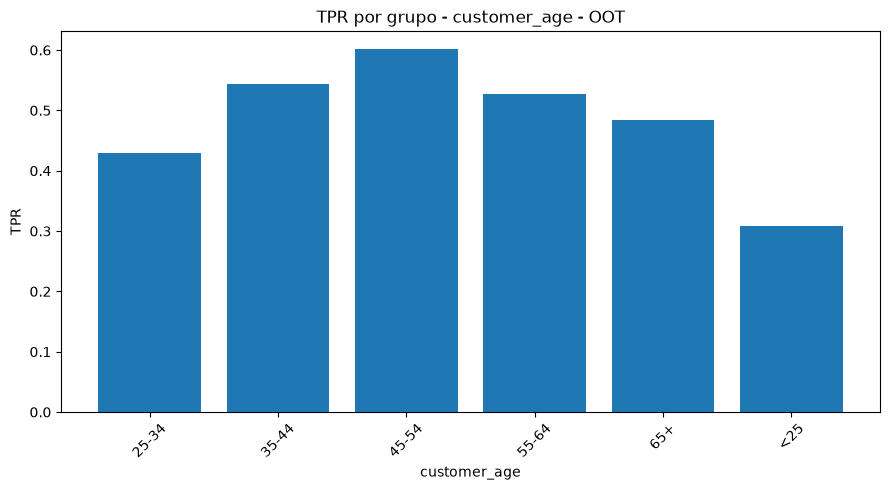

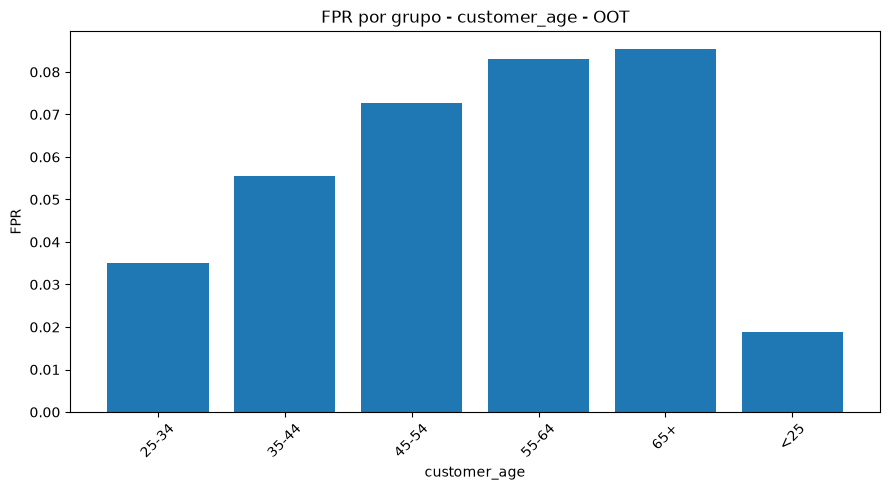

In [131]:
plot_fairness_metric(
    df_fairness_groups,
    "customer_age",
    "OOT",
    "TPR"
)

plot_fairness_metric(
    df_fairness_groups,
    "customer_age",
    "OOT",
    "FPR"
)

## Report

In [132]:
# ============================================================
# FAIRNESS REPORT - PDF
# Modelo candidato: LightGBM + WOE
# ============================================================

import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# 1. Configuración del reporte
# ============================================================

MODEL_NAME = "LightGBM + WOE"
THRESHOLD_REPORT = THRESHOLD_FINAL
PRIMARY_DATASET = "OOT"

report_dir = "../reports"
os.makedirs(report_dir, exist_ok=True)

pdf_path = os.path.join(
    report_dir,
    "fairness_report_lgbm_woe.pdf"
)

print(f"Modelo: {MODEL_NAME}")
print(f"Threshold: {THRESHOLD_REPORT:.4f}")
print(f"Dataset principal: {PRIMARY_DATASET}")

Modelo: LightGBM + WOE
Threshold: 0.8200
Dataset principal: OOT


In [133]:
# ============================================================
# 2. Funciones auxiliares
# ============================================================

def format_percent(value):
    if pd.isna(value):
        return "-"
    return f"{value:.2%}"


def format_number(value, decimals=4):
    if pd.isna(value):
        return "-"
    return f"{value:.{decimals}f}"


def format_int(value):
    if pd.isna(value):
        return "-"
    return f"{int(value):,}"


def wrap_text(text, width=95):
    return "\n".join(
        textwrap.wrap(
            str(text),
            width=width
        )
    )


def format_df_for_pdf(df):
    """
    Convierte las columnas del DataFrame a formatos
    más amigables para presentación.
    """

    df2 = df.copy()

    percentage_cols = [
        "base_rate",
        "selection_rate",
        "precision",
        "TPR",
        "FPR",
        "demographic_parity_diff",
        "equal_opportunity_diff",
        "fpr_gap",
        "equalized_odds_gap"
    ]

    integer_cols = [
        "n",
        "fraud_count"
    ]

    for col in df2.columns:

        if col in percentage_cols:
            df2[col] = df2[col].map(format_percent)

        elif col in integer_cols:
            df2[col] = df2[col].map(format_int)

        elif pd.api.types.is_numeric_dtype(df2[col]):
            df2[col] = df2[col].map(
                lambda x: format_number(x, 4)
            )

        else:
            df2[col] = df2[col].astype(str)

    return df2

In [134]:
def add_table_page(
    pdf,
    title,
    df,
    subtitle=None,
    notes=None,
    fontsize=7
):
    fig = plt.figure(
        figsize=(8.27, 11.69),
        dpi=150
    )

    fig.patch.set_facecolor("white")

    fig.text(
        0.5,
        0.95,
        title,
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

    if subtitle:
        fig.text(
            0.5,
            0.91,
            subtitle,
            ha="center",
            va="center",
            fontsize=9
        )

    ax = fig.add_axes(
        [0.05, 0.28, 0.90, 0.55]
    )

    ax.axis("off")

    table_df = format_df_for_pdf(df)

    table = ax.table(
        cellText=table_df.values,
        colLabels=table_df.columns,
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(1, 1.35)

    if notes:
        note_text = "\n".join(
            [f"- {wrap_text(note)}" for note in notes]
        )

        fig.text(
            0.07,
            0.17,
            "Interpretación:\n" + note_text,
            ha="left",
            va="top",
            fontsize=8
        )

    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

    plt.close(fig)

In [135]:
# ============================================================
# 3. Resumen ejecutivo OOT
# ============================================================

df_fairness_oot_summary = (
    df_fairness_metrics[
        df_fairness_metrics["dataset"] == PRIMARY_DATASET
    ]
    .copy()
    .reset_index(drop=True)
)

df_fairness_oot_summary = df_fairness_oot_summary[
    [
        "variable",
        "demographic_parity_diff",
        "disparate_impact_ratio",
        "equal_opportunity_diff",
        "fpr_gap",
        "equalized_odds_gap"
    ]
]

In [136]:
# ============================================================
# 4. Comparación temporal Test vs OOT
# ============================================================

df_fairness_temporal = (
    df_fairness_metrics[
        [
            "dataset",
            "variable",
            "demographic_parity_diff",
            "disparate_impact_ratio",
            "equal_opportunity_diff",
            "fpr_gap",
            "equalized_odds_gap"
        ]
    ]
    .copy()
    .sort_values(
        ["variable", "dataset"]
    )
    .reset_index(drop=True)
)

In [137]:
# ============================================================
# 5. Página individual por variable fairness
# ============================================================

def add_fairness_variable_page(
    pdf,
    variable,
    df_groups,
    df_metrics,
    dataset="OOT"
):
    group_df = df_groups[
        (df_groups["dataset"] == dataset)
        & (df_groups["variable"] == variable)
    ].copy()

    metric_df = df_metrics[
        (df_metrics["dataset"] == dataset)
        & (df_metrics["variable"] == variable)
    ].copy()

    if group_df.empty:
        return

    fig = plt.figure(
        figsize=(8.27, 11.69),
        dpi=150
    )

    fig.patch.set_facecolor("white")

    fig.text(
        0.5,
        0.95,
        f"Fairness - {variable}",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.915,
        f"{MODEL_NAME} | {dataset} | Threshold = {THRESHOLD_REPORT:.4f}",
        ha="center",
        va="center",
        fontsize=9
    )

    # --------------------------------------------------------
    # Tabla
    # --------------------------------------------------------

    table_cols = [
        "group",
        "n",
        "fraud_count",
        "base_rate",
        "selection_rate",
        "precision",
        "TPR",
        "FPR"
    ]

    table_df = format_df_for_pdf(
        group_df[table_cols]
    )

    ax_table = fig.add_axes(
        [0.04, 0.57, 0.92, 0.27]
    )

    ax_table.axis("off")

    table = ax_table.table(
        cellText=table_df.values,
        colLabels=table_df.columns,
        cellLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(6.5)
    table.scale(1, 1.25)

    # --------------------------------------------------------
    # TPR / FPR
    # --------------------------------------------------------

    ax_plot = fig.add_axes(
        [0.12, 0.29, 0.76, 0.20]
    )

    x = np.arange(
        len(group_df)
    )

    width = 0.35

    ax_plot.bar(
        x - width / 2,
        group_df["TPR"],
        width,
        label="TPR"
    )

    ax_plot.bar(
        x + width / 2,
        group_df["FPR"],
        width,
        label="FPR"
    )

    ax_plot.set_xticks(x)

    ax_plot.set_xticklabels(
        group_df["group"].astype(str),
        rotation=30,
        ha="right"
    )

    ax_plot.set_ylabel("Rate")

    ax_plot.set_title(
        "TPR y FPR por grupo"
    )

    ax_plot.legend()

    # --------------------------------------------------------
    # Métricas agregadas
    # --------------------------------------------------------

    if not metric_df.empty:

        row = metric_df.iloc[0]

        metric_text = (
            f"Demographic Parity Difference: "
            f"{row['demographic_parity_diff']:.2%}\n"
            f"Disparate Impact Ratio: "
            f"{row['disparate_impact_ratio']:.4f}\n"
            f"Equal Opportunity Difference: "
            f"{row['equal_opportunity_diff']:.2%}\n"
            f"FPR Gap: "
            f"{row['fpr_gap']:.2%}\n"
            f"Equalized Odds Gap: "
            f"{row['equalized_odds_gap']:.2%}"
        )

        fig.text(
            0.08,
            0.19,
            metric_text,
            fontsize=9,
            va="top"
        )

    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

    plt.close(fig)

### Proxy Analysis

In [138]:
# ============================================================
# 6. Proxy analysis OOT
# ============================================================

df_proxy_score_oot = (
    df_proxy_score[
        df_proxy_score["dataset"] == PRIMARY_DATASET
    ]
    .copy()
    .reset_index(drop=True)
)

df_proxy_sensitive_oot = (
    df_proxy_sensitive[
        df_proxy_sensitive["dataset"] == PRIMARY_DATASET
    ]
    .copy()
    .reset_index(drop=True)
)

df_proxy_groups_oot = (
    df_proxy_groups[
        df_proxy_groups["dataset"] == PRIMARY_DATASET
    ]
    .copy()
    .reset_index(drop=True)
)

In [139]:
if not df_proxy_score_oot.empty:

    df_proxy_score_report = (
        df_proxy_score_oot[
            [
                "variable",
                "metric",
                "value"
            ]
        ]
        .copy()
        .sort_values(
            "value",
            key=lambda x: x.abs(),
            ascending=False
        )
    )

In [140]:
if not df_proxy_sensitive_oot.empty:

    df_proxy_sensitive_report = (
        df_proxy_sensitive_oot[
            [
                "proxy",
                "sensitive_variable",
                "spearman_corr"
            ]
        ]
        .copy()
        .sort_values(
            "spearman_corr",
            key=lambda x: x.abs(),
            ascending=False
        )
    )

### PDF

In [141]:
# ============================================================
# 7. Crear PDF
# ============================================================

with PdfPages(pdf_path) as pdf:

    # ========================================================
    # PORTADA
    # ========================================================

    fig = plt.figure(
        figsize=(8.27, 11.69),
        dpi=150
    )

    fig.patch.set_facecolor("white")

    fig.text(
        0.5,
        0.78,
        "Fairness & Bias Audit",
        ha="center",
        fontsize=22,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.69,
        MODEL_NAME,
        ha="center",
        fontsize=15,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.62,
        f"Evaluación principal: {PRIMARY_DATASET}",
        ha="center",
        fontsize=11
    )

    fig.text(
        0.5,
        0.57,
        f"Threshold evaluado: {THRESHOLD_REPORT:.4f}",
        ha="center",
        fontsize=11
    )

    fig.text(
        0.5,
        0.48,
        "Variables auditadas:",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

    fig.text(
        0.5,
        0.43,
        "customer_age | income | employment_status",
        ha="center",
        fontsize=10
    )

    fig.text(
        0.5,
        0.34,
        "El reporte evalúa disparidad de resultados y posibles efectos proxy.",
        ha="center",
        fontsize=9
    )

    fig.text(
        0.5,
        0.28,
        "El threshold actual es provisional hasta completar la selección operacional.",
        ha="center",
        fontsize=8
    )

    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

    plt.close(fig)

    # ========================================================
    # RESUMEN OOT
    # ========================================================

    add_table_page(
        pdf,
        "Resumen ejecutivo de Fairness",
        df_fairness_oot_summary,
        subtitle=(
            f"{MODEL_NAME} | {PRIMARY_DATASET} | "
            f"Threshold = {THRESHOLD_REPORT:.4f}"
        ),
        notes=[
            "Demographic Parity Difference mide diferencias en la tasa de selección entre grupos.",
            "Equal Opportunity Difference mide diferencias en TPR o capacidad de detectar fraude real.",
            "FPR Gap mide diferencias en falsos positivos entre grupos.",
            "Equalized Odds considera conjuntamente las diferencias en TPR y FPR.",
            "Disparate Impact Ratio se utiliza como indicador descriptivo y no como criterio único de fairness."
        ]
    )

    # ========================================================
    # TEST VS OOT
    # ========================================================

    add_table_page(
        pdf,
        "Estabilidad temporal del Fairness",
        df_fairness_temporal,
        subtitle="Comparación Test vs OOT",
        notes=[
            "La comparación temporal permite identificar si las disparidades persisten fuera del periodo de evaluación inicial.",
            "Una disparidad presente tanto en Test como en OOT representa una señal más consistente que una diferencia aislada."
        ],
        fontsize=6.5
    )

    # ========================================================
    # FAIRNESS POR VARIABLE
    # ========================================================

    for variable in FAIRNESS_FEATURES:

        add_fairness_variable_page(
            pdf,
            variable,
            df_fairness_groups,
            df_fairness_metrics,
            dataset=PRIMARY_DATASET
        )

    # ========================================================
    # PROXY VS SCORE
    # ========================================================

    if not df_proxy_score_oot.empty:

        add_table_page(
            pdf,
            "Proxy Audit - Asociación con el score",
            df_proxy_score_report,
            subtitle=f"{MODEL_NAME} | {PRIMARY_DATASET}",
            notes=[
                "La correlación con el score no demuestra por sí sola que una variable sea un proxy problemático.",
                "Valores altos en magnitud indican que la variable merece una revisión adicional."
            ]
        )

    # ========================================================
    # PROXY VS VARIABLES FAIRNESS
    # ========================================================

    if not df_proxy_sensitive_oot.empty:

        add_table_page(
            pdf,
            "Proxy Audit - Asociación con variables sensibles",
            df_proxy_sensitive_report,
            subtitle=f"{MODEL_NAME} | {PRIMARY_DATASET}",
            notes=[
                "Esta sección analiza si variables utilizadas por el modelo están asociadas con características monitoreadas por fairness.",
                "credit_limit_income_ratio incorpora income por construcción, por lo que su asociación debe interpretarse teniendo en cuenta esta relación directa.",
                "La asociación estadística debe complementarse con el análisis de disparidad de resultados."
            ]
        )

    # ========================================================
    # CONCLUSIONES
    # ========================================================

    fig = plt.figure(
        figsize=(8.27, 11.69),
        dpi=150
    )

    fig.patch.set_facecolor("white")

    fig.text(
        0.5,
        0.91,
        "Conclusiones y próximos pasos",
        ha="center",
        fontsize=18,
        fontweight="bold"
    )

    conclusions = [
        "1. La auditoría principal se realiza sobre OOT para evaluar el comportamiento del modelo en un periodo futuro.",
        "2. customer_age se mantiene fuera del modelo y se utiliza exclusivamente para monitoreo de fairness.",
        "3. income y employment_status permanecen en el modelo, pero requieren seguimiento explícito de disparidad.",
        "4. Las diferencias de TPR y FPR son especialmente relevantes porque indican si determinados grupos reciben distinto nivel de protección o fricción.",
        "5. El proxy analysis identifica asociaciones que deben investigarse, pero una correlación no implica por sí sola discriminación.",
        "6. Los resultados deberán revisarse nuevamente cuando se defina el threshold operacional definitivo."
    ]

    y_pos = 0.80

    for line in conclusions:

        wrapped = wrap_text(
            line,
            width=90
        )

        fig.text(
            0.08,
            y_pos,
            wrapped,
            ha="left",
            va="top",
            fontsize=10
        )

        y_pos -= 0.09

    fig.text(
        0.08,
        0.16,
        "Siguiente etapa: revisar posibles medidas de mitigación y posteriormente realizar análisis de explicabilidad con SHAP.",
        fontsize=10,
        fontweight="bold",
        wrap=True
    )

    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

    plt.close(fig)


print(f"PDF generado correctamente en: {pdf_path}")

PDF generado correctamente en: ../reports\fairness_report_lgbm_woe.pdf


### Graficos

Grupos excluidos por baja representatividad:


,n
customer_age,
90,3


,rango_edad,n,fraud_rate_pct,selection_rate_pct
0,10-19,2930,0.44,1.60
1,20-29,21023,0.74,2.15
2,30-39,32363,1.25,4.00
3,40-49,27860,1.56,6.32
4,50-59,9725,2.63,8.67
5,60-69,2501,5.24,10.64
6,70-79,364,6.87,11.26
7,80-89,74,8.11,10.81


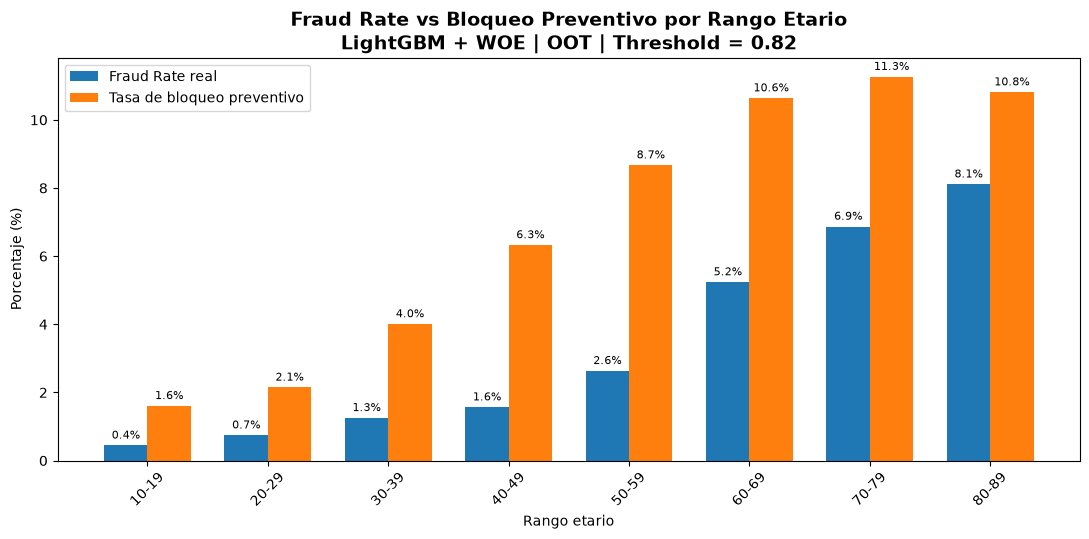

In [142]:
# ============================================================
# FAIRNESS - CUSTOMER AGE
# Fraud Rate vs Tasa de Bloqueo Preventivo
# OOT | LightGBM + WOE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

THRESHOLD_BLOQUEO = 0.82

df_fairness_age = df_score_oot[
    ["customer_age", "target", "score_lgbm_woe"]
].copy()

# Predicción operacional:
# 1 = Bloqueo preventivo automático
# 0 = No bloqueo automático
df_fairness_age["bloqueo_automatico"] = (
    df_fairness_age["score_lgbm_woe"] >= THRESHOLD_BLOQUEO
).astype(int)

# customer_age está representado por década:
# 20 = 20-29, 30 = 30-39, etc.
df_fairness_age["rango_edad"] = (
    df_fairness_age["customer_age"].astype(int).astype(str)
    + "-"
    + (df_fairness_age["customer_age"].astype(int) + 9).astype(str)
)

# Excluir grupos con muy baja representatividad para el análisis comparativo
MIN_OBSERVACIONES_GRUPO = 30

conteo_age = (
    df_fairness_age
    .groupby("customer_age")
    .size()
)

edades_validas = conteo_age[
    conteo_age >= MIN_OBSERVACIONES_GRUPO
].index

df_fairness_age_plot = df_fairness_age[
    df_fairness_age["customer_age"].isin(edades_validas)
].copy()

print("Grupos excluidos por baja representatividad:")
display(
    conteo_age[
        conteo_age < MIN_OBSERVACIONES_GRUPO
    ].rename("n").to_frame()
)

resumen_age = (
    df_fairness_age_plot
    .groupby(["customer_age", "rango_edad"], observed=False)
    .agg(
        n=("target", "size"),
        fraud_rate=("target", "mean"),
        selection_rate=("bloqueo_automatico", "mean")
    )
    .reset_index()
    .sort_values("customer_age")
)

# Pasamos a porcentaje para facilitar la lectura
resumen_age["fraud_rate_pct"] = resumen_age["fraud_rate"] * 100
resumen_age["selection_rate_pct"] = resumen_age["selection_rate"] * 100

display(
    resumen_age[
        ["rango_edad", "n", "fraud_rate_pct", "selection_rate_pct"]
    ].round(2)
)

# ============================================================
# GRÁFICA
# ============================================================

x = np.arange(len(resumen_age))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

bars_fraud = ax.bar(
    x - width / 2,
    resumen_age["fraud_rate_pct"],
    width,
    label="Fraud Rate real"
)

bars_block = ax.bar(
    x + width / 2,
    resumen_age["selection_rate_pct"],
    width,
    label="Tasa de bloqueo preventivo"
)

ax.set_title(
    "Fraud Rate vs Bloqueo Preventivo por Rango Etario\n"
    "LightGBM + WOE | OOT | Threshold = 0.82",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Rango etario")
ax.set_ylabel("Porcentaje (%)")
ax.set_xticks(x)
ax.set_xticklabels(resumen_age["rango_edad"], rotation=45)
ax.legend()

# Etiquetas
for bars in [bars_fraud, bars_block]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()
plt.show()

In [143]:
# ============================================================
# FAIRNESS METRICS - CUSTOMER AGE
# OOT | Bloqueo preventivo automático (score >= 0.82)
# ============================================================

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

MIN_OBSERVACIONES_GRUPO = 30

# Mantener únicamente grupos con suficiente representatividad
conteo_age = df_fairness_age.groupby("customer_age").size()

edades_validas = conteo_age[
    conteo_age >= MIN_OBSERVACIONES_GRUPO
].index

df_age_metricas = df_fairness_age[
    df_fairness_age["customer_age"].isin(edades_validas)
].copy()

# Etiqueta interpretable
df_age_metricas["rango_edad"] = (
    df_age_metricas["customer_age"].astype(int).astype(str)
    + "-"
    + (df_age_metricas["customer_age"].astype(int) + 9).astype(str)
)

resultados_age = []

for grupo, df_grupo in df_age_metricas.groupby("rango_edad"):

    y_true = df_grupo["target"]
    y_pred = df_grupo["bloqueo_automatico"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    selection_rate = y_pred.mean()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    resultados_age.append({
        "rango_edad": grupo,
        "n": len(df_grupo),
        "fraud_rate": y_true.mean(),
        "selection_rate": selection_rate,
        "TPR": tpr,
        "FPR": fpr,
        "precision": precision
    })

df_fairness_age_metricas = pd.DataFrame(resultados_age)

# Orden correcto de las décadas
df_fairness_age_metricas["edad_inicio"] = (
    df_fairness_age_metricas["rango_edad"]
    .str.split("-")
    .str[0]
    .astype(int)
)

df_fairness_age_metricas = (
    df_fairness_age_metricas
    .sort_values("edad_inicio")
    .drop(columns="edad_inicio")
    .reset_index(drop=True)
)

display(df_fairness_age_metricas)

,rango_edad,n,fraud_rate,selection_rate,TPR,FPR,precision
0,10-19,2930,0.004437,0.016041,0.230769,0.015084,0.063830
1,20-29,21023,0.007420,0.021453,0.314103,0.019265,0.108647
2,30-39,32363,0.012514,0.040046,0.429630,0.035109,0.134259
3,40-49,27860,0.015650,0.063245,0.543578,0.055608,0.134506
4,50-59,9725,0.026324,0.086684,0.601562,0.072764,0.182681
5,60-69,2501,0.052379,0.106357,0.526718,0.083122,0.259398
6,70-79,364,0.068681,0.112637,0.480000,0.085546,0.292683
7,80-89,74,0.081081,0.108108,0.500000,0.073529,0.375000


In [144]:
# ============================================================
# MÉTRICAS RESUMEN DE FAIRNESS
# ============================================================

selection_rates = df_fairness_age_metricas["selection_rate"]
tpr_rates = df_fairness_age_metricas["TPR"].dropna()
fpr_rates = df_fairness_age_metricas["FPR"].dropna()

demographic_parity_diff = (
    selection_rates.max()
    - selection_rates.min()
)

disparate_impact_ratio = (
    selection_rates.min()
    / selection_rates.max()
)

equal_opportunity_diff = (
    tpr_rates.max()
    - tpr_rates.min()
)

fpr_gap = (
    fpr_rates.max()
    - fpr_rates.min()
)

print("====================================================")
print("FAIRNESS - CUSTOMER AGE")
print("Bloqueo preventivo automático | OOT | Threshold 0.82")
print("====================================================")

print(f"Demographic Parity Difference : {demographic_parity_diff:.2%}")
print(f"Disparate Impact Ratio        : {disparate_impact_ratio:.4f}")
print(f"Equal Opportunity Difference  : {equal_opportunity_diff:.2%}")
print(f"FPR Gap                       : {fpr_gap:.2%}")

FAIRNESS - CUSTOMER AGE
Bloqueo preventivo automático | OOT | Threshold 0.82
Demographic Parity Difference : 9.66%
Disparate Impact Ratio        : 0.1424
Equal Opportunity Difference  : 37.08%
FPR Gap                       : 7.05%


# SHAP

In [145]:
# ============================================================
# SHAP - LIGHTGBM + WOE
# Explicabilidad global sobre OOT
# ============================================================

SHAP_SAMPLE_SIZE = 10_000
RANDOM_STATE = 150718

if len(X_oot_woe) > SHAP_SAMPLE_SIZE:
    X_shap = X_oot_woe.sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).copy()
else:
    X_shap = X_oot_woe.copy()

print(f"Observaciones OOT totales: {len(X_oot_woe):,}")
print(f"Observaciones utilizadas para SHAP: {len(X_shap):,}")
print(f"Variables: {X_shap.shape[1]}")

Observaciones OOT totales: 96,843
Observaciones utilizadas para SHAP: 10,000
Variables: 18


In [146]:
# ============================================================
# SHAP EXPLAINER
# ============================================================

explainer_shap = shap.TreeExplainer(lgbm_woe)

shap_values = explainer_shap(X_shap)

print("SHAP calculado correctamente.")
print("Shape:", shap_values.values.shape)

SHAP calculado correctamente.
Shape: (10000, 18)


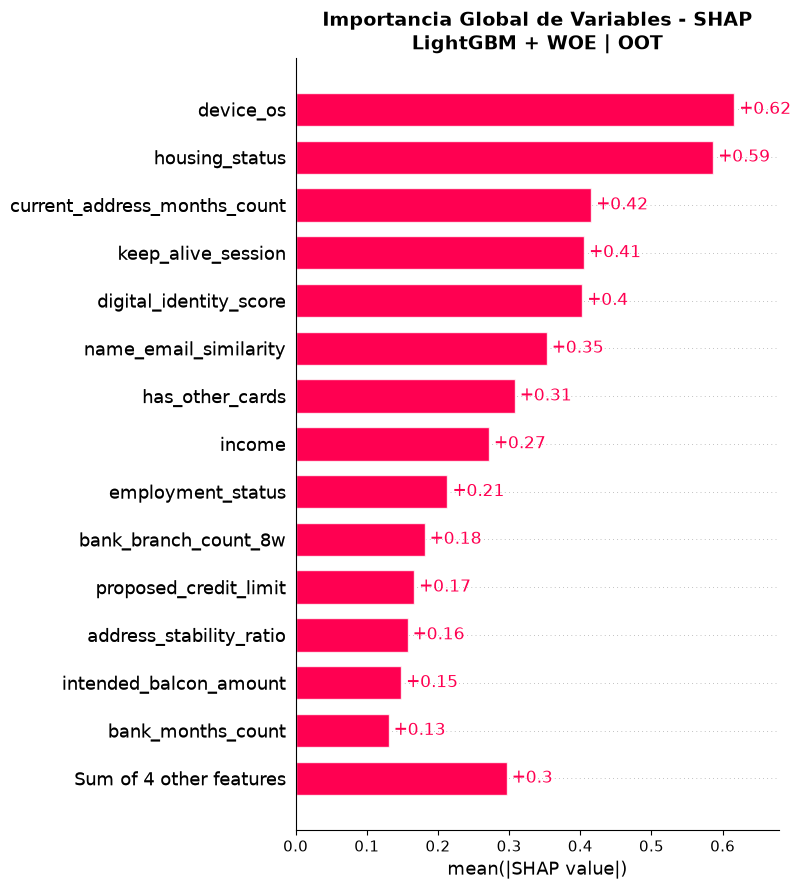

In [147]:
# ============================================================
# SHAP GLOBAL FEATURE IMPORTANCE
# ============================================================

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Importancia Global de Variables - SHAP\n"
    "LightGBM + WOE | OOT",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [148]:
# ============================================================
# TABLA DE IMPORTANCIA GLOBAL SHAP
# ============================================================

df_shap_importance = pd.DataFrame({
    "variable": X_shap.columns,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)
})

df_shap_importance = (
    df_shap_importance
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

df_shap_importance["importance_pct"] = (
    df_shap_importance["mean_abs_shap"]
    / df_shap_importance["mean_abs_shap"].sum()
)

display(
    df_shap_importance
    .head(15)
    .style.format({
        "mean_abs_shap": "{:.4f}",
        "importance_pct": "{:.2%}"
    })
)

,variable,mean_abs_shap,importance_pct
0,device_os,0.6161,13.25%
1,housing_status,0.5865,12.61%
2,current_address_months_count,0.4151,8.93%
3,keep_alive_session,0.4051,8.71%
4,digital_identity_score,0.4025,8.66%
5,name_email_similarity,0.3527,7.59%
6,has_other_cards,0.3078,6.62%
7,income,0.2714,5.84%
8,employment_status,0.2132,4.58%
9,bank_branch_count_8w,0.1811,3.90%


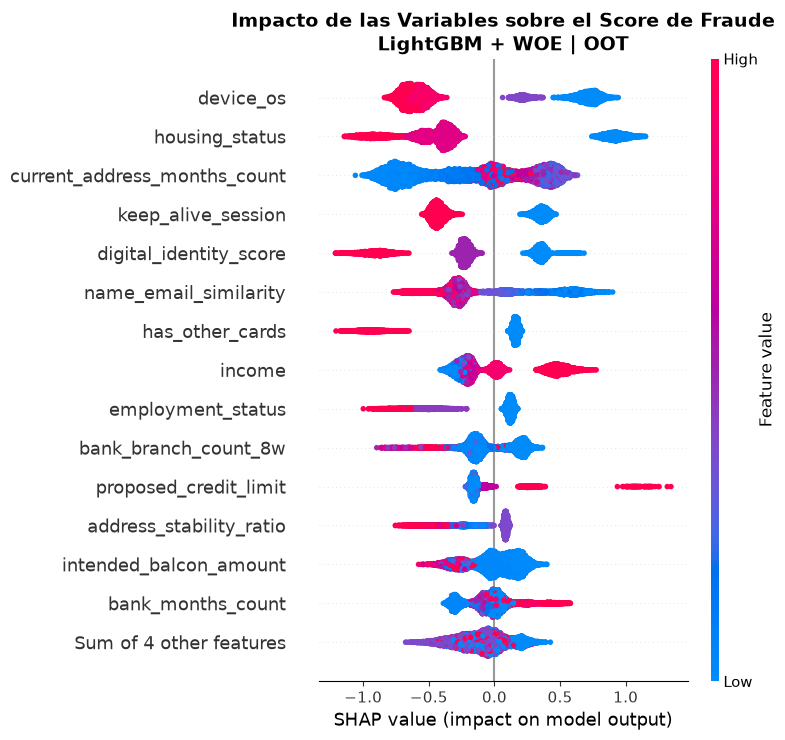

In [149]:
# ============================================================
# SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "Impacto de las Variables sobre el Score de Fraude\n"
    "LightGBM + WOE | OOT",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [150]:
# ============================================================
# RESUMEN SHAP GLOBAL
# ============================================================

df_shap_summary = pd.DataFrame({
    "variable": X_shap.columns,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0),
    "mean_shap": shap_values.values.mean(axis=0)
})

df_shap_summary["importance_pct"] = (
    df_shap_summary["mean_abs_shap"]
    / df_shap_summary["mean_abs_shap"].sum()
)

df_shap_summary = (
    df_shap_summary
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(
    df_shap_summary
    .head(15)
    .style.format({
        "mean_abs_shap": "{:.4f}",
        "mean_shap": "{:.4f}",
        "importance_pct": "{:.2%}"
    })
)

,variable,mean_abs_shap,mean_shap,importance_pct
0,device_os,0.6161,-0.2180,13.25%
1,housing_status,0.5865,-0.2135,12.61%
2,current_address_months_count,0.4151,-0.1872,8.93%
3,keep_alive_session,0.4051,-0.1528,8.71%
4,digital_identity_score,0.4025,-0.1797,8.66%
5,name_email_similarity,0.3527,-0.0812,7.59%
6,has_other_cards,0.3078,-0.0465,6.62%
7,income,0.2714,0.0139,5.84%
8,employment_status,0.2132,-0.0216,4.58%
9,bank_branch_count_8w,0.1811,-0.0347,3.90%
